# AIRSCOPE INDIA — Complete EDA with reliable output capture

**NIErmaya – DAV-26-080 · Delhi, India · SDG 13**

Run all cells in order. The first cell saves the real stdout, tables, PNG figures and interactive HTML of every subsequent cell inside the Python runtime before displaying them in the browser. This prevents a browser reconnect or Drive autosave conflict from losing the results. The final stage verifies all 28 embedded chart images and creates a separate fully executed notebook and results ZIP in a new timestamped Google Drive run folder.

Scientific rules are unchanged: preserve actual source histories, quarantine confirmed copies transparently, use observed data for primary results, retain genuine extremes, and distinguish association from causation.

In [50]:
# AirScope: capture actual cell outputs inside Python before browser transmission.
import base64 as _as_b64, zlib as _as_zlib, json as _as_json
import hashlib as _as_hashlib, traceback as _as_traceback, sys as _as_sys
from pathlib import Path as _AsPath
from contextlib import contextmanager as _as_contextmanager
from datetime import datetime as _AsDatetime, timezone as _as_timezone
from IPython import get_ipython as _as_get_ipython
from IPython.utils.capture import capture_output as _as_capture_output

_as_base = _as_json.loads(_as_zlib.decompress(_as_b64.b64decode('...')))
_as_expected_outputs = ['3e5f3945', '37c622cf', 'f25889d0', '2a35a6cc', '3445367a', 'f38cea79', '4a4d2ccd', '146e6aef', '2dfafed2', '8aacf616', 'c92da128', '9183d048', '2a1a3132', '52d761b0', 'f50db46b', 'bd35d3ff', '7cf6dd61', 'e5bcf8b1', '685905c1', '9e9aa203', '7cfb181d', 'c6791d64', 'aebf3906']
_as_code_cells = [c for c in _as_base['cells'] if c['cell_type'] == 'code']
_as_last_id = _as_code_cells[-1]['id']
for _as_cell in _as_code_cells:
    _as_original = _as_cell['source']
    _as_cell['source'] = 'with _airscope_capture(' + repr(_as_cell['id']) + '):\n' + ''.join('    ' + line + '\n' for line in _as_original.splitlines())
_as_count = len(_as_get_ipython().history_manager.input_hist_raw)-1
_as_boot_source = _as_get_ipython().history_manager.input_hist_raw[_as_count]
_as_boot_cell = dict(cell_type='code', id='airscope-capture-bootstrap', metadata={}, source=_as_boot_source, execution_count=_as_count, outputs=[])
_as_base['cells'].insert(1, _as_boot_cell)
_as_notebook = _as_base
_as_lookup = {c['id']:c for c in _as_notebook['cells'] if c['cell_type']=='code'}
_as_checkpoint_path = _AsPath('/content/airscope_capture/Complete_EDA.ipynb') if 'google.colab' in _as_sys.modules else _AsPath('work/airscope_capture/Complete_EDA.ipynb')
_as_records = []
_as_started = _AsDatetime.now(_as_timezone.utc).isoformat()

def _as_outputs(captured):
    outputs=[]
    if captured.stdout: outputs.append(dict(output_type='stream',name='stdout',text=captured.stdout))
    if captured.stderr: outputs.append(dict(output_type='stream',name='stderr',text=captured.stderr))
    for item in captured.outputs:
        outputs.append(dict(output_type='display_data',data=dict(item.data),metadata=dict(item.metadata)))
    return outputs

def _as_checkpoint():
    _as_checkpoint_path.parent.mkdir(parents=True,exist_ok=True)
    temporary=_as_checkpoint_path.with_suffix('.tmp')
    temporary.write_text(_as_json.dumps(_as_notebook,ensure_ascii=False),encoding='utf-8')
    temporary.replace(_as_checkpoint_path)

def _as_validate_outputs():
    import nbformat
    nbformat.validate(nbformat.from_dict(_as_notebook))
    cells=[c for c in _as_notebook['cells'] if c['cell_type']=='code']
    assert all(isinstance(c['execution_count'],int) for c in cells), 'Unexecuted code cell'
    assert not [o for c in cells for o in c['outputs'] if o['output_type']=='error'], 'Error output'
    missing=[cid for cid in _as_expected_outputs if not _as_lookup[cid]['outputs']]
    assert not missing, 'Missing expected outputs: '+str(missing)
    pngs=[o for c in cells for o in c['outputs'] if o.get('data',{}).get('image/png')]
    assert len(pngs)==28, 'Expected 28 actual chart image outputs; got '+str(len(pngs))
    html=[o for c in cells for o in c['outputs'] if o.get('data',{}).get('text/html')]
    assert any('plotly' in str(o['data']['text/html']).lower() for o in html), 'Missing interactive Plotly output'
    return dict(code_cells=len(cells),executed_cells=len(cells),error_outputs=0,embedded_PNG_charts=len(pngs),HTML_outputs=len(html),expected_output_cells=len(_as_expected_outputs),missing_expected_outputs=missing)

def _as_finalize():
    # Called only after the last real cell output has been captured and persisted.
    import shutil, zipfile, hashlib
    from googleapiclient.http import MediaFileUpload
    summary=_as_validate_outputs()
    evidence=dict(engine='Live Google Colab with per-cell Python output capture',started_utc=_as_started,completed_utc=_AsDatetime.now(_as_timezone.utc).isoformat(),**summary,cells=_as_records)
    _as_notebook['metadata']['airscope_execution']=evidence
    _as_checkpoint()
    notebook_path=OUT/'notebooks/Complete_EDA.ipynb'
    shutil.copy2(_as_checkpoint_path,notebook_path)
    record_path=OUT/'documentation/Notebook_Output_Validation.json'
    record_path.write_text(_as_json.dumps(evidence,indent=2))
    scientific=_as_json.loads((OUT/'documentation/Final_Validation.json').read_text())
    assert scientific['checks_passed']==scientific['checks_total']
    print('FULL NOTEBOOK OUTPUTS VERIFIED:',summary)
    archive=export_project_zip(include_originals=INCLUDE_ORIGINALS)
    with zipfile.ZipFile(archive) as z:
        assert z.testzip() is None
        archived=_as_json.loads(z.read('AirScope_India/notebooks/Complete_EDA.ipynb'))
        assert sum('image/png' in o.get('data',{}) for c in archived['cells'] if c['cell_type']=='code' for o in c['outputs'])==28
    # A new run folder preserves every earlier release. Its notebook carries all MIME outputs.
    saved=save_results_to_drive(archive)
    receipt=_as_json.loads((OUT/'documentation/Drive_Save_Receipt.json').read_text())
    for path,mime in [(notebook_path,'application/x-ipynb+json'),(record_path,'application/json')]:
        request=drive_service.files().create(body={'name':path.name,'parents':[receipt['folder_id']]},media_body=MediaFileUpload(str(path),mimetype=mime,resumable=True,chunksize=1024**2),fields='id,name,size,md5Checksum,webViewLink',supportsAllDrives=True)
        response=None
        while response is None: _,response=request.next_chunk(num_retries=5)
        with path.open('rb') as stream: digest=hashlib.file_digest(stream,'md5').hexdigest()
        assert int(response['size'])==path.stat().st_size and response['md5Checksum']==digest
        receipt['files'].append(response)
        print('Saved and verified:',path.name,response['webViewLink'])
    receipt['notebook_output_validation']=summary
    receipt_path=OUT/'documentation/Drive_Save_Receipt.json'
    receipt_path.write_text(_as_json.dumps(receipt,indent=2))
    existing=[x for x in drive_children(receipt['folder_id']) if x['name']==receipt_path.name]
    assert len(existing)==1
    drive_service.files().update(fileId=existing[0]['id'],media_body=MediaFileUpload(str(receipt_path),mimetype='application/json'),fields='id',supportsAllDrives=True).execute()
    print('FULLY EXECUTED NOTEBOOK AND RESULTS SAVED: https://drive.google.com/drive/folders/'+receipt['folder_id'])

@_as_contextmanager
def _airscope_capture(cell_id):
    cell=_as_lookup[cell_id]
    capture=_as_capture_output(stdout=True,stderr=True,display=True)
    started=_AsDatetime.now(_as_timezone.utc).isoformat()
    failure=None; failure_tb=None
    try:
        with capture as captured: yield
    except BaseException as exc:
        failure=exc; failure_tb=exc.__traceback__
    cell['execution_count']=len(_as_get_ipython().history_manager.input_hist_raw)-1
    cell['outputs']=_as_outputs(captured)
    if failure is not None:
        cell['outputs'].append(dict(output_type='error',ename=type(failure).__name__,evalue=str(failure),traceback=_as_traceback.format_exception(type(failure),failure,failure_tb)))
    record=dict(cell_id=cell_id,execution_count=cell['execution_count'],started_utc=started,completed_utc=_AsDatetime.now(_as_timezone.utc).isoformat(),source_sha256=_as_hashlib.sha256(cell['source'].encode()).hexdigest(),outputs=len(cell['outputs']))
    cell['metadata']['airscope_capture']=record
    _as_records.append(record)
    _as_checkpoint()
    captured.show()
    if failure is not None: raise failure.with_traceback(failure_tb)
    if cell_id==_as_last_id and globals().get('IN_COLAB',False) and globals().get('AUTO_SAVE_TO_DRIVE',False):
        _as_finalize()

with _as_capture_output(stdout=True,stderr=True,display=True) as _as_initial_capture:
    print('Reliable output capture ready. Every cell is saved inside Python before browser display.')
_as_boot_cell['outputs']=_as_outputs(_as_initial_capture)
_as_checkpoint()
_as_initial_capture.show()

Reliable output capture ready. Every cell is saved inside Python before browser display.


## 1. Install and import dependencies

Colab installs the necessary public Python packages. A local run uses already installed compatible packages, installing only if modules are missing. Package versions are recorded with the results. A full corpus may take several minutes and multiple gigabytes of disk/RAM; use Drive for large inputs.

In [51]:
with _airscope_capture('3e5f3945'):
    import os, sys, importlib.util, subprocess
    from pathlib import Path
    IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") is not None else False
    PACKAGES = ["google-api-python-client>=2.100", "google-auth>=2.20", "numpy>=1.26", "pandas>=2.2", "matplotlib>=3.8", "seaborn>=0.13", "scipy>=1.11", "statsmodels>=0.14", "plotly>=5.20", "pyarrow>=15", "geopandas>=1.0", "shapely>=2.0", "folium>=0.16", "openpyxl>=3.1", "reportlab>=4", "pypdf>=4", "pypdfium2>=4", "nbformat>=5", "nbclient>=0.10", "ipykernel>=6"]
    MODULES = ["numpy","pandas","matplotlib","seaborn","scipy","statsmodels","plotly","pyarrow","geopandas","shapely","folium","openpyxl","reportlab","pypdf","pypdfium2","nbformat","nbclient","ipykernel"]
    if IN_COLAB or any(importlib.util.find_spec(x) is None for x in MODULES):
        subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*PACKAGES])
    print("Dependencies ready. Google Colab:", IN_COLAB)


Dependencies ready. Google Colab: True


## 2. Connect Drive and automatically load the preserved inputs

**No manual uploads or path edits are needed for the configured account.** Sign into the Google account with Editor access to the linked `NIErnaya_data` folder when Colab requests authentication. The default path is `/content/drive/MyDrive/NIErnaya_data`; the explicit folder ID also supports a moved or nested folder.

The notebook automatically downloads the complete project archive or numbered archive parts, verifies downloads against Drive checksums, and extracts only `data/original/` into local Colab storage. These preserved inputs contain the complete `Weather 2017-2026/`, `Pollutants 2017-2026/`, `Population (5 Years)/`, `delhi_air_project/` folders and `All from 1985 - 2024.xlsx`. Keep every numbered part together in Drive. Cleaned/generated results are never treated as raw inputs.

If those archives are absent, all five extracted inputs must exist at `DRIVE_DATA_DIR`. For another account/folder, change `DRIVE_FOLDER_ID` and optionally `DRIVE_DATA_DIR`. Small custom datasets can still use `INPUT_MODE="upload"`. Local execution continues to use `AIRSCOPE_DATA_ROOT` and `AIRSCOPE_OUTPUT_ROOT`. Outputs remain outside the source root.

In [52]:
with _airscope_capture('37c622cf'):
    import zipfile, stat, shutil, io, hashlib, json
    INPUT_MODE = "drive"
    DRIVE_DATA_DIR = "/content/drive/MyDrive/NIErnaya_data"
    # This is the writable folder ID in the visible text of the supplied link.
    DRIVE_FOLDER_ID = "1A2uE9l5LWs_rpsoW1ORmGnJxIkw6X5sH"
    AUTO_SAVE_TO_DRIVE = True
    MAX_UNCOMPRESSED_BYTES = 8 * 1024**3
    BUNDLE_NAME = "AirScope_India_Complete_Project.zip"
    REQUIRED_INPUTS = ["Weather 2017-2026", "Pollutants 2017-2026",
                       "Population (5 Years)", "delhi_air_project", "All from 1985 - 2024.xlsx"]
    
    def drive_children(parent):
        items = []; token = None
        while True:
            response = drive_service.files().list(
                q=f"'{parent}' in parents and trashed = false", pageSize=1000,
                fields="nextPageToken,files(id,name,mimeType,size,md5Checksum)",
                pageToken=token, supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
            items.extend(response.get("files", [])); token = response.get("nextPageToken")
            if not token: return items
    
    def download_drive_file(item, destination):
        from googleapiclient.http import MediaIoBaseDownload
        destination = Path(destination); destination.parent.mkdir(parents=True, exist_ok=True)
        def matches(p):
            if not p.exists() or p.stat().st_size != int(item["size"]): return False
            if not item.get("md5Checksum"): return True
            with p.open("rb") as stream: return hashlib.file_digest(stream, "md5").hexdigest() == item["md5Checksum"]
        if matches(destination): return destination
        mounted_source = Path(DRIVE_DATA_DIR) / item["name"]
        if mounted_source.is_file():
            shutil.copy2(mounted_source, destination)
            if matches(destination): return destination
            destination.unlink()
        temporary = destination.with_name(destination.name + ".downloading")
        with temporary.open("wb") as stream:
            downloader = MediaIoBaseDownload(stream, drive_service.files().get_media(
                fileId=item["id"], supportsAllDrives=True), chunksize=1024**2)
            done = False
            while not done: _, done = downloader.next_chunk(num_retries=5)
        temporary.replace(destination)
        if not matches(destination):
            destination.unlink(); raise IOError("Drive download size/checksum mismatch: " + item["name"])
        return destination
    
    def stage_preserved_bundle():
        # Downloads the supplied complete archive (or its ordered transport parts).
        # Only the byte-preserved original sources are extracted for discovery.
        items = drive_children(DRIVE_FOLDER_ID)
        whole = [x for x in items if x["name"] == BUNDLE_NAME]
        parts = sorted([x for x in items if x["name"].startswith(BUNDLE_NAME + ".part")], key=lambda x:x["name"])
        cache = Path("/content/airscope_downloads"); cache.mkdir(exist_ok=True)
        archive = cache / BUNDLE_NAME
        if whole:
            if len(whole) != 1: raise ValueError("Duplicate project archives in Drive; keep one current archive.")
            download_drive_file(whole[0], archive)
        elif parts:
            expected = [BUNDLE_NAME + f".part{i:02d}" for i in range(1,len(parts)+1)]
            if [x["name"] for x in parts] != expected: raise ValueError("Missing or duplicate archive parts in Drive.")
            downloaded = [download_drive_file(x,cache/x["name"]) for x in parts]
            with archive.open("wb") as dst:
                for part in downloaded:
                    with part.open("rb") as src: shutil.copyfileobj(src,dst,32*1024**2)
        else:
            raise FileNotFoundError("No complete project archive/parts in the configured Drive folder.")
        target = Path("/content/airscope_inputs"); target.mkdir(exist_ok=True)
        prefix = "AirScope_India/data/original/"; used = 0; count = 0
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                if not member.filename.startswith(prefix) or member.is_dir(): continue
                name = member.filename[len(prefix):].replace("\\", "/")
                candidate = (target/name).resolve()
                if not candidate.is_relative_to(target.resolve()) or Path(name).is_absolute(): raise ValueError("Unsafe source path")
                if stat.S_ISLNK(member.external_attr >> 16): raise ValueError("Archive symlink")
                if any(x in {".venv", ".git", "__pycache__", "node_modules"} for x in Path(name).parts) or Path(name).name in {".env", ".DS_Store"}: continue
                used += member.file_size
                if used > MAX_UNCOMPRESSED_BYTES: raise ValueError("Source archive quota exceeded")
                candidate.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as src, candidate.open("wb") as dst: shutil.copyfileobj(src,dst)
                count += 1
        if not count: raise ValueError("The project archive contains no original source files")
        print("Automatically staged preserved source files:", count)
        return target
    
    def extract_nested_zips(root):
        root = Path(root).resolve()
        seen = set(); used = 0; archive_log = []
        while True:
            archives = [p for p in root.rglob("*.zip") if p.resolve() not in seen and ".venv" not in p.parts]
            if not archives: break
            for archive in archives:
                seen.add(archive.resolve()); target = archive.parent / (archive.stem + "_extracted")
                target.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(archive) as z:
                    for member in z.infolist():
                        name = member.filename.replace("\\", "/")
                        candidate = (target / name).resolve()
                        if not candidate.is_relative_to(target.resolve()) or Path(name).is_absolute():
                            raise ValueError("Unsafe archive path: " + name)
                        if stat.S_ISLNK(member.external_attr >> 16):
                            raise ValueError("Archive symlinks are not extracted: " + name)
                        if any(x in {".venv","__pycache__",".git","node_modules"} or x.startswith("AirScope_India") for x in Path(name).parts) or Path(name).name in {".env",".DS_Store"}: continue
                        used += member.file_size
                        if used > MAX_UNCOMPRESSED_BYTES: raise ValueError("Archive quota exceeded; use Drive with extracted folders.")
                        if member.is_dir(): candidate.mkdir(parents=True, exist_ok=True)
                        else:
                            candidate.parent.mkdir(parents=True, exist_ok=True)
                            with z.open(member) as src, candidate.open("wb") as dst: shutil.copyfileobj(src,dst)
                archive_log.append({"archive":str(archive.relative_to(root)),"total_uncompressed_bytes_so_far":used})
        return archive_log
    
    
    
    
    
    
    
    
    if IN_COLAB:
        if INPUT_MODE == "drive":
            from google.colab import drive, auth
            drive.mount("/content/drive")
            auth.authenticate_user()
            import google.auth
            from googleapiclient.discovery import build
            credentials, _ = google.auth.default()
            drive_service = build("drive", "v3", credentials=credentials, cache_discovery=False)
            folder = drive_service.files().get(fileId=DRIVE_FOLDER_ID,
                fields="id,name,mimeType,capabilities(canAddChildren)", supportsAllDrives=True).execute()
            if folder["mimeType"] != "application/vnd.google-apps.folder": raise ValueError("Configured Drive ID is not a folder")
            if AUTO_SAVE_TO_DRIVE and not folder.get("capabilities",{}).get("canAddChildren",False):
                raise PermissionError("Sign into the Drive account with Editor access to NIErnaya_data.")
            mounted = Path(DRIVE_DATA_DIR)
            # Prefer the ID-verified preserved archive, independent of folder moves or duplicate names.
            names = [x["name"] for x in drive_children(DRIVE_FOLDER_ID)]
            if BUNDLE_NAME in names or any(x.startswith(BUNDLE_NAME + ".part") for x in names):
                input_root = stage_preserved_bundle()
            elif all((mounted/name).exists() for name in REQUIRED_INPUTS):
                input_root = mounted
            else:
                raise FileNotFoundError("Expected the project archive/parts in the linked folder, or all five inputs at " + DRIVE_DATA_DIR)
        elif INPUT_MODE == "upload":
            from google.colab import files
            input_root = Path("/content/airscope_inputs"); input_root.mkdir(parents=True,exist_ok=True)
            uploaded = files.upload()
            for name, content in uploaded.items():
                if Path(name).name != name: raise ValueError("Upload a ZIP to preserve nested paths.")
                (input_root/name).write_bytes(content)
            del uploaded
        else: raise ValueError("INPUT_MODE must be upload or drive.")
        archive_log = extract_nested_zips(input_root)
        os.environ["AIRSCOPE_DATA_ROOT"] = str(input_root)
        os.environ["AIRSCOPE_OUTPUT_ROOT"] = "/content/AirScope_India_Full_Outputs"
    else:
        if "AIRSCOPE_DATA_ROOT" not in os.environ: raise RuntimeError("Set AIRSCOPE_DATA_ROOT, or run in Colab.")
        archive_log = []
    root_path = Path(os.environ["AIRSCOPE_DATA_ROOT"]).resolve()
    output_path = Path(os.environ.get("AIRSCOPE_OUTPUT_ROOT", "AirScope_India")).resolve()
    if root_path == output_path or output_path.is_relative_to(root_path): raise ValueError("Keep output outside input root")
    print("Input ready:", root_path, "| nested archives inspected:", len(archive_log))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Automatically staged preserved source files: 580
Input ready: /content/airscope_inputs | nested archives inspected: 0


## Configuration

The analysis uses a fixed seed and separate raw, cleaned, imputed and processed layers.

In [53]:
with _airscope_capture('740633c3'):
    from pathlib import Path
    import os, sys, re, json, hashlib, shutil, zipfile, stat, warnings, math, gc
    os.environ.setdefault('MPLCONFIGDIR',str(Path.cwd()/'work/mplconfig'))
    os.environ.setdefault('XDG_CACHE_HOME',str(Path.cwd()/'work/cache'))
    from collections import Counter, defaultdict
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    import seaborn as sns
    from scipy import stats
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from statsmodels.stats.multitest import multipletests
    import plotly.express as px
    import plotly.graph_objects as go
    import geopandas as gpd
    from shapely.geometry import Point
    import shapely
    from IPython.display import display, Markdown, Image, HTML
    
    SEED=26080
    RNG=np.random.default_rng(SEED)
    START=pd.Timestamp('2017-01-01'); END=pd.Timestamp('2026-10-31 23:00')
    SEASONS=['Winter','Summer','Monsoon','Post-monsoon']
    COLORS=['#14566f','#de873c','#278d8b','#a44a55','#70678b','#759d54']
    plt.rcParams.update({'figure.dpi':115,'savefig.dpi':190,'font.family':'DejaVu Sans',
     'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold',
     'axes.titlepad':15,'axes.labelcolor':'#203946','text.color':'#203946',
     'axes.prop_cycle':matplotlib.cycler(color=COLORS),'grid.alpha':.17})
    sns.set_theme(style='whitegrid',palette=COLORS,rc=plt.rcParams)
    DATA_ROOT=Path(os.environ['AIRSCOPE_DATA_ROOT']).resolve()
    OUT=Path(os.environ.get('AIRSCOPE_OUTPUT_ROOT','AirScope_India')).resolve()
    COPY_ORIGINALS=True
    SHOW_FIGURES=True
    FIGURES=[]; FINDINGS=[]; CHECKS=[]
    for d in ['notebooks','src','data/original','data/cleaned/pollutants','data/cleaned/weather',
              'data/imputed','data/processed/hourly','data/processed/weather','data/processed/tables',
              'visualizations/temporal','visualizations/pollution','visualizations/weather',
              'visualizations/spatial','visualizations/statistical','reports','documentation']:
        (OUT/d).mkdir(parents=True,exist_ok=True)
    
    def save_table(df,name):
        df.to_csv(OUT/'data/processed/tables'/f'{name}.csv',index=False)
        return df
    
    def dump(obj,path):
        (OUT/path).write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if hasattr(x,'item') else str(x)))
    
    def check(name,condition,detail=''):
        CHECKS.append({'check':name,'passed':bool(condition),'detail':str(detail)})
        if not condition:raise AssertionError(name+': '+str(detail))
    
    def season(month):
        return pd.Series(np.select([month.isin([12,1,2]),month.isin([3,4,5]),month.isin([6,7,8,9])],SEASONS[:3],default=SEASONS[3]),index=month.index)
    
    def time_features(df,col='timestamp'):
        t=df[col];df['year']=t.dt.year;df['month']=t.dt.month;df['hour']=t.dt.hour
        df['weekday']=t.dt.day_of_week;df['weekend']=df.weekday>=5
        df['season']=season(df.month);return df
    
    def figure(fig,name,title,caption,category='temporal'):
        fig.set_facecolor('white')
        fig.suptitle(title,fontsize=17,fontweight='bold',x=.03,ha='left',y=.995)
        fig.text(.015,.012,caption,fontsize=8,color='#566e79',va='bottom',wrap=True)
        fig.tight_layout(rect=[0,.075,1,.945])
        path=OUT/'visualizations'/category/f'{name}.png'
        fig.savefig(path,bbox_inches='tight');fig.savefig(path.with_suffix('.svg'),bbox_inches='tight')
        FIGURES.append({'id':name,'title':title,'caption':caption,'path':str(path.relative_to(OUT)),'category':category})
        plt.close(fig)
        if SHOW_FIGURES:display(Image(filename=str(path),width=980))
    
    def finding(question,evidence,period,fig,interpretation,limitation,parameters):
        FINDINGS.append(dict(id=len(FINDINGS)+1,question=question,parameters=parameters,evidence=evidence,
            timeline=period,visualization=fig,interpretation=interpretation,environmental_significance=interpretation,limitations=limitation))
    
    def eligible_path(p):
        parts=p.relative_to(DATA_ROOT).parts
        return not any(x in {'.venv','__pycache__','.git','node_modules'} or x.startswith('AirScope_India') for x in parts) and p.name not in {'.env','.DS_Store'} and not (p.is_file() and p.suffix.lower()=='.zip')


In [54]:
with _airscope_capture('f25889d0'):
    print("Project folders and plotting style initialized.")


Project folders and plotting style initialized.


## 3. Recursive discovery and preservation

Every nested input folder is enumerated. Software, secrets and prior outputs are excluded explicitly; non-secret project sources are copied with SHA-256 provenance.

In [55]:
with _airscope_capture('475137f5'):
    def discover():
        # Extraction is handled by the upload cell; every input directory is traversed.
        files=sorted(p for p in DATA_ROOT.rglob('*') if p.is_file())
        records=[]; hashes=defaultdict(list)
        for p in files:
            rel=str(p.relative_to(DATA_ROOT));include=eligible_path(p)
            reason='' if include else 'Archive container expanded separately; not copied wholesale to avoid bundled software/secrets' if p.suffix.lower()=='.zip' else 'Software/generated results, OS metadata or secret configuration; not a source observation'
            r={'path':rel,'bytes':p.stat().st_size,'format':p.suffix.lower(),'included':include,'exclusion_reason':reason}
            if include:
                h=hashlib.sha256()
                with p.open('rb') as f:
                    for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
                r['sha256']=h.hexdigest();hashes[r['sha256']].append(rel)
                if COPY_ORIGINALS:
                    dest=OUT/'data/original'/rel;dest.parent.mkdir(parents=True,exist_ok=True)
                    if not dest.exists() or dest.stat().st_size!=p.stat().st_size:shutil.copy2(p,dest)
            records.append(r)
        mf=pd.DataFrame(records);mf.to_csv(OUT/'documentation/Execution_Source_Manifest.csv',index=False)
        dump([{'sha256':h,'paths':p} for h,p in hashes.items() if len(p)>1],'documentation/Execution_Exact_Duplicates.json')
        # Match the supplied families anywhere beneath a ZIP's wrapper directory.
        families={}
        for name in ['Pollutants 2017-2026','Weather 2017-2026','Population (5 Years)','delhi_air_project']:
            candidates=[p for p in DATA_ROOT.rglob(name) if p.is_dir() and eligible_path(p)]
            if DATA_ROOT.name==name:candidates=[DATA_ROOT]
            check('One input folder: '+name,len(candidates)==1,[str(p) for p in candidates])
            families[name]=candidates[0]
        books=[p for p in DATA_ROOT.rglob('All from 1985 - 2024.xlsx') if eligible_path(p)]
        check('One emissions workbook',len(books)==1,len(books));families['emissions']=books[0]
        dump({'inspected_files':int(mf.included.sum()),'enumerated_files':len(mf),'families':{k:str(v.relative_to(DATA_ROOT)) for k,v in families.items()}},'documentation/Execution_Discovery.json')
        print(f'Recursively enumerated {len(mf):,} files; preserved {int(mf.included.sum()):,} project sources.')
        return families,mf


In [56]:
with _airscope_capture('2a35a6cc'):
    families, manifest = discover()
    dump(archive_log,"documentation/Archive_Extraction_Log.json")
    display(manifest[manifest.included].groupby("format").agg(files=("path","count"),bytes=("bytes","sum")))


Recursively enumerated 580 files; preserved 580 project sources.


,files,bytes
format,,
.csv,555,1013536554
.example,1,36
.geojson,4,322716485
.html,3,19953162
.json,3,59528314
.md,1,2495
.py,11,22588
.txt,1,113
.xlsx,1,16249


## 3b. Complete source schemas, profiles and sample records

Every research CSV is read in full, every workbook sheet and geographic layer is inspected, and both acquisition caches are parsed. Export complete dimensions, parameters, types, ranges, missingness, samples and actual date coverage; failures are explicit.

In [57]:
with _airscope_capture('dbfd6c5b'):
    def inspect_all_datasets(manifest):
        inventory=[];profiles=[];samples=[];metadata=[];errors=[]
        def profile(df,p,family,sheet=''):
            path=str(p.relative_to(DATA_ROOT));n=len(df)
            for c in df.select_dtypes(include=['object']):
                if df[c].map(lambda x:isinstance(x,(dict,list))).any():df[c]=df[c].map(lambda x:json.dumps(x,sort_keys=True) if isinstance(x,(dict,list)) else x)
            datecol=next((c for c in df if str(c).lower() in ['timestamp','time','acq_date','date']),None)
            dates=pd.to_datetime(df[datecol],errors='coerce',format='mixed') if datecol else None
            start=dates.min() if dates is not None else '';end=dates.max() if dates is not None else '';resolution='static/context'
            if dates is not None and dates.notna().any():
                dif=dates.dropna().drop_duplicates().sort_values().diff().dropna();resolution=str(dif.mode().iloc[0]) if len(dif) else 'single date'
            if family=='population':start=end=re.search(r'20\d{2}',p.stem).group();resolution='single spatial epoch'
            if family=='emissions':
                years=sorted({int(str(c)[-4:]) for c in df if str(c).startswith('EMI_')});start=min(years);end=max(years);resolution='selected inventory epochs'
            if p.name.startswith('firms_region'):resolution='satellite detections; date + HHMM UTC; two seasonal windows'
            inventory.append({'path':path,'sheet':sheet,'family':family,'format':p.suffix,'rows':n,'columns':len(df.columns),'parameters':' | '.join(map(str,df.columns)),'start':start,'end':end,'resolution':resolution,'missing_pct':100*df.isna().to_numpy().mean() if n else None,'duplicate_rows':int(df.duplicated().sum())})
            for c in df:
                s=df[c];num=pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
                v={'path':path,'sheet':sheet,'family':family,'column':str(c),'dtype':str(s.dtype),'rows':n,'nonmissing':int(s.notna().sum()),'missing_pct':100*s.isna().mean() if n else None,'unique':int(s.nunique())}
                if num and s.notna().any():v.update(minimum=s.min(),maximum=s.max(),mean=s.mean(),median=s.median(),std=s.std(),p01=s.quantile(.01),p99=s.quantile(.99),skew=s.skew(),kurtosis_excess=s.kurt(),negative=int((s<0).sum()),zero=int((s==0).sum()))
                if dates is not None and s.notna().any():v.update(first_valid=dates[s.notna()].min(),last_valid=dates[s.notna()].max())
                profiles.append(v)
            samples.append({'path':path,'sheet':sheet,'records':json.loads(df.head(3).to_json(orient='records',date_format='iso'))})
        for _,m in manifest[manifest.included].iterrows():
            p=DATA_ROOT/m.path;parts=p.relative_to(DATA_ROOT).parts
            family='pollutants' if 'Pollutants 2017-2026' in parts else 'weather' if 'Weather 2017-2026' in parts else 'population' if 'Population (5 Years)' in parts else 'emissions' if p.suffix.lower() in ['.xls','.xlsx'] else 'supporting'
            try:
                if p.suffix.lower()=='.csv':profile(pd.read_csv(p,low_memory=False),p,family)
                elif p.suffix.lower() in ['.xlsx','.xls']:
                    book=pd.ExcelFile(p)
                    for sheet in book.sheet_names:profile(pd.read_excel(book,sheet_name=sheet),p,family,sheet)
                elif p.suffix.lower() in ['.json','.geojson']:
                    obj=json.loads(p.read_text());info={'path':m.path,'top_type':type(obj).__name__}
                    if isinstance(obj,dict) and obj.get('type')=='FeatureCollection':
                        features=obj['features'];profile(pd.DataFrame([x.get('properties',{}) for x in features]),p,'spatial')
                        info.update(features=len(features),geometry_types=dict(Counter((x.get('geometry') or {}).get('type') for x in features)),crs=obj.get('crs'))
                    elif isinstance(obj,dict) and 'elements' in obj:
                        elems=obj['elements'];keys=sorted({k for x in elems for k in x});info.update(elements=len(elems),element_types=dict(Counter(x.get('type') for x in elems)),acquisition_metadata=obj.get('osm3s'))
                        inventory.append({'path':m.path,'family':'acquisition cache','format':'.json','rows':len(elems),'columns':len(keys),'parameters':' | '.join(keys),'resolution':'cached OSM elements; not independent environmental observations'})
                    elif p.name=='stations.json':profile(pd.DataFrame.from_dict(obj,orient='index').reset_index(names='station'),p,'station metadata')
                    elif isinstance(obj,list):profile(pd.DataFrame(obj),p,'geocoder cache')
                    else:info['top_keys']=list(obj) if isinstance(obj,dict) else []
                    metadata.append(info)
            except Exception as e:errors.append({'path':m.path,'error':str(e)})
        pd.DataFrame(inventory).to_csv(OUT/'documentation/Complete_Executed_Dataset_Inventory.csv',index=False)
        pd.DataFrame(profiles).to_csv(OUT/'documentation/Complete_Raw_Column_Profiles.csv',index=False)
        dump(samples,'documentation/Complete_Executed_Sample_Records.json');dump(metadata,'documentation/Executed_JSON_Geographic_Metadata.json');dump(errors,'documentation/Unreadable_Source_Files.json')
        check('Every supplied data format parsed in the independent notebook audit',len(errors)==0,errors)
        print('Full independent schema audit:',len(inventory),'dataset/sheet/cache records;',len(profiles),'column profiles; unreadable:',len(errors))
        return pd.DataFrame(inventory)


In [58]:
with _airscope_capture('3445367a'):
    complete_inventory = inspect_all_datasets(manifest)
    display(complete_inventory.groupby("family").agg(datasets=("path","count"),rows=("rows","sum")))


Full independent schema audit: 563 dataset/sheet/cache records; 13987 column profiles; unreadable: 0


,datasets,rows
family,,
acquisition cache,1,634896
emissions,1,1
geocoder cache,1,2
pollutants,488,4047408
population,5,494261
spatial,4,500150
station metadata,1,58
supporting,4,34221
weather,58,4998672


## 4. Pollutant audit, cleaning and optional imputation

Copies remain in original/cleaned storage but are quarantined from independent-source statistics. Keep filename site IDs separate; preserve all valid hourly history and flag review-only extrema. The main EDA stays observed-only.

In [59]:
with _airscope_capture('a1c9af16'):
    RENAME={'Timestamp':'timestamp','PM2.5 (µg/m³)':'pm25','PM10 (µg/m³)':'pm10','NO (µg/m³)':'no',
     'NO2 (µg/m³)':'no2','NOx (ppb)':'nox','NH3 (µg/m³)':'nh3','SO2 (µg/m³)':'so2','CO (mg/m³)':'co',
     'Ozone (µg/m³)':'o3','Benzene (µg/m³)':'benzene','Toluene (µg/m³)':'toluene','Xylene (µg/m³)':'xylene',
     'O Xylene (µg/m³)':'o_xylene','Eth-Benzene (µg/m³)':'eth_benzene','MP-Xylene (µg/m³)':'mp_xylene',
     'AT (°C)':'temp','RH (%)':'rh','WS (m/s)':'ws','WD (deg)':'wd','RF (mm)':'rain',
     'TOT-RF (mm)':'total_rain_counter','SR (W/mt2)':'solar','BP (mmHg)':'pressure_header_mmhg','VWS (m/s)':'vws'}
    POLS=['pm25','pm10','no','no2','nox','nh3','so2','co','o3','benzene','toluene','xylene','o_xylene','eth_benzene','mp_xylene']
    MET=['temp','rh','ws','wd','rain','solar']
    CORE=['pm25','pm10','no','no2','nox','nh3','so2','co','o3']
    ALIASES={'Aanad Vihar':'Anand_Vihar','CRRI Mathura':'CRRI_Mathura_Road','Commonn Wealth Sports Complex':'Commonwealth_Sports_Complex',
     'Dr. Karni Singh Shooting Range':'Dr_Karni_Singh_Shooting_Range','Dwarka':'Dwarka_Sector_8','IGI Airport T3':'IGI_Airport',
     'IGNOU_Maidan Garhi':'Maidan_Garhi','Jahangiripuri':'Jahangirpuri','Naafagarh':'Najafgarh','Okhla Phase-2':'Okhla_Phase_2',
     'Patrpar Ganj':'Patparganj','R K Puram':'RK_Puram','Sir Aurobindo Marg':'Sri_Aurobindo_Marg'}
    
    def masked_gap_validation(series,rng):
        a=series.to_numpy(float);out=[]
        for length in [1,2]:
            candidates=np.arange(1,len(a)-length)
            ok=np.ones(len(candidates),bool)
            for offset in range(-1,length+1):ok &= np.isfinite(a[candidates+offset])
            starts=candidates[ok]
            if len(starts)<30:continue
            starts=rng.choice(starts,size=min(150,len(starts)),replace=False)
            y=np.concatenate([a[k:k+length] for k in starts]);med=np.nanmedian(a)
            preds={'linear':np.concatenate([np.linspace(a[k-1],a[k+length],length+2)[1:-1] for k in starts]),
                   'forward_fill':np.concatenate([np.repeat(a[k-1],length) for k in starts]),'station_median':np.repeat(med,len(y))}
            for method,p in preds.items():out.append({'gap_hours':length,'method':method,'n_values':len(y),'mae':float(np.mean(np.abs(y-p))),'rmse':float(np.sqrt(np.mean((y-p)**2)))})
        return out
    
    def clean_pollutants(families):
        logs=[];audits=[];inventory=[];profiles=[];gaptests=[];hourly=[];daily_parts=[];impute_counts=[];cross=[]
        for folder in sorted(families['Pollutants 2017-2026'].iterdir()):
            if not folder.is_dir():continue
            fileparts=[]
            for p in sorted(folder.rglob('*.csv')):
                raw=pd.read_csv(p,low_memory=False);d=raw.rename(columns=RENAME).copy();d['timestamp']=pd.to_datetime(d.timestamp,errors='coerce')
                sid=re.search(r'_site_(\d+)_',p.name).group(1);d['site_id']='site_'+sid;d['source_folder']=folder.name;d['source_file']=p.name
                d['source_label']=folder.name.replace('_',' ');d['analysis_eligible']=folder.name not in ['Badarpur','Maidan Gharhi']
                d['exclusion_reason']=('Copied series identical to Aya Nagar; original station assignment unverified' if folder.name=='Badarpur' else 'Copied site 5395 Lodhi Road under conflicting folder label' if folder.name=='Maidan Gharhi' else '')
                invalid=np.zeros(len(d),dtype=np.uint32);original_missing=np.zeros(len(d),dtype=np.uint32)
                vals=[c for c in RENAME.values() if c!='timestamp']
                for k,c in enumerate(vals):
                    d[c]=pd.to_numeric(d[c],errors='coerce');original_missing|=(d[c].isna().to_numpy(dtype=np.uint32)<<k)
                    bad=(d[c]<0) if c in POLS+['ws','rain','total_rain_counter','solar'] else ((d[c]<0)|(d[c]>100)) if c=='rh' else ((d[c]<0)|(d[c]>360)) if c=='wd' else ((d[c]<-50)|(d[c]>65)) if c=='temp' else pd.Series(False,index=d.index)
                    invalid|=(bad.to_numpy(dtype=np.uint32)<<k);d.loc[bad,c]=np.nan
                    if bad.any():logs.append({'source':str(p.relative_to(DATA_ROOT)),'action':'set physically invalid value to missing','parameter':c,'count':int(bad.sum())})
                    s=d[c];profiles.append({'source':str(p.relative_to(DATA_ROOT)),'site_id':'site_'+sid,'column':c,'rows':len(s),'valid':int(s.notna().sum()),'missing_pct':float(s.isna().mean()*100) if len(s) else None,'min':s.min(),'max':s.max(),'mean':s.mean(),'median':s.median(),'std':s.std(),'skew':s.skew(),'kurtosis_excess':s.kurt(),'unique':s.nunique()})
                d['original_missing_mask']=original_missing;d['invalid_value_mask']=invalid
                d['pm_order_review']=(d.pm25>d.pm10);d['pm_ceiling_review']=(d.pm25==1000)|(d.pm10==1000)
                d['pressure_unit_review']=d.pressure_header_mmhg>850;d['temperature_review']=d.temp>55
                check('No timestamp loss: '+p.name,d.timestamp.notna().all())
                check('No duplicate timestamp in file: '+p.name,not d.timestamp.duplicated().any())
                inventory.append({'path':str(p.relative_to(DATA_ROOT)),'family':'pollutants','rows':len(d),'columns':len(raw.columns),'start':d.timestamp.min(),'end':d.timestamp.max(),'resolution':'hourly' if len(d)>1 else 'empty/header only','site_id':'site_'+sid,'folder':folder.name,'analysis_eligible':folder.name not in ['Badarpur','Maidan Gharhi'],'missing_pct_original_numeric':float(raw.iloc[:,1:].isna().mean().mean()*100) if len(raw) else None})
                fileparts.append(d)
            allfolder=pd.concat(fileparts,ignore_index=True).sort_values(['site_id','timestamp'])
            check('Rows conserved: '+folder.name,len(allfolder)==sum(len(x) for x in fileparts))
            allfolder.to_parquet(OUT/'data/cleaned/pollutants'/f'{folder.name}.parquet',index=False,compression='zstd')
            if folder.name in ['Badarpur','Maidan Gharhi']:
                logs.append({'source':folder.name,'action':'quarantine copied source from independent-monitor analysis; preserve all cleaned/raw rows','parameter':'all','count':len(allfolder)});continue
            for sid,d in allfolder.groupby('site_id',sort=False):
                d=d.sort_values('timestamp').reset_index(drop=True)
                check('Unique site/hour across files: '+sid,not d.timestamp.duplicated().any())
                if len(d)==0:continue
                # Reindex only inside this source's supplied range; never extend its history.
                full=pd.date_range(d.timestamp.min(),d.timestamp.max(),freq='h')
                imp=d.set_index('timestamp')[['pm25','pm10']].reindex(full);imp.index.name='timestamp'
                imp['site_id']=sid
                for c in ['pm25','pm10']:
                    s=imp[c];test=masked_gap_validation(s,RNG)
                    gaptests.extend([dict(site_id=sid,parameter=c,**x) for x in test])
                    td=pd.DataFrame(test)
                    approved=bool(len(td) and td[td.method=='linear'].mae.mean()<min(td[td.method=='forward_fill'].mae.mean(),td[td.method=='station_median'].mae.mean()))
                    missing=s.isna();runs=missing.groupby((~missing).cumsum()).transform('sum')
                    fill=s.interpolate(method='time',limit_area='inside');mask=missing&(runs<=2)&fill.notna()&approved
                    imp[c+'_originally_missing']=missing;imp[c+'_imputed']=mask;imp[c+'_observed']=s;imp.loc[mask,c]=fill[mask]
                    impute_counts.append({'site_id':sid,'parameter':c,'imputation_approved':approved,'imputed_values':int(mask.sum()),'original_missing':int(missing.sum()),'maximum_filled_run_hours':2})
                    observed=d[c].dropna();q1,q3=observed.quantile([.25,.75]) if len(observed) else (np.nan,np.nan)
                    mean,sd=observed.mean(),observed.std();med=s.rolling(25,center=True,min_periods=12).median();mad=(s-med).abs().rolling(25,center=True,min_periods=12).median()
                    spike=((s-med).abs()>6*1.4826*mad+20).reindex(d.timestamp).to_numpy()
                    d[c+'_spike_review']=spike
                    audits.append({'site_id':sid,'parameter':c,'n':len(observed),'iqr_review_count':int(((observed<q1-1.5*(q3-q1))|(observed>q3+1.5*(q3-q1))).sum()),'zscore_gt3_review_count':int((np.abs((observed-mean)/sd)>3).sum()) if sd>0 else 0,'rolling_spike_review_count':int(np.nansum(spike)),'extremes_removed':0})
                imp.to_parquet(OUT/'data/imputed'/f'{sid}_PM_sensitivity.parquet',index=True,compression='zstd')
                d['weather_location']=ALIASES.get(folder.name,folder.name.replace(' ','_'))
                if folder.name in ['IMD Lodhi','Pusa - IITM']:d['weather_location']=''
                cross.append({'site_id':sid,'source_folder':folder.name,'label':ALIASES.get(folder.name,folder.name).replace('_',' '),'weather_location':d.weather_location.iloc[0],'coordinate_status':'user-supplied approximate location; not official registry verified','identity_policy':'site IDs kept separate; no merge across replacement IDs'})
                d=time_features(d);d['date']=d.timestamp.dt.floor('D')
                # Features use past data only; initial windows remain missing.
                for c in ['pm25','pm10']:
                    series=d.set_index('timestamp')[c].reindex(full)
                    d[c+'_lag1h']=series.shift(1).reindex(d.timestamp).to_numpy()
                    d[c+'_rolling24h']=series.rolling(24,min_periods=18).mean().reindex(d.timestamp).to_numpy()
                d.to_parquet(OUT/'data/processed/hourly'/f'{sid}.parquet',index=False,compression='zstd')
                day=d.groupby('date')[CORE+MET].mean();cnt=d.groupby('date')[CORE+MET].count()
                for c in CORE+MET:day[c]=day[c].where(cnt[c]>=18);day[c+'_hours']=cnt[c]
                day['rain']=d.groupby('date').rain.sum(min_count=18)
                day['pm25_max']=d.groupby('date').pm25.max();day['pm10_max']=d.groupby('date').pm10.max()
                # No arithmetic average of direction: report circular mean plus resultant.
                rad=np.deg2rad(d.wd);cs=np.cos(rad).groupby(d.date).mean();sn=np.sin(rad).groupby(d.date).mean()
                day['wd']=(np.rad2deg(np.arctan2(sn,cs))%360).where(cnt.wd>=18);day['wd_resultant']=np.sqrt(cs**2+sn**2).where(cnt.wd>=18)
                day['site_id']=sid;day['source_folder']=folder.name;day['weather_location']=d.weather_location.iloc[0]
                day=day.reset_index().rename(columns={'date':'timestamp'});day=time_features(day)
                daily_parts.append(day)
                primary=d[d.timestamp.between(START,END)]
                hourly.append(primary[['timestamp','site_id','source_label','pm25','pm10','no','no2','nox','nh3','so2','co','o3','temp','rh','ws','wd','rain','solar','season','year','month','hour','weekend','pm_order_review','pm_ceiling_review','temperature_review']])
            print('Processed source folder:',folder.name,flush=True)
            del allfolder,fileparts
        daily=pd.concat(daily_parts,ignore_index=True);daily.to_parquet(OUT/'data/processed/station_daily_full_history.parquet',index=False,compression='zstd')
        primary_daily=daily[daily.timestamp.between(START,END)].copy();primary_daily.to_parquet(OUT/'data/processed/station_daily_primary.parquet',index=False,compression='zstd')
        h=pd.concat(hourly,ignore_index=True)
        for c in ['site_id','source_label','season']:h[c]=h[c].astype('category')
        pd.DataFrame(logs).to_csv(OUT/'documentation/Cleaning_Actions.csv',index=False)
        save_table(pd.DataFrame(audits),'outlier_review_summary');save_table(pd.DataFrame(gaptests),'imputation_masked_gap_validation');save_table(pd.DataFrame(impute_counts),'imputation_counts')
        save_table(pd.DataFrame(cross),'station_crosswalk');pd.DataFrame(inventory).to_csv(OUT/'documentation/Executed_File_Inventory.csv',index=False)
        pd.DataFrame(profiles).to_csv(OUT/'documentation/Cleaned_Column_Profiles.csv',index=False)
        print(f'Observed-only primary hourly analysis: {len(h):,} rows across {h.site_id.nunique()} distinct site IDs.')
        return h,daily,primary_daily,pd.DataFrame(cross)


In [60]:
with _airscope_capture('f38cea79'):
    h, full_daily, daily, cross = clean_pollutants(families)
    h.to_parquet(OUT/"data/processed/primary_hourly_observed.parquet",index=False,compression="zstd")
    display(cross.head())
    display(daily[["site_id","timestamp","pm25","pm25_hours","temp","rain"]].head())


Processed source folder: Aanad Vihar
Processed source folder: Alipur
Processed source folder: Ashok Vihar
Processed source folder: Aya Nagar
Processed source folder: Bawana
Processed source folder: Burari
Processed source folder: Burari Crossing
Processed source folder: CRRI Mathura
Processed source folder: Chandni Chowk
Processed source folder: Chhawla
Processed source folder: Commonn Wealth Sports Complex
Processed source folder: DTU
Processed source folder: Dr. Karni Singh Shooting Range
Processed source folder: Dwarka
Processed source folder: Ghoga
Processed source folder: Ghummanhera
Processed source folder: IGI Airport T3
Processed source folder: IGNOU_Maidan Garhi
Processed source folder: IIT Delhi
Processed source folder: IMD Lodhi
Processed source folder: ITO
Processed source folder: Jahangiripuri
Processed source folder: Jawaharlal Nehru Stadium
Processed source folder: Jharoda Kalan
Processed source folder: Lodhi Road
Processed source folder: Major Dhyan Chand National Stadi

,site_id,source_folder,label,weather_location,coordinate_status,identity_policy
0,site_301,Aanad Vihar,Anand Vihar,Anand_Vihar,user-supplied approximate location; not offici...,site IDs kept separate; no merge across replac...
1,site_5024,Alipur,Alipur,Alipur,user-supplied approximate location; not offici...,site IDs kept separate; no merge across replac...
2,site_1420,Ashok Vihar,Ashok Vihar,Ashok_Vihar,user-supplied approximate location; not offici...,site IDs kept separate; no merge across replac...
3,site_108,Aya Nagar,Aya Nagar,Aya_Nagar,user-supplied approximate location; not offici...,site IDs kept separate; no merge across replac...
4,site_1560,Bawana,Bawana,Bawana,user-supplied approximate location; not offici...,site IDs kept separate; no merge across replac...


,site_id,timestamp,pm25,pm25_hours,temp,rain
1583,site_301,2017-01-01,199.515000,24,16.639583,NaN
1584,site_301,2017-01-02,257.277917,24,17.789583,NaN
1585,site_301,2017-01-03,271.590417,24,17.847083,NaN
1586,site_301,2017-01-04,270.063333,24,18.097083,NaN
1587,site_301,2017-01-05,246.562917,24,18.939583,NaN


## 5. Weather and supplementary composition timelines

Basic weather starts in 2017; air composition/AQI starts in August 2022. No pre-coverage values are generated. Identical signatures disclose dependence without authenticating physical grid identities.

In [61]:
with _airscope_capture('5147a897'):
    WCOLS=['temperature_c','dew_point_c','humidity_percent','rain_cm','wind_speed_10m_kmh','wind_speed_100m_kmh','wind_direction_10m_deg','surface_pressure_hpa','shortwave_radiation_wm2','cloud_cover_low_pct']
    ACOLS=['aqi','smog_pm25','pm10_ugm3','dust_ugm3','aerosol_optical_depth','co_ugm3','no2_ugm3','so2_ugm3','smoke_level']
    def clean_weather(families):
        daily=[];coverage=[];grids=[];hourly_patterns=[];counts=[];newinv=[]
        for p in sorted(families['Weather 2017-2026'].rglob('*.csv')):
            d=pd.read_csv(p);d=d.rename(columns={'time':'timestamp'});d.timestamp=pd.to_datetime(d.timestamp)
            loc=re.sub('_2017_2026$','',p.stem)
            check('Weather timestamp unique: '+loc,not d.timestamp.duplicated().any())
            for c in WCOLS+ACOLS:
                valid=d[c].notna();coverage.append({'source':p.name,'location':loc,'parameter':c,'grid_start':d.timestamp.min(),'grid_end':d.timestamp.max(),'first_valid':d.loc[valid,'timestamp'].min(),'last_valid':d.loc[valid,'timestamp'].max(),'rows':len(d),'valid':int(valid.sum()),'missing_pct':float((~valid).mean()*100)})
            metsig=hashlib.sha256(pd.util.hash_pandas_object(d[WCOLS],index=False).to_numpy().tobytes()).hexdigest()[:16]
            asig=hashlib.sha256(pd.util.hash_pandas_object(d[ACOLS],index=False).to_numpy().tobytes()).hexdigest()[:16]
            d['model_weather_signature']=metsig;d['model_air_signature']=asig;d['location']=loc
            d['wind_ms']=d.wind_speed_10m_kmh/3.6;d['rain_mm']=d.rain_cm*10
            d['originally_missing_air']=d.aqi.isna()
            d.to_parquet(OUT/'data/cleaned/weather'/f'{loc}.parquet',index=False,compression='zstd')
            grids.append({'location':loc,'weather_signature':metsig,'air_signature':asig})
            d['date']=d.timestamp.dt.floor('D');cols=WCOLS+ACOLS+['wind_ms','rain_mm']
            # Two source-clock hypotheses; no false claim of a verified UTC/IST match.
            for assumption,shift in [('same_recorded_date',0),('weather_labels_are_UTC',5.5)]:
                dt=d.timestamp+pd.Timedelta(hours=shift);key=dt.dt.floor('D')
                means=d.groupby(key)[cols].mean();valid=d.groupby(key)[cols].count()
                means=means.where(valid>=18);means['rain_mm']=d.rain_mm.groupby(key).sum(min_count=18)
                means['aqi_hours']=d.aqi.groupby(key).count();means['location']=loc;means['clock_scenario']=assumption
                means['model_weather_signature']=metsig;means['model_air_signature']=asig
                daily.append(means.reset_index().rename(columns={means.index.name:'timestamp'}))
            ph=d.groupby(d.timestamp.dt.hour)[['temperature_c','humidity_percent','shortwave_radiation_wm2']].mean().reset_index(names='recorded_hour');ph['location']=loc;ph['signature']=metsig;hourly_patterns.append(ph)
            counts.append({'location':loc,'fog_flag_sum':int(d.is_fog.sum()),'mist_flag_sum':int(d.is_mist.sum())})
            newinv.append({'path':str(p.relative_to(DATA_ROOT)),'family':'weather','rows':len(d),'columns':24,'start':d.timestamp.min(),'end':d.timestamp.max(),'resolution':'hourly; parameter-specific coverage','site_id':loc,'analysis_eligible':True})
        w=pd.concat(daily,ignore_index=True);w.to_parquet(OUT/'data/processed/weather/model_location_daily_scenarios.parquet',index=False,compression='zstd')
        save_table(pd.DataFrame(grids),'model_grid_signatures');save_table(pd.DataFrame(coverage),'weather_parameter_timeline');save_table(pd.DataFrame(counts),'weather_constant_flags');save_table(pd.concat(hourly_patterns),'weather_recorded_hour_patterns')
        inv=pd.read_csv(OUT/'documentation/Executed_File_Inventory.csv');pd.concat([inv,pd.DataFrame(newinv)],ignore_index=True).to_csv(OUT/'documentation/Executed_File_Inventory.csv',index=False)
        print('Weather grids:',pd.DataFrame(grids).weather_signature.nunique(),'distinct meteorological signatures;',pd.DataFrame(grids).air_signature.nunique(),'distinct air-composition signatures.')
        return w,pd.DataFrame(grids)


In [62]:
with _airscope_capture('4a4d2ccd'):
    w, grids = clean_weather(families)
    display(pd.read_csv(OUT/"data/processed/tables/weather_parameter_timeline.csv").groupby("parameter").agg(first_valid=("first_valid","min"),last_valid=("last_valid","max"),valid=("valid","sum")))


Weather grids: 55 distinct meteorological signatures; 21 distinct air-composition signatures.


,first_valid,last_valid,valid
parameter,,,
aerosol_optical_depth,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310
aqi,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310
cloud_cover_low_pct,2017-01-01 00:00:00,2026-10-31 23:00:00,4998672
co_ugm3,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310
dew_point_c,2017-01-01 00:00:00,2026-10-31 23:00:00,4998672
dust_ugm3,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310
humidity_percent,2017-01-01 00:00:00,2026-10-31 23:00:00,4998672
no2_ugm3,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310
pm10_ugm3,2022-08-04 05:00:00,2026-10-31 23:00:00,2157310


## 6. Hourly, daily, monthly, seasonal and annual analysis

Daily means require ≥18 valid hours; monthly and full-season means require ≥75% valid days. January–October annual comparisons use ten qualified months. Missing source history is never extended. The primary trend adjusts station and calendar month; serial-dependence sensitivities accompany it.

In [63]:
with _airscope_capture('b99f73f1'):
    def monthly_aggregate(daily):
        a=daily.copy();a['period']=a.timestamp.dt.to_period('M');a['days_expected']=a.timestamp.dt.days_in_month
        out=a.groupby(['site_id','period'],observed=True)[CORE].mean();cnt=a.groupby(['site_id','period'],observed=True)[CORE].count()
        exp=a.groupby(['site_id','period'],observed=True).days_expected.first()
        for c in CORE:out[c]=out[c].where(cnt[c]/exp>=.75);out[c+'_days']=cnt[c]
        out['days_expected']=exp;out=out.reset_index();out['timestamp']=out.period.dt.to_timestamp();out['year']=out.timestamp.dt.year;out['month']=out.timestamp.dt.month
        out=out.drop(columns='period');return out
    
    def block_ci(data,statistic,block=7,reps=350,seed=SEED):
        # Calendar-preserving bootstrap: the input includes missing calendar positions.
        a=np.asarray(data);n=len(a);rng=np.random.default_rng(seed);vals=[]
        for _ in range(reps):
            starts=rng.integers(0,max(1,n-block+1),math.ceil(n/block));ix=np.concatenate([np.arange(s,min(s+block,n)) for s in starts])[:n]
            try:v=statistic(a[ix]);
            except (ValueError,ZeroDivisionError):continue
            if np.isfinite(v):vals.append(v)
        return np.quantile(vals,[.025,.975]).tolist() if len(vals)>20 else [np.nan,np.nan]
    
    def temporal_summaries(h,daily,full_daily):
        monthly=monthly_aggregate(daily);monthly.to_parquet(OUT/'data/processed/station_monthly.parquet',index=False,compression='zstd')
        fullmonth=monthly_aggregate(full_daily);fullmonth.to_parquet(OUT/'data/processed/station_monthly_full_history.parquet',index=False,compression='zstd')
        city=daily.groupby('timestamp',observed=True)[CORE].mean();counts=daily.groupby('timestamp',observed=True)[CORE].count()
        for c in CORE:city[c]=city[c].where(counts[c]>=5);city[c+'_stations']=counts[c]
        city=city.reindex(pd.date_range(START.floor('D'),END.floor('D'),freq='D'));city.index.name='timestamp'
        city.to_parquet(OUT/'data/processed/city_daily_observed.parquet',index=True,compression='zstd')
        years=list(range(2017,2027));annual=[];panels={};trend=[];mcity=[]
        for c in ['pm25','pm10','no2','o3','co']:
            a=monthly[['site_id','year','month',c]].dropna();ytd=a[a.month<=10].groupby(['site_id','year'],observed=True)[c].agg(['mean','count']).reset_index();ytd=ytd[ytd['count']==10]
            for year,g in ytd.groupby('year'):annual.append({'parameter':c,'year':year,'Jan_Oct_mean_equal_station':g['mean'].mean(),'eligible_stations':len(g),'panel':'available eligible stations'})
            candidates=ytd.groupby('site_id',observed=True).year.nunique();panel=candidates[candidates==len(years)].index.tolist();panels[c]=panel
            if len(panel):
                for year,g in ytd[ytd.site_id.isin(panel)].groupby('year'):annual.append({'parameter':c,'year':year,'Jan_Oct_mean_equal_station':g['mean'].mean(),'eligible_stations':len(g),'panel':'fixed 2017–2026 panel'})
            # Monthly fixed-panel trend if >=3 complete-history stations; otherwise transparent available-network estimate.
            chosen=a[a.site_id.isin(panel)] if len(panel)>=3 else a
            n=chosen.groupby(['year','month'],observed=True)[c].count();v=chosen.groupby(['year','month'],observed=True)[c].mean().where(n>=max(3,len(panel) if len(panel)>=3 else 3))
            mc=v.rename('value').reset_index();mc['timestamp']=pd.to_datetime(dict(year=mc.year,month=mc.month,day=1));mc['n_stations']=n.to_numpy();mc['parameter']=c;mc['network']='fixed panel' if len(panel)>=3 else 'available network (composition varies)';mcity.append(mc)
            fitdata=mc.dropna(subset=['value']).copy();fitdata['t_years']=(fitdata.timestamp-pd.Timestamp('2017-01-01')).dt.days/365.25
            if len(fitdata)>=36:
                model=smf.ols('value ~ t_years + C(month)',fitdata).fit(cov_type='HAC',cov_kwds={'maxlags':12})
                ci=model.conf_int().loc['t_years'];resid_acf=pd.Series(model.resid).autocorr(1)
                # Sen estimate compares the same calendar month across years, using actual elapsed years.
                slopes=[];S=0;variance=0;totalpairs=0
                for mo,g in fitdata.groupby('month'):
                    y=g.value.to_numpy();x=g.t_years.to_numpy();nn=len(y)
                    ii,jj=np.triu_indices(nn,1);diff=y[jj]-y[ii];slopes.extend((diff/(x[jj]-x[ii])).tolist());S+=np.sign(diff).sum();totalpairs+=len(diff)
                    tie=Counter(y);variance+=(nn*(nn-1)*(2*nn+5)-sum(t*(t-1)*(2*t+5) for t in tie.values()))/18
                z=(S-np.sign(S))/np.sqrt(variance) if variance>0 else np.nan
                trend.append({'parameter':c,'monthly_points':len(fitdata),'network':mc.network.iloc[0],'fixed_panel_sites':len(panel),'slope_per_year_HAC12':model.params.t_years,'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p_HAC12':model.pvalues.t_years,'residual_lag1':resid_acf,'seasonal_Sen_slope_per_year':np.median(slopes) if slopes else np.nan,'seasonal_Kendall_tau':S/totalpairs if totalpairs else np.nan,'seasonal_Kendall_p_unadjusted':2*stats.norm.sf(abs(z)),'MK_warning':'Exploratory: seasonal Kendall variance does not adjust serial dependence; HAC12 is primary'})
        annual=pd.DataFrame(annual);tr=pd.DataFrame(trend)
        if len(tr):tr['p_HAC12_BH']=multipletests(tr.p_HAC12,method='fdr_bh')[1]
        save_table(annual,'annual_Jan_Oct_comparable');save_table(tr,'seasonal_adjusted_trends');save_table(pd.concat(mcity),'city_monthly_trend_inputs');dump(panels,'documentation/Fixed_Panel_Membership.json')
        # No station satisfies the strict complete-history panel in these inputs.
        # A station fixed-effects trend uses only observed, sufficiently covered months,
        # adjusting stable site offsets rather than inventing missing station history.
        fe=[];endpoints=[];trend_sens=[]
        for c in ['pm25','pm10','no2','o3','co']:
            a=monthly[['site_id','timestamp','year','month',c]].dropna().copy();a['t_years']=(a.timestamp-START).dt.days/365.25
            a['calendar_6month_block']=((a.year-2017)*12+a.month-1)//6
            model=smf.ols(f'{c} ~ t_years + C(month) + C(site_id)',a).fit(cov_type='cluster',cov_kwds={'groups':a.calendar_6month_block},use_t=True)
            ci=model.conf_int().loc['t_years'];fe.append({'parameter':c,'station_months':len(a),'site_ids':a.site_id.nunique(),'calendar_clusters':a.calendar_6month_block.nunique(),'slope_per_year':model.params.t_years,'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p_cluster6month':model.pvalues.t_years,'model':'linear trend + calendar-month FE + source-site FE; six-month calendar-block clustered t intervals','limitation':'Stable site effects and approximately independent six-month blocks assumed; not a causal policy effect'})
            for block in [3,6,12]:
                groups=((a.year-2017)*12+a.month-1)//block
                mmfit=smf.ols(f'{c} ~ t_years + C(month) + C(site_id)',a).fit(cov_type='cluster',cov_kwds={'groups':groups},use_t=True);cc=mmfit.conf_int().loc['t_years']
                trend_sens.append({'parameter':c,'calendar_block_months':block,'clusters':groups.nunique(),'slope_per_year':mmfit.params.t_years,'ci_low':cc.iloc[0],'ci_high':cc.iloc[1],'p_value':mmfit.pvalues.t_years})
            yr=annual[(annual.parameter==c)&(annual.panel=='available eligible stations')]
            # Identify a supported endpoint pair; never fill an unavailable annual endpoint.
            mm=a[a.month<=10].groupby(['site_id','year'],observed=True)[c].agg(['mean','count']).reset_index();mm=mm[mm['count']==10]
            for first in sorted(mm.year.unique()):
                pp=mm[mm.year.isin([first,2026])].pivot(index='site_id',columns='year',values='mean').dropna()
                if first==2026 or first>=2026 or len(pp)<3 or 2026 not in pp.columns:continue
                endpoints.append({'parameter':c,'first_year':int(first),'last_year':2026,'matched_sites':len(pp),'first_Jan_Oct_mean':pp[first].mean(),'last_Jan_Oct_mean':pp[2026].mean(),'percent_change':100*(pp[2026].mean()/pp[first].mean()-1),'site_ids':';'.join(pp.index)})
                break
        fet=pd.DataFrame(fe);fet['p_BH']=multipletests(fet.p_cluster6month,method='fdr_bh')[1]
        save_table(fet,'station_fixed_effects_trends');save_table(pd.DataFrame(endpoints),'matched_endpoint_Jan_Oct')
        ts=pd.DataFrame(trend_sens);ts['p_BH_within_block_choice']=ts.groupby('calendar_block_months').p_value.transform(lambda x:multipletests(x,method='fdr_bh')[1]);save_table(ts,'trend_calendar_cluster_sensitivity')
        # Seasonal sufficiency uses the complete season, including Dec of the previous year for winter.
        a=daily.copy();a['season_year']=a.year+(a.month==12).astype(int)
        seas=a.groupby(['site_id','season_year','season'],observed=True)[CORE].mean();cnt=a.groupby(['site_id','season_year','season'],observed=True)[CORE].count();idx=seas.index.to_frame(index=False)
        feb=pd.to_datetime(idx.season_year.astype(str)+'-02-01').dt.days_in_month.to_numpy()
        expected=np.select([idx.season=='Winter',idx.season=='Summer',idx.season=='Monsoon'],[62+feb,92,122],default=61)
        for c in CORE:seas[c]=seas[c].where(cnt[c].to_numpy()/expected>=.75);seas[c+'_valid_days']=cnt[c]
        seas['days_expected']=expected;seas=seas.reset_index();save_table(seas,'station_seasonal_coverage_screened')
        # Year-level paired seasonal contrast avoids treating hourly records as independent samples.
        contrast=[]
        for c in ['pm25','pm10','no2','o3']:
            pivot=seas.pivot_table(index=['site_id','season_year'],columns='season',values=c,observed=True)
            if not {'Winter','Monsoon'}.issubset(pivot.columns):continue
            p=pivot[['Winter','Monsoon']].dropna();diff=(p.Winter-p.Monsoon).groupby('season_year').mean();rng=np.random.default_rng(SEED)
            boot=np.mean(rng.choice(diff.to_numpy(),size=(4000,len(diff)),replace=True),axis=1) if len(diff) else np.array([np.nan])
            contrast.append({'parameter':c,'matched_site_years':len(p),'years':len(diff),'winter_minus_monsoon':diff.mean(),'year_bootstrap_ci_low':np.quantile(boot,.025),'year_bootstrap_ci_high':np.quantile(boot,.975),'wilcoxon_year_p_exploratory':stats.wilcoxon(diff).pvalue if len(diff)>=5 and np.any(diff!=0) else np.nan,'caveat':'Year-level resampling; adjacent-year dependence remains possible'})
        save_table(pd.DataFrame(contrast),'paired_seasonal_contrasts')
        return monthly,city,annual,tr,seas,panels


In [64]:
with _airscope_capture('146e6aef'):
    monthly, city, annual, trends, seas, panels = temporal_summaries(h,daily,full_daily)
    display(pd.read_csv(OUT/"data/processed/tables/station_fixed_effects_trends.csv"))
    display(pd.read_csv(OUT/"data/processed/tables/matched_endpoint_Jan_Oct.csv"))


,parameter,station_months,site_ids,calendar_clusters,slope_per_year,ci_low,ci_high,p_cluster6month,model,limitation,p_BH
0,pm25,3685,44,20,-1.679307,-2.880254,-0.478360,0.008655,linear trend + calendar-month FE + source-site...,Stable site effects and approximately independ...,0.043274
1,pm10,3591,44,20,-2.476610,-5.855323,0.902102,0.141465,linear trend + calendar-month FE + source-site...,Stable site effects and approximately independ...,0.235776
2,no2,3679,44,20,0.044086,-0.742232,0.830405,0.907815,linear trend + calendar-month FE + source-site...,Stable site effects and approximately independ...,0.907815
3,o3,3644,44,20,-0.202513,-0.874191,0.469166,0.535525,linear trend + calendar-month FE + source-site...,Stable site effects and approximately independ...,0.669406
4,co,3633,44,20,-0.024727,-0.047197,-0.002258,0.032729,linear trend + calendar-month FE + source-site...,Stable site effects and approximately independ...,0.081822


,parameter,first_year,last_year,matched_sites,first_Jan_Oct_mean,last_Jan_Oct_mean,percent_change,site_ids
0,pm25,2019,2026,17,92.859525,74.310382,-19.975487,site_103;site_113;site_118;site_125;site_1420;...
1,pm10,2019,2026,14,194.050457,176.202694,-9.197486,site_103;site_104;site_118;site_122;site_125;s...
2,no2,2019,2026,19,47.849260,38.642833,-19.240480,site_104;site_113;site_118;site_122;site_125;s...
3,o3,2019,2026,15,37.920057,27.753751,-26.809839,site_104;site_113;site_117;site_118;site_1420;...
4,co,2019,2026,16,1.375824,0.916753,-33.366990,site_103;site_104;site_113;site_117;site_118;s...


## 7. Statistical and weather–pollution investigation

Pairwise correlations disclose sample counts. Adjusted models and calendar-block uncertainty avoid treating millions of hourly values as independent samples. No correlation is interpreted as causation.

In [65]:
with _airscope_capture('fc189b8f'):
    def weather_statistics(daily):
        columns=CORE+['temp','rh','ws','rain'];corr=[]
        for i,a in enumerate(columns):
            for b in columns[i+1:]:
                pair=daily[[a,b]].dropna()
                if len(pair)>=30:corr.append({'x':a,'y':b,'n_station_days':len(pair),'pearson':pair[a].corr(pair[b]),'spearman':pair[a].corr(pair[b],method='spearman'),'p_value':'not reported: station days are dependent'})
        save_table(pd.DataFrame(corr),'daily_pairwise_correlations')
        results=[];fitrows=[]
        calendar=pd.date_range(START.floor('D'),END.floor('D'),freq='D')
        for x in ['temp','rh','ws','rain']:
            pair=daily[['site_id','timestamp','year','month','pm25',x]].dropna()
            pair['period']=pair.timestamp.dt.to_period('M')
            for c in ['pm25',x]:pair[c+'_within_station_month']=pair[c]-pair.groupby(['site_id','period'],observed=True)[c].transform('mean')
            network=pair.groupby('timestamp')[[f'pm25_within_station_month',f'{x}_within_station_month']].mean().reindex(calendar)
            ar=network.to_numpy(float)
            def rho(a):
                a=a[np.isfinite(a).all(axis=1)];return stats.spearmanr(a[:,0],a[:,1]).statistic if len(a)>30 else np.nan
            est=rho(ar);ci=block_ci(ar,rho,block=7,reps=350);ci14=block_ci(ar,rho,block=14,reps=250)
            results.append({'weather_parameter':x,'paired_station_days':len(pair),'city_days':int(np.isfinite(ar).all(axis=1).sum()),'raw_station_day_spearman':pair.pm25.corr(pair[x],method='spearman'),'within_station_month_spearman':pair.pm25_within_station_month.corr(pair[x+'_within_station_month'],method='spearman'),'city_anomaly_rho':est,'block7_ci_low':ci[0],'block7_ci_high':ci[1],'block14_ci_low':ci14[0],'block14_ci_high':ci14[1]})
        result=pd.DataFrame(results);save_table(result,'weather_association_block_intervals')
        # Conditional association at station-day resolution; clusters are shared 14-day calendar blocks.
        a=daily[['site_id','timestamp','year','month','pm25','temp','rh','ws','rain']].dropna().copy();a['log_pm25']=np.log1p(a.pm25);a['log_rain']=np.log1p(a.rain)
        scales={}
        for x in ['temp','rh','ws','log_rain']:
            scale=a[x].quantile(.75)-a[x].quantile(.25)
            if scale==0:scale=a[x].std()
            scales[x]=float(scale);a[x+'_iqr']=(a[x]-a[x].median())/scale
        a['time_block']=(a.timestamp-pd.Timestamp('2017-01-01')).dt.days//14
        model=smf.ols('log_pm25 ~ temp_iqr + rh_iqr + ws_iqr + log_rain_iqr + C(site_id) + C(month) + C(year)',a).fit(cov_type='cluster',cov_kwds={'groups':a.time_block})
        for x in scales:
            name=x+'_iqr';ci=model.conf_int().loc[name]
            fitrows.append({'parameter':x,'IQR_in_parameter_units':scales[x],'conditional_log1p_pm25_change':model.params[name],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p_cluster14d':model.pvalues[name],'relative_change_percent':100*np.expm1(model.params[name]),'ci_percent_low':100*np.expm1(ci.iloc[0]),'ci_percent_high':100*np.expm1(ci.iloc[1]),'station_days':len(a),'calendar_blocks':a.time_block.nunique()})
        fits=pd.DataFrame(fitrows);fits['p_BH']=multipletests(fits.p_cluster14d,method='fdr_bh')[1];save_table(fits,'multivariable_weather_model')
        # Event-style comparison using genuine co-reported hourly rain aggregated to days.
        wet=[]
        for sid,g in daily.groupby('site_id',observed=True):
            g=g.set_index('timestamp').reindex(calendar);a0=g[['pm25','rain']].copy();a0['period']=a0.index.to_period('M')
            for per,v in a0.groupby('period'):
                wetdays=v[(v.rain>=1)&v.pm25.notna()];drydays=v[(v.rain==0)&v.pm25.notna()]
                if len(wetdays)>=2 and len(drydays)>=5:wet.append({'site_id':sid,'period':str(per),'wet_days':len(wetdays),'dry_days':len(drydays),'wet_pm25':wetdays.pm25.mean(),'dry_pm25':drydays.pm25.mean(),'difference':wetdays.pm25.mean()-drydays.pm25.mean()})
        wet=pd.DataFrame(wet);save_table(wet,'within_station_month_wet_dry_contrasts')
        return pd.DataFrame(corr),result,fits,wet


In [66]:
with _airscope_capture('2dfafed2'):
    correlations, weather_effects, multi_model, wet_dry = weather_statistics(daily)
    display(weather_effects)
    display(multi_model)


,weather_parameter,paired_station_days,city_days,raw_station_day_spearman,within_station_month_spearman,city_anomaly_rho,block7_ci_low,block7_ci_high,block14_ci_low,block14_ci_high
0,temp,75555,3550,-0.571375,0.034834,0.047396,-0.006052,0.100867,-0.011862,0.108714
1,rh,87507,3586,-0.030054,-0.026878,-0.055863,-0.113345,-0.004794,-0.122926,0.015160
2,ws,83626,3586,-0.269640,-0.310767,-0.443121,-0.479484,-0.409137,-0.475474,-0.410050
3,rain,64582,3382,-0.312995,-0.098453,-0.134500,-0.171669,-0.087685,-0.170948,-0.093161


,parameter,IQR_in_parameter_units,conditional_log1p_pm25_change,ci_low,ci_high,p_cluster14d,relative_change_percent,ci_percent_low,ci_percent_high,station_days,calendar_blocks,p_BH
0,temp,12.140417,0.116259,0.033864,0.198654,5.683713e-03,12.328677,3.444361,21.976022,56981,219,5.683713e-03
1,rh,20.347500,-0.063451,-0.101343,-0.025560,1.030611e-03,-6.148033,-9.637731,-2.523566,56981,219,1.374148e-03
2,ws,0.824583,-0.074271,-0.093318,-0.055224,2.126259e-14,-7.158007,-8.909600,-5.372731,56981,219,8.505035e-14
3,log_rain,0.496596,-0.052702,-0.066387,-0.039017,4.425151e-14,-5.133749,-6.423176,-3.826554,56981,219,8.850302e-14


## 8. AQI: source index versus a research lower bound

The supplied model AQI has unknown scheme metadata. The separate five-pollutant index omits CO/O3/Pb and is explicitly a lower bound, not official overall AQI. Severe is represented as ≥401 rather than inventing an upper concentration endpoint.

In [67]:
with _airscope_capture('017b6c8c'):
    # The source model AQI has no scheme metadata. It is never relabelled as Indian AQI.
    # This optional index uses only five 24-hour pollutant means, omitting CO/O3/Pb.
    # It therefore cannot replace official overall AQI. Highest category is open-ended.
    BREAKS={'pm25':[0,30,60,90,120,250],'pm10':[0,50,100,250,350,430],
            'no2':[0,40,80,180,280,400],'so2':[0,40,80,380,800,1600],'nh3':[0,200,400,800,1200,1800]}
    AQICATS=['Good','Satisfactory','Moderate','Poor','Very poor','Severe']
    def aqi_lower_bound(daily):
        out=daily[['site_id','timestamp','year','month','season']].copy();sub={}
        for c,b in BREAKS.items():
            # Continuous interpolation between published upper breakpoints; values above
            # the last finite boundary are severe (401) without inventing an upper endpoint.
            x=daily[c].where(daily[c+'_hours']>=18)
            v=np.interp(x,b,[0,50,100,200,300,400]);v=np.where(x>b[-1],401,v);v=np.where(x.isna(),np.nan,v)
            sub[c]=v;out[c+'_subindex']=v
        ss=pd.DataFrame(sub,index=daily.index);good=(ss.notna().sum(axis=1)>=3)&ss[['pm25','pm10']].notna().any(axis=1)
        out['aqi5_lower_bound']=ss.max(axis=1).where(good);out['valid_subindices']=ss.notna().sum(axis=1)
        out['dominant_available_pollutant']=ss.fillna(-np.inf).idxmax(axis=1).where(good)
        tied=ss.eq(ss.max(axis=1),axis=0).sum(axis=1)>1
        out.loc[tied&good,'dominant_available_pollutant']='tie'
        out['category']=pd.cut(out.aqi5_lower_bound,[-.001,50,100,200,300,400,np.inf],labels=AQICATS)
        out['is_research_lower_bound']=True;out.to_parquet(OUT/'data/processed/aqi5_research_lower_bound_daily.parquet',index=False,compression='zstd')
        save_table(out.groupby(['year','category'],observed=False).size().rename('station_days').reset_index(),'aqi5_lower_bound_category_year')
        check('AQI research sufficiency',out.loc[out.aqi5_lower_bound.notna(),'valid_subindices'].ge(3).all())
        return out


In [68]:
with _airscope_capture('8aacf616'):
    aqi5 = aqi_lower_bound(daily)
    display(aqi5.category.value_counts(sort=False).rename("eligible_station_days").to_frame())


,eligible_station_days
category,
Good,4134
Satisfactory,19186
Moderate,38766
Poor,16365
Very poor,24744
Severe,9059


## 9. Episodes and station comparisons

Episodes require >150 µg/m³ network daily PM2.5 for at least three consecutive calendar days. Station comparisons use 2023–2025 coverage criteria; selected extrema are recomputed on common dates and labelled descriptive.

In [69]:
with _airscope_capture('daf4ee02'):
    def episodes_and_stations(daily,city):
        above=city.pm25>150;groups=(above!=above.shift()).cumsum();episodes=[]
        for _,g in city[above].groupby(groups[above]):
            if len(g)>=3:episodes.append({'start':g.index.min(),'end':g.index.max(),'duration_days':len(g),'mean_pm25':g.pm25.mean(),'peak_city_daily_pm25':g.pm25.max(),'minimum_reporting_stations':g.pm25_stations.min(),'criterion':'network daily mean >150 µg/m³ for >=3 calendar days; >=5 stations/day'})
        ep=pd.DataFrame(episodes).sort_values(['peak_city_daily_pm25','duration_days'],ascending=False)
        contexts=[];site_context=[]
        for idx,r in ep.iterrows():
            a=daily[daily.timestamp.between(r.start,r.end)];byday=a.groupby('timestamp')[['temp','rh','ws','rain']].mean()
            contexts.append({'episode_index':idx,'mean_reported_temperature_C':byday.temp.mean(),'mean_reported_RH_pct':byday.rh.mean(),'mean_reported_wind_ms':byday.ws.mean(),'mean_daily_reported_rain_mm':byday.rain.mean(),'network_excess_above_150_ugm3_days':(city.loc[r.start:r.end,'pm25']-150).sum()})
            for sid,g in a.groupby('site_id',observed=True):
                valid=g.pm25.count()
                if valid>=max(3,math.ceil(.75*r.duration_days)):site_context.append({'episode_start':r.start,'episode_end':r.end,'site_id':sid,'valid_days':valid,'mean_pm25':g.pm25.mean(),'maximum_daily_mean_pm25':g.pm25.max()})
        ep=ep.join(pd.DataFrame(contexts).set_index('episode_index'));ep['start_year']=pd.to_datetime(ep.start).dt.year;ep['start_month']=pd.to_datetime(ep.start).dt.month
        save_table(ep,'extreme_pollution_episodes');save_table(pd.DataFrame(site_context),'episode_station_variation')
        annotated=city.copy();annotated['research_episode']=False
        for _,r in ep.iterrows():annotated.loc[r.start:r.end,'research_episode']=True
        annotated.to_parquet(OUT/'data/processed/city_daily_with_episode_flags.parquet',index=True)
        rates=annotated.reset_index();rates['year']=rates.timestamp.dt.year;rates['month']=rates.timestamp.dt.month;rates['season']=season(rates.month)
        sf=rates[rates.pm25.notna()].groupby('season').agg(valid_city_days=('pm25','count'),episode_days=('research_episode','sum')).reset_index();sf['percent_valid_days_in_episode']=100*sf.episode_days/sf.valid_city_days;save_table(sf,'episode_seasonal_frequency')
        yf=rates.groupby('year').pm25.count().rename('valid_city_days').to_frame();yf['episode_starts']=ep.groupby('start_year').size();yf['episode_starts']=yf.episode_starts.fillna(0);yf['starts_per_100_valid_city_days']=100*yf.episode_starts/yf.valid_city_days;save_table(yf.reset_index(),'episode_annual_frequency')
        subset=daily[daily.timestamp.between('2023-01-01','2025-12-31')].copy();need=1096
        counts=subset.groupby(['site_id','year'],observed=True).pm25.count().unstack();eligible=counts.index[((counts>=np.array([365,366,365])*.75).all(axis=1))].tolist()
        a=subset[subset.site_id.isin(eligible)];rank=a.groupby('site_id',observed=True).agg(pm25=('pm25','mean'),pm10=('pm10','mean'),pm25_valid_days=('pm25','count'),pm10_valid_days=('pm10','count')).reset_index();rank['expected_days']=need;rank['pm25_completeness']=rank.pm25_valid_days/need;rank=rank.sort_values('pm25',ascending=False)
        save_table(rank,'station_comparison_2023_2025')
        matched={}
        if len(rank)>=2:
            top,bottom=rank.site_id.iloc[0],rank.site_id.iloc[-1];p=a[a.site_id.isin([top,bottom])].pivot(index='timestamp',columns='site_id',values='pm25').dropna()
            dif=p[top]-p[bottom];ci=block_ci(dif.reindex(pd.date_range('2023-01-01','2025-12-31')).to_numpy(),lambda x:np.nanmean(x),block=14,reps=400)
            matched={'high_site':top,'low_site':bottom,'matched_days':len(p),'high_mean_matched':p[top].mean(),'low_mean_matched':p[bottom].mean(),'difference':dif.mean(),'block14_ci_low':ci[0],'block14_ci_high':ci[1],'selection_caveat':'Extremes selected using the same data; comparison is descriptive, not a prespecified station hypothesis test'}
        dump(matched,'data/processed/tables/matched_station_contrast.json')
        return ep,rank,matched


In [70]:
with _airscope_capture('c92da128'):
    episodes, stationrank, matched = episodes_and_stations(daily,city)
    display(episodes.head(10))
    display(stationrank.head(10))


,start,end,duration_days,mean_pm25,peak_city_daily_pm25,minimum_reporting_stations,criterion,mean_reported_temperature_C,mean_reported_RH_pct,mean_reported_wind_ms,mean_daily_reported_rain_mm,network_excess_above_150_ugm3_days,start_year,start_month
4,2017-10-31,2017-11-16,17,314.152465,642.999983,10,network daily mean >150 µg/m³ for >=3 calendar...,20.315276,68.774096,0.487863,0.000000,2790.591903,2017,10
64,2024-10-30,2024-11-30,32,247.757102,595.342712,34,network daily mean >150 µg/m³ for >=3 calendar...,25.805807,67.823252,0.657671,0.077194,3128.227248,2024,10
23,2019-10-26,2019-11-05,11,295.597786,553.018659,34,network daily mean >150 µg/m³ for >=3 calendar...,24.180688,65.308730,0.855876,0.003933,1601.575641,2019,10
32,2020-11-04,2020-11-15,12,316.383737,526.363646,27,network daily mean >150 µg/m³ for >=3 calendar...,23.595742,57.462734,0.639452,0.002419,1996.604848,2020,11
24,2019-11-10,2019-11-16,7,314.175487,426.764776,35,network daily mean >150 µg/m³ for >=3 calendar...,21.913171,60.616442,1.161564,0.000000,1149.228411,2019,11
41,2021-11-03,2021-11-21,19,258.914312,419.622585,34,network daily mean >150 µg/m³ for >=3 calendar...,21.392954,65.754829,0.672416,0.001175,2069.371922,2021,11
37,2021-01-12,2021-01-19,8,260.927928,403.195345,34,network daily mean >150 µg/m³ for >=3 calendar...,12.326099,79.352205,1.153410,0.006418,887.423423,2021,1
48,2022-10-27,2022-11-08,13,243.678099,403.053354,34,network daily mean >150 µg/m³ for >=3 calendar...,25.080388,64.581668,0.616410,0.042125,1217.815290,2022,10
18,2018-12-16,2019-01-08,24,263.673698,403.013276,34,network daily mean >150 µg/m³ for >=3 calendar...,12.707014,68.107013,1.036279,0.269006,2728.168758,2018,12
36,2020-12-30,2021-01-02,4,272.387908,394.875124,34,network daily mean >150 µg/m³ for >=3 calendar...,12.148644,73.778461,0.885176,0.043068,489.551633,2020,12


,site_id,pm25,pm10,pm25_valid_days,pm10_valid_days,expected_days,pm25_completeness
32,site_301,129.954728,288.459512,954,945,1096,0.870438
16,site_1423,129.044423,272.149454,1036,1030,1096,0.945255
26,site_1434,125.829771,274.588100,1055,1062,1096,0.962591
28,site_1560,124.117787,229.061093,1066,1062,1096,0.972628
29,site_1561,120.688159,278.132752,1049,1046,1096,0.957117
22,site_1429,117.570967,209.928462,1060,1069,1096,0.967153
12,site_125,117.253958,217.357460,1028,1027,1096,0.937956
23,site_1430,116.229630,235.218508,1070,1073,1096,0.976277
11,site_124,116.077580,208.481427,1039,1021,1096,0.947993
27,site_1435,113.470294,228.001688,1035,1043,1096,0.944343


## 10. Multi-source integration and clock sensitivity

Conditional daily joins preserve source-day cardinality. Approximate name/coordinate matching and two clock scenarios are transparent; same-row station weather remains the main explanatory source.

In [71]:
with _airscope_capture('3e30e7fe'):
    def integrate_model(daily,w,cross):
        results=[];merged=[];coverage=[]
        p=daily[['site_id','timestamp','pm25','pm10','no2','temp','rh','ws','rain','weather_location']].copy()
        for scenario in w.clock_scenario.unique():
            model=w[w.clock_scenario==scenario].copy()
            check('Model daily join key unique: '+scenario,not model.duplicated(['location','timestamp']).any())
            a=p.merge(model,left_on=['weather_location','timestamp'],right_on=['location','timestamp'],how='left',validate='many_to_one',suffixes=('_station','_model'))
            check('Join preserves station-day cardinality: '+scenario,len(a)==len(p))
            a['clock_scenario']=scenario;merged.append(a)
            for obs,mod in [('pm10','pm10_ugm3'),('temp','temperature_c'),('rh','humidity_percent'),('ws','wind_ms')]:
                ob=obs
                pair=a[[ob,mod]].dropna();coverage.append({'scenario':scenario,'observed':obs,'model':mod,'paired_station_days':len(pair),'paired_start':a.loc[a[[ob,mod]].notna().all(axis=1),'timestamp'].min(),'paired_end':a.loc[a[[ob,mod]].notna().all(axis=1),'timestamp'].max()})
                results.append({'clock_scenario':scenario,'parameter':obs,'n_paired_station_days':len(pair),'pearson':pair[ob].corr(pair[mod]),'spearman':pair[ob].corr(pair[mod],method='spearman'),'model_minus_station_bias':(pair[mod]-pair[ob]).mean(),'MAE':(pair[mod]-pair[ob]).abs().mean(),'qualification':'Approximate supplied location; timestamp convention unverified; no independent station-level significance claim'})
        allmerged=pd.concat(merged,ignore_index=True);allmerged.to_parquet(OUT/'data/processed/model_station_daily_provisional_scenarios.parquet',index=False,compression='zstd')
        save_table(pd.DataFrame(results),'model_station_clock_sensitivity');save_table(pd.DataFrame(coverage),'integration_overlap_counts')
        return allmerged,pd.DataFrame(results)


In [72]:
with _airscope_capture('9183d048'):
    joined, model_scores = integrate_model(daily,w,cross)
    display(model_scores)


,clock_scenario,parameter,n_paired_station_days,pearson,spearman,model_minus_station_bias,MAE,qualification
0,same_recorded_date,pm10,52626,0.050901,0.384911,1.956978,155.976826,Approximate supplied location; timestamp conve...
1,same_recorded_date,temp,77660,0.933124,0.918688,-0.884041,2.127530,Approximate supplied location; timestamp conve...
2,same_recorded_date,rh,90130,0.790153,0.816879,1.630008,8.282188,Approximate supplied location; timestamp conve...
3,same_recorded_date,ws,86244,0.304051,0.362222,1.376806,1.489753,Approximate supplied location; timestamp conve...
4,weather_labels_are_UTC,pm10,52594,0.047062,0.375565,1.914100,156.529091,Approximate supplied location; timestamp conve...
5,weather_labels_are_UTC,temp,77660,0.932498,0.917245,-0.884247,2.144951,Approximate supplied location; timestamp conve...
6,weather_labels_are_UTC,rh,90130,0.785606,0.812091,1.628651,8.429192,Approximate supplied location; timestamp conve...
7,weather_labels_are_UTC,ws,86244,0.298357,0.356442,1.376695,1.491063,Approximate supplied location; timestamp conve...


## 11. Spatial analysis, population and emissions context

All geographic layers are inspected. Approximate coordinates do not support an authenticated pollution surface. Population epochs/projections and urban-centre inventory shares retain their own time/geographic support and unknown-unit limitations.

In [73]:
with _airscope_capture('9bd3deb3'):
    def spatial_population_emissions(families,cross,stationrank):
        raw=families['delhi_air_project']/'data/raw'
        boundary=gpd.read_file(raw/'delhi_boundary.geojson').to_crs(4326)
        india=gpd.read_file(raw/'india_adm1.geojson')
        coords=pd.read_csv(raw/'stations.csv');coords=coords.rename(columns={'station':'weather_location'})
        points=gpd.GeoDataFrame(coords,geometry=gpd.points_from_xy(coords.lon,coords.lat),crs=4326)
        polygon=boundary.geometry.union_all()
        points['within_supplied_delhi_boundary']=points.geometry.intersects(polygon)
        points.to_parquet(OUT/'data/processed/station_coordinate_context.parquet',index=False)
        mapping=cross.merge(coords,on='weather_location',how='left',validate='many_to_one')
        mapping=mapping.merge(stationrank,on='site_id',how='left',validate='one_to_one')
        spatial=mapping.dropna(subset=['lat','lon']).copy();spatial=gpd.GeoDataFrame(spatial,geometry=gpd.points_from_xy(spatial.lon,spatial.lat),crs=4326)
        spatial['coordinate_verification']='approximate user-supplied, unverified against monitoring registry'
        spatial.to_file(OUT/'data/processed/station_pollution_provisional.geojson',driver='GeoJSON')
        roads=gpd.read_file(raw/'delhi_roads.geojson')
        geometries={'delhi_boundary_features':len(boundary),'india_adm1_features':len(india),'road_edges':len(roads),'invalid_road_geometries':int((~roads.geometry.is_valid).sum()),'empty_road_geometries':int(roads.geometry.is_empty.sum()),'station_points':len(points),'station_points_outside_boundary':int((~points.within_supplied_delhi_boundary).sum()),'boundary_invalid':int((~boundary.geometry.is_valid).sum())}
        major=roads[roads.highway.astype(str).str.contains('motorway|trunk|primary|secondary',regex=True,na=False)&roads.geometry.is_valid&~roads.geometry.is_empty].to_crs(32643).copy()
        major['canonical_geometry']=major.geometry.normalize().to_wkb();before=len(major);major=major.drop_duplicates('canonical_geometry').drop(columns='canonical_geometry')
        geometries['major_edges_before_geometry_dedup']=before;geometries['major_unique_geometries']=len(major)
        projected=points.to_crs(32643);road_features=[]
        for _,p in projected.iterrows():
            buf=p.geometry.buffer(1000);cand=major.iloc[major.sindex.query(buf,predicate='intersects')]
            length=cand.geometry.intersection(buf).length.sum()
            nearest=major.sindex.nearest(p.geometry,return_all=False,return_distance=True)[1]
            road_features.append({'weather_location':p.weather_location,'major_road_length_1km_unique_geometry_m':float(length),'nearest_major_road_m':float(nearest.min()) if len(nearest) else np.nan})
        rf=pd.DataFrame(road_features);save_table(rf,'recomputed_road_context')
        provided=pd.read_csv(families['delhi_air_project']/'data/processed/station_road_features.csv').rename(columns={'station':'weather_location'})
        comp=provided.merge(rf,on='weather_location',validate='one_to_one');save_table(comp,'provided_vs_recomputed_road_context')
        mapping=mapping.merge(rf,on='weather_location',how='left',validate='many_to_one')
        roadcorr=[]
        for c in ['major_road_length_1km_unique_geometry_m','nearest_major_road_m']:
            pair=mapping[['pm25',c]].dropna();roadcorr.append({'feature':c,'stations':len(pair),'spearman_pm25':pair.pm25.corr(pair[c],method='spearman'),'qualification':'Exploratory spatial context; unverified coordinates, no traffic counts, no causal attribution'})
        save_table(pd.DataFrame(roadcorr),'road_pollution_context_correlations');dump(geometries,'documentation/Spatial_Geometry_Validation.json')
        del roads,major,projected;gc.collect()
        popsum=[];popbuffer=[];popsamples={}
        for p in sorted(families['Population (5 Years)'].rglob('*.csv')):
            year=int(re.search(r'20\d{2}',p.stem).group());a=pd.read_csv(p)
            a['epoch']=year;a['projection_if_GHS_POP_R2023A']=year>=2025
            check('Population valid coordinates: '+str(year),a.Latitude.between(-90,90).all()&a.Longitude.between(-180,180).all())
            check('Population nonnegative: '+str(year),a.Population.ge(0).all())
            dup=int(a.duplicated(['Latitude','Longitude']).sum());check('Population unique coordinates: '+str(year),dup==0)
            pointsarray=shapely.points(a.Longitude.to_numpy(),a.Latitude.to_numpy());inside=shapely.intersects(pointsarray,polygon);a['inside_supplied_delhi_boundary']=inside
            a.to_parquet(OUT/'data/cleaned'/f'population_{year}.parquet',index=False,compression='zstd')
            popsum.append({'epoch':year,'grid_points':len(a),'population_field_sum_all':a.Population.sum(),'population_field_sum_within_boundary':a.loc[inside,'Population'].sum(),'points_outside_boundary':int((~inside).sum()),'percent_field_outside_boundary':100*a.loc[~inside,'Population'].sum()/a.Population.sum(),'classification':'projection if GHS-POP R2023A' if year>=2025 else 'modelled estimate if GHS-POP R2023A','units':'supplied Population values; inhabitants/cell conditional on unverified GHSL provenance'})
            pg=gpd.GeoDataFrame(a,geometry=pointsarray,crs=4326).to_crs(32643)
            for _,loc in points.to_crs(32643).iterrows():
                inds=pg.sindex.query(loc.geometry.buffer(1000),predicate='intersects')
                popbuffer.append({'epoch':year,'weather_location':loc.weather_location,'sum_population_field_point_centres_within_1km':pg.iloc[inds].Population.sum(),'points':len(inds),'qualification':'Point-centre inclusion; unknown cell footprints/support; overlapping buffers; not measured personal exposure'})
            popsamples[year]=a[['Latitude','Longitude','Population','inside_supplied_delhi_boundary']].copy()
            del a,pg,pointsarray;gc.collect()
        ps=pd.DataFrame(popsum);save_table(ps,'population_epoch_context');save_table(pd.DataFrame(popbuffer),'population_station_buffer_context')
        x=pd.ExcelFile(families['emissions']);em=[];meta=[]
        for sheet in x.sheet_names:
            wide=pd.read_excel(x,sheet_name=sheet)
            for _,row in wide.iterrows():
                desc={c:row[c] for c in wide if not c.startswith('EMI_')};desc['sheet']=sheet;meta.append(desc)
                for c in wide:
                    m=re.match(r'EMI_(.+)_(Agriculture|Energy|Industry|International|Residential|Transport|Waste)_(\d{4})$',c)
                    if m:em.append({'sheet':sheet,'urban_centre_id':row.ID_UC_G0,'substance':m[1],'sector':m[2],'year':int(m[3]),'emission_value_source_units':row[c],'unit_status':'not supplied / unverified','source_column':c})
        em=pd.DataFrame(em);check('Emissions wide-to-long conservation',len(em)==sum(pd.read_excel(x,s).filter(regex='^EMI_').notna().sum().sum() for s in x.sheet_names))
        em.to_csv(OUT/'data/processed/emissions_long.csv',index=False);pd.DataFrame(meta).to_csv(OUT/'data/processed/emissions_urban_centre_metadata.csv',index=False)
        return boundary,points,spatial,rf,ps,popsamples,em


In [74]:
with _airscope_capture('2a1a3132'):
    boundary, points, spatial, rf, popsum, popsamples, em = spatial_population_emissions(families,cross,stationrank)
    display(popsum)
    display(em.head())


/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning:

Could not parse column 'reversed' as JSON; leaving as string



,epoch,grid_points,population_field_sum_all,population_field_sum_within_boundary,points_outside_boundary,percent_field_outside_boundary,classification,units
0,2010,91459,1.686798e+07,1.686798e+07,0,0.0,modelled estimate if GHS-POP R2023A,supplied Population values; inhabitants/cell c...
1,2015,95873,1.854943e+07,1.854943e+07,0,0.0,modelled estimate if GHS-POP R2023A,supplied Population values; inhabitants/cell c...
2,2020,98823,2.069679e+07,2.069679e+07,0,0.0,modelled estimate if GHS-POP R2023A,supplied Population values; inhabitants/cell c...
3,2025,102595,2.223659e+07,2.223659e+07,0,0.0,projection if GHS-POP R2023A,supplied Population values; inhabitants/cell c...
4,2030,105511,2.356874e+07,2.356874e+07,0,0.0,projection if GHS-POP R2023A,supplied Population values; inhabitants/cell c...


,sheet,urban_centre_id,substance,sector,year,emission_value_source_units,unit_status,source_column
0,Sheet1,7963,CO2,Agriculture,1975,1151.808497,not supplied / unverified,EMI_CO2_Agriculture_1975
1,Sheet1,7963,CO2,Agriculture,1980,2386.882301,not supplied / unverified,EMI_CO2_Agriculture_1980
2,Sheet1,7963,CO2,Agriculture,1985,3954.674116,not supplied / unverified,EMI_CO2_Agriculture_1985
3,Sheet1,7963,CO2,Agriculture,1990,5212.667375,not supplied / unverified,EMI_CO2_Agriculture_1990
4,Sheet1,7963,CO2,Agriculture,1995,7071.630191,not supplied / unverified,EMI_CO2_Agriculture_1995


## 12. Fire hotspots: the actual two supplied windows

VIIRS UTC times are converted to IST. Missing detection dates are never zero-filled. Regional fire detections, including a northwest-distance sensitivity, are associations rather than crop-burning or transport attribution.

In [75]:
with _airscope_capture('eab1e37c'):
    def fire_analysis(families,daily,stationrank):
        p=families['delhi_air_project']/'data/raw/firms_region_oct_nov_2024_2025.csv';f=pd.read_csv(p)
        ft=f.acq_time.astype(int).astype(str).str.zfill(4)
        utc=pd.to_datetime(f.acq_date+' '+ft,format='%Y-%m-%d %H%M',utc=True,errors='coerce')
        check('FIRMS timestamp parse',utc.notna().all());f['timestamp_utc']=utc;f['timestamp_ist']=utc.dt.tz_convert('Asia/Kolkata');f['local_date']=f.timestamp_ist.dt.tz_localize(None).dt.floor('D')
        f['utc_date']=f.timestamp_utc.dt.tz_localize(None).dt.floor('D')
        # Great-circle distance and initial bearing from Delhi reference centre.
        lat0,lon0=np.deg2rad([28.6139,77.209]);lat=np.deg2rad(f.latitude);dlon=np.deg2rad(f.longitude)-lon0
        aa=np.sin((lat-lat0)/2)**2+np.cos(lat0)*np.cos(lat)*np.sin(dlon/2)**2;f['distance_from_delhi_km']=6371*2*np.arctan2(np.sqrt(aa),np.sqrt(1-aa))
        f['bearing_from_delhi_deg']=(np.rad2deg(np.arctan2(np.sin(dlon)*np.cos(lat),np.cos(lat0)*np.sin(lat)-np.sin(lat0)*np.cos(lat)*np.cos(dlon)))+360)%360
        f['nw_100_400km']=f.bearing_from_delhi_deg.between(285,355)&f.distance_from_delhi_km.between(100,400)
        f.to_parquet(OUT/'data/cleaned/firms_detections.parquet',index=False,compression='zstd')
        utc_summary=f.groupby('acq_date').agg(fire_detections=('frp','size'),frp_sum_mw=('frp','sum')).reset_index();saved=pd.read_csv(families['delhi_air_project']/'data/raw/firms_daily.csv')
        both=saved.merge(utc_summary,on='acq_date',how='outer',suffixes=('_saved','_calc'),indicator=True)
        check('FIRMS daily derivative reconciles',both._merge.eq('both').all() and (both.fire_detections_saved==both.fire_detections_calc).all() and np.allclose(both.frp_sum_mw_saved,both.frp_sum_mw_calc))
        fd=f.groupby('local_date').agg(fire_count=('frp','size'),frp_mw=('frp','sum'),nw_100_400km_count=('nw_100_400km','sum')).rename_axis('timestamp')
        dates=pd.date_range('2024-10-01','2024-11-30').union(pd.date_range('2025-10-01','2025-11-30'));fd=fd.reindex(dates);fd.index.name='timestamp'
        observed_utc=set(f.utc_date.unique());fd['recorded_context_both_UTC_dates']=[pd.Timestamp(t) in observed_utc and pd.Timestamp(t)-pd.Timedelta(days=1) in observed_utc for t in dates]
        # No missing date is filled with zero; a recorded date is not proof of full acquisition completeness.
        eligible=stationrank.site_id.tolist();a=daily[daily.site_id.isin(eligible)].copy();g=a.groupby('timestamp')[['pm25','temp','rh','ws']].mean();count=a.groupby('timestamp').pm25.count();g['pm25']=g.pm25.where(count>=math.ceil(.8*len(eligible)));g['reporting_stations']=count
        angles=np.deg2rad(a.wd);winddir=pd.DataFrame({'timestamp':a.timestamp,'wind_sin':np.sin(angles),'wind_cos':np.cos(angles)}).groupby('timestamp').mean()
        base=fd.join(g,how='left').join(winddir);base['year']=base.index.year;base['month']=base.index.month;base['day_in_window']=(base.index-pd.to_datetime(base.index.year.astype(str)+'-10-01')).days
        base.to_parquet(OUT/'data/processed/fire_pollution_daily_windows.parquet',index=True,compression='zstd')
        results=[]
        for lag in range(4):
            lagged=fd.fire_count.where(fd.recorded_context_both_UTC_dates).copy();lagged.index=lagged.index+pd.Timedelta(days=lag)
            v=base.join(lagged.rename('lagged_fire_count'),how='left');v=v[v.recorded_context_both_UTC_dates].dropna(subset=['pm25','temp','rh','ws','lagged_fire_count']).copy()
            if len(v)<30:continue
            model=smf.ols('np.log1p(pm25) ~ np.log1p(lagged_fire_count) + temp + rh + ws + C(year) + day_in_window',v).fit(cov_type='HAC',cov_kwds={'maxlags':7})
            name='np.log1p(lagged_fire_count)';ci=model.conf_int().loc[name]
            results.append({'lag_days':lag,'paired_days':len(v),'same_panel_sites':len(eligible),'spearman_raw':v.pm25.corr(v.lagged_fire_count,method='spearman'),'conditional_log1p_coefficient':model.params[name],'HAC7_ci_low':ci.iloc[0],'HAC7_ci_high':ci.iloc[1],'p_HAC7':model.pvalues[name],'caveat':'Two windows; acquisition success unknown; associations not crop-burning attribution; pollution clock assumed IST for this sensitivity'})
        fr=pd.DataFrame(results)
        if len(fr):fr['p_BH_four_lags']=multipletests(fr.p_HAC7,method='fdr_bh')[1]
        save_table(fr,'fire_lag_weather_adjusted_associations')
        sensitivity=[]
        for exposure in ['fire_count','nw_100_400km_count']:
            for lag in range(4):
                lagged=fd[exposure].where(fd.recorded_context_both_UTC_dates).copy();lagged.index+=pd.Timedelta(days=lag)
                v=base.join(lagged.rename('lagged_fire_count'));v=v[v.recorded_context_both_UTC_dates].dropna(subset=['pm25','temp','rh','ws','wind_sin','wind_cos','lagged_fire_count'])
                if len(v)<30:continue
                fit=smf.ols('np.log1p(pm25) ~ np.log1p(lagged_fire_count) + temp + rh + ws + wind_sin + wind_cos + C(year) + C(month) + day_in_window + I(day_in_window**2)',v).fit(cov_type='HAC',cov_kwds={'maxlags':7});name='np.log1p(lagged_fire_count)';ci=fit.conf_int().loc[name]
                sensitivity.append({'exposure':exposure,'lag_days':lag,'days':len(v),'coefficient':fit.params[name],'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p_HAC7':fit.pvalues[name],'model':'Adds wind-direction components, month and quadratic within-window trend; not transport attribution'})
        sens=pd.DataFrame(sensitivity)
        if len(sens):sens['p_BH_eight_tests']=multipletests(sens.p_HAC7,method='fdr_bh')[1]
        save_table(sens,'fire_extended_sensitivity')
        save_table(f.groupby([f.timestamp_ist.dt.year,'confidence']).size().rename('detections').reset_index(),'fire_confidence_counts')
        return f,base,fr


In [76]:
with _airscope_capture('52d761b0'):
    fires, firebase, firestats = fire_analysis(families,daily,stationrank)
    display(firestats)
    display(pd.read_csv(OUT/"data/processed/tables/fire_extended_sensitivity.csv"))


,lag_days,paired_days,same_panel_sites,spearman_raw,conditional_log1p_coefficient,HAC7_ci_low,HAC7_ci_high,p_HAC7,caveat,p_BH_four_lags
0,0,112,34,0.302649,0.317253,0.228900,0.405605,1.953239e-12,Two windows; acquisition success unknown; asso...,7.812957e-12
1,1,108,34,0.308321,0.320265,0.211683,0.428847,7.427745e-09,Two windows; acquisition success unknown; asso...,1.485549e-08
2,2,104,34,0.281072,0.258662,0.126449,0.390876,1.258350e-04,Two windows; acquisition success unknown; asso...,1.677800e-04
3,3,101,34,0.288574,0.216959,0.088164,0.345754,9.612632e-04,Two windows; acquisition success unknown; asso...,9.612632e-04


,exposure,lag_days,days,coefficient,ci_low,ci_high,p_HAC7,model,p_BH_eight_tests
0,fire_count,0,112,0.138241,0.031250,0.245233,0.011328,"Adds wind-direction components, month and quad...",0.090623
1,fire_count,1,108,0.124223,-0.013708,0.262153,0.077534,"Adds wind-direction components, month and quad...",0.206758
2,fire_count,2,104,0.007272,-0.107933,0.122477,0.901543,"Adds wind-direction components, month and quad...",0.901543
3,fire_count,3,101,-0.063745,-0.149882,0.022391,0.146928,"Adds wind-direction components, month and quad...",0.237160
4,nw_100_400km_count,0,112,0.092433,0.006315,0.178552,0.035406,"Adds wind-direction components, month and quad...",0.141625
5,nw_100_400km_count,1,108,0.077823,-0.027674,0.183321,0.148225,"Adds wind-direction components, month and quad...",0.237160
6,nw_100_400km_count,2,104,-0.010046,-0.104417,0.084324,0.834723,"Adds wind-direction components, month and quad...",0.901543
7,nw_100_400km_count,3,101,-0.039994,-0.116051,0.036063,0.302719,"Adds wind-direction components, month and quad...",0.403625


## 13. Pollution, quality and temporal visualizations

The selected figures show distributions, relationships, coverage and genuine extremes. Recorded-hour profiles retain clock uncertainty. Older valid source histories remain separately visible.

In [77]:
with _airscope_capture('a8ff5746'):
    def quality_and_pollution_figures(h,daily,monthly,city,annual,trends,seas,panels,aqi5,episodes,stationrank,cross):
        labels=cross.set_index('site_id').label.to_dict();unit={'co':'mg/m³','nox':'ppb'}
        cov=h.groupby(['site_id','year'],observed=True).pm25.agg(['count','size']).reset_index();cov['valid_pct']=100*cov['count']/cov['size'];cv=cov.pivot(index='site_id',columns='year',values='valid_pct');cv.index=[labels.get(x,x)+' · '+x for x in cv.index]
        fig,ax=plt.subplots(figsize=(13,16));sns.heatmap(cv,ax=ax,cmap='YlGnBu',vmin=0,vmax=100,annot=True,fmt='.0f',annot_kws={'fontsize':7},cbar_kws={'label':'Valid PM2.5 hours / supplied hours (%)'});ax.set(xlabel='Recorded calendar year (2026 ends October)',ylabel='Source site; copies quarantined')
        figure(fig,'F01_coverage','The evidence base changes across stations and years','Blank cells: no supplied rows. Zero: no PM2.5 values within supplied rows. No monitoring history is invented.','statistical')
        test=pd.read_csv(OUT/'data/processed/tables/imputation_masked_gap_validation.csv');cnt=pd.read_csv(OUT/'data/processed/tables/imputation_counts.csv')
        fig,axes=plt.subplots(1,2,figsize=(13,5));sns.boxplot(data=test[test.parameter=='pm25'],x='method',y='mae',hue='gap_hours',ax=axes[0],showfliers=False,palette=COLORS[:2]);axes[0].set(xlabel='',ylabel='Held-out PM2.5 MAE (µg/m³)',title='Masked observed gaps, station by station');g=cnt.groupby('parameter')[['imputed_values','original_missing']].sum();g.div(g.original_missing,axis=0).imputed_values.mul(100).plot.bar(ax=axes[1],color=COLORS[0]);axes[1].set(ylabel='Originally missing values filled (%)',xlabel='',title='Only validated interior gaps ≤2 hours')
        figure(fig,'F02_imputation','Optional interpolation is a sensitivity layer','Main results use observed values. Random masked gaps do not establish accuracy during real sensor outages.','statistical')
        fig,axes=plt.subplots(3,3,figsize=(13,11))
        for ax,c in zip(axes.flat,CORE):
            s=h[c].dropna();positive=s[s>0];ax.hist(positive,bins=np.geomspace(max(positive.min(),.001),positive.max()+.001,65),color=COLORS[0],alpha=.85);ax.set_xscale('log');ax.set(title=c.upper(),xlabel=f'{unit.get(c,"µg/m³")} · positive values; log scale',ylabel='Observed hours');ax.text(.97,.95,f'n={len(s):,}\nzero={int((s==0).sum()):,}',ha='right',va='top',transform=ax.transAxes,fontsize=8)
        figure(fig,'F03_distributions','Pollutant distributions are strongly asymmetric','2017–October 2026. Genuine high concentrations remain; zeros are counted but omitted from logarithmic histograms.','pollution')
        sample=h[['pm25','pm10','no2','nox']].sample(n=min(180000,len(h)),random_state=SEED)
        fig,axes=plt.subplots(1,2,figsize=(13,5))
        for ax,x,y in [(axes[0],'pm10','pm25'),(axes[1],'nox','no2')]:
            q=sample[[x,y]].dropna();q=q[(q[x]>0)&(q[y]>0)];hb=ax.hexbin(q[x],q[y],gridsize=65,xscale='log',yscale='log',bins='log',mincnt=1,cmap='YlGnBu');fig.colorbar(hb,ax=ax,label='Sampled observations (log scale)');ax.set(xlabel=f'{x.upper()} ({unit.get(x,"µg/m³")})',ylabel=f'{y.upper()} (µg/m³)')
        axes[0].plot([1,1000],[1,1000],ls='--',color=COLORS[1]);figure(fig,'F04_pairs','Particles co-vary, but size-fraction inconsistencies remain','Seeded sample of at most 180,000 source hours. NOx is ppb; NO2 is µg/m³. Correlation is not a mass balance.','pollution')
        mc=pd.read_csv(OUT/'data/processed/tables/city_monthly_trend_inputs.csv',parse_dates=['timestamp'])
        fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True)
        for ax,c in zip(axes,['pm25','pm10']):
            s=mc[mc.parameter==c];ax.plot(s.timestamp,s.value,lw=1.7);ax.set(ylabel=f'{c.upper()} (µg/m³)');ax2=ax.twinx();ax2.fill_between(s.timestamp,s.n_stations,alpha=.12,color=COLORS[1]);ax2.set_ylabel('Eligible stations',color=COLORS[1]);ax2.grid(False)
        figure(fig,'F05_monthly_trends','Monthly particulate pollution: trend and network coverage','Observed station-month means require ≥75% valid days; daily means require ≥18 hours. Network composition varies.','temporal')
        fig,axes=plt.subplots(1,2,figsize=(13,5));fe=pd.read_csv(OUT/'data/processed/tables/station_fixed_effects_trends.csv')
        for ax,c in zip(axes,['pm25','pm10']):
            s=annual[(annual.parameter==c)&(annual.panel=='available eligible stations')];ax.plot(s.year,s.Jan_Oct_mean_equal_station,'o-',label='Available coverage-qualified stations');
            for _,r in s.iterrows():ax.annotate(f'n={int(r.eligible_stations)}',(r.year,r.Jan_Oct_mean_equal_station),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
            ax.set(xlabel='Year; all means cover January–October',ylabel=f'{c.upper()} (µg/m³)',title='No complete-history fixed panel is available');ax.set_xticks(range(2017,2027));ax.tick_params(axis='x',rotation=45)
        figure(fig,'F06_annual_comparable','Compare the same ten months, while showing station coverage','Each station needs all ten qualified monthly means. 2017 has no eligible January–October aggregate under this rule.','temporal')
        heat=mc[mc.parameter=='pm25'].pivot(index='year',columns='month',values='value')
        fig,axes=plt.subplots(1,2,figsize=(14,6));sns.heatmap(heat,cmap='YlOrRd',annot=True,fmt='.0f',ax=axes[0],cbar_kws={'label':'PM2.5 (µg/m³)'});axes[0].set(xlabel='Month',ylabel='Year',title='Available-network monthly means');sns.boxplot(data=seas,x='season',y='pm25',order=SEASONS,ax=axes[1],color='#7fb5bd',showfliers=False);axes[1].set(ylabel='Station-season mean PM2.5 (µg/m³)',xlabel='',title='Seasons with ≥75% valid days');axes[1].tick_params(axis='x',rotation=25)
        figure(fig,'F07_seasonality','The seasonal cycle dominates particulate variability','Winter: Dec–Feb (Dec assigned to following winter year); summer: Mar–May; monsoon: Jun–Sep; post-monsoon: Oct–Nov.','temporal')
        fig,axes=plt.subplots(1,3,figsize=(14,5))
        for ax,c in zip(axes,['pm25','pm10','no2']):
            g=h.groupby(['site_id','season','hour'],observed=True)[c].mean().groupby(['season','hour'],observed=True).mean().reset_index()
            for sea in SEASONS:
                a=g[g.season==sea];ax.plot(a.hour,a[c],label=sea)
            ax.set(xlabel='Recorded source hour; timezone unverified',ylabel=f'{c.upper()} (µg/m³)');ax.set_xticks([0,6,12,18,23])
        axes[0].legend(fontsize=8);figure(fig,'F08_diurnal','Hourly pollution profiles differ by season','Each source site contributes one hour-season mean. These curves cannot establish local commuting peaks until source clock metadata are verified.','temporal')
        fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True);axes[0].plot(city.index,city.pm25,lw=.6);axes[0].axhline(150,ls='--',color=COLORS[1],label='Research episode threshold: 150');axes[0].legend(fontsize=8);axes[0].set(ylabel='Network daily PM2.5 (µg/m³)');axes[1].fill_between(city.index,city.pm25_stations,color=COLORS[0],alpha=.6);axes[1].set(ylabel='Reporting source sites',xlabel='Recorded date')
        for _,ep in episodes.head(5).iterrows():axes[0].axvspan(ep.start,ep.end,color=COLORS[1],alpha=.2)
        figure(fig,'F09_episodes','Extreme episodes persist across consecutive days','Network means require ≥5 sites/day. Episodes: >150 µg/m³ for ≥3 consecutive calendar days. Missing days break episodes.','pollution')
        q=aqi5.dropna(subset=['category']);cats=q.category.value_counts(sort=False).reindex(AQICATS,fill_value=0)
        fig,axes=plt.subplots(1,2,figsize=(13,5));axes[0].bar(range(6),100*cats/cats.sum(),color=['#5caa63','#b5c65b','#efc34a','#e99542','#cb5a4e','#91434d']);axes[0].set_xticks(range(6),AQICATS,rotation=25);axes[0].set(ylabel='Eligible station-days (%)',title='Five-pollutant research lower bound');dom=q.dominant_available_pollutant.value_counts(normalize=True)*100;axes[1].bar(dom.index,dom,color=COLORS[0]);axes[1].set(ylabel='Eligible station-days (%)',title='Maximum available sub-index; ties shown')
        figure(fig,'F10_research_aqi','A limited pollutant subset provides AQI context','Not official overall AQI: excludes CO, O3 and Pb; ≥3 sub-indices including PM; ≥18 hours each. Severe shown as ≥401.','pollution')
        full=pd.read_parquet(OUT/'data/processed/station_monthly_full_history.parquet');fig,ax=plt.subplots(figsize=(13,5))
        for sid in ['site_117','site_301','site_118','site_113']:
            a=full[full.site_id==sid].set_index('timestamp').pm25
            a=a.reindex(pd.date_range(a.index.min(),a.index.max(),freq='MS'));ax.plot(a.index,a,lw=1,label=labels.get(sid,sid))
        ax.legend(ncol=2,fontsize=8);ax.set(ylabel='Monthly PM2.5 (µg/m³)',xlabel='Actual available history; pre-2017 retained separately');figure(fig,'F11_older_history','Older valid observations remain available','Selected long-history sources only; monthly sufficiency rules unchanged. No source is extended before its observed history.','temporal')
        # A daily maximum view supplements means without replacing them.
        mx=daily.groupby('timestamp',observed=True)[['pm25','pm25_max']].median();fig,ax=plt.subplots(figsize=(13,4));ax.plot(mx.index,mx.pm25_max.rolling(7,min_periods=4).mean(),label='7-day mean of median station daily maxima',color=COLORS[1]);ax.plot(mx.index,mx.pm25.rolling(7,min_periods=4).mean(),label='7-day mean of median station daily means');ax.set(ylabel='PM2.5 (µg/m³)');ax.legend(fontsize=8);figure(fig,'F12_daily_maxima','Daily means conceal short-lived high concentrations','Station maxima use observed hours only; variation in within-day measurement coverage affects extreme-value comparisons.','temporal')


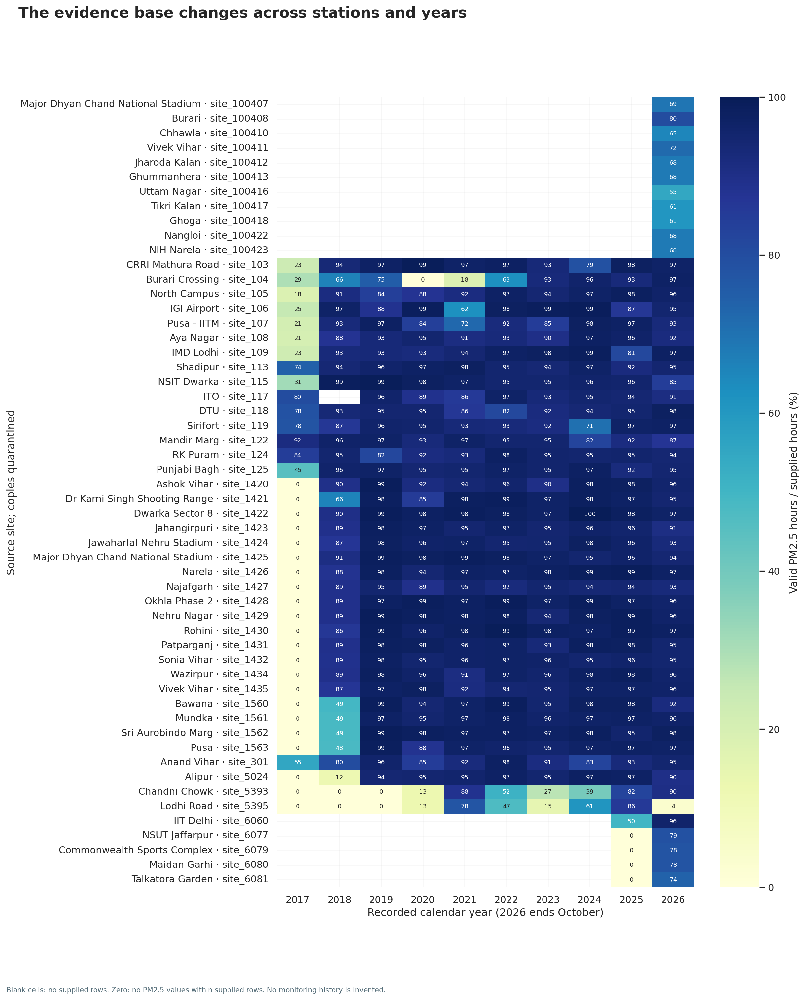

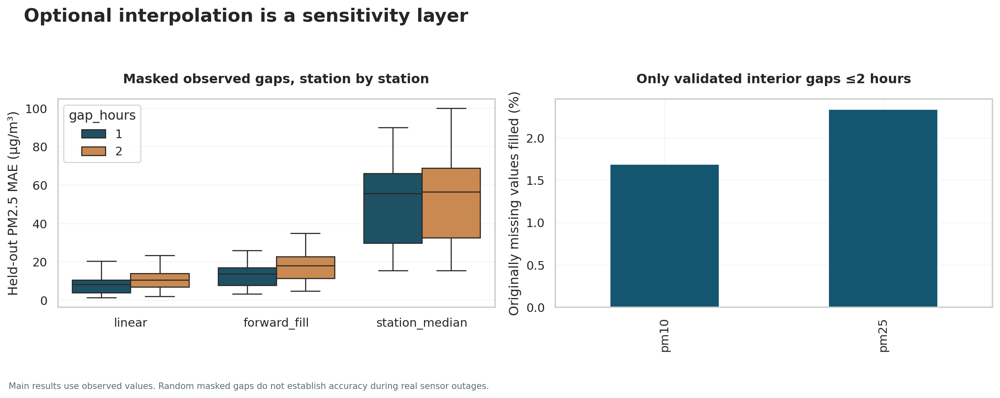

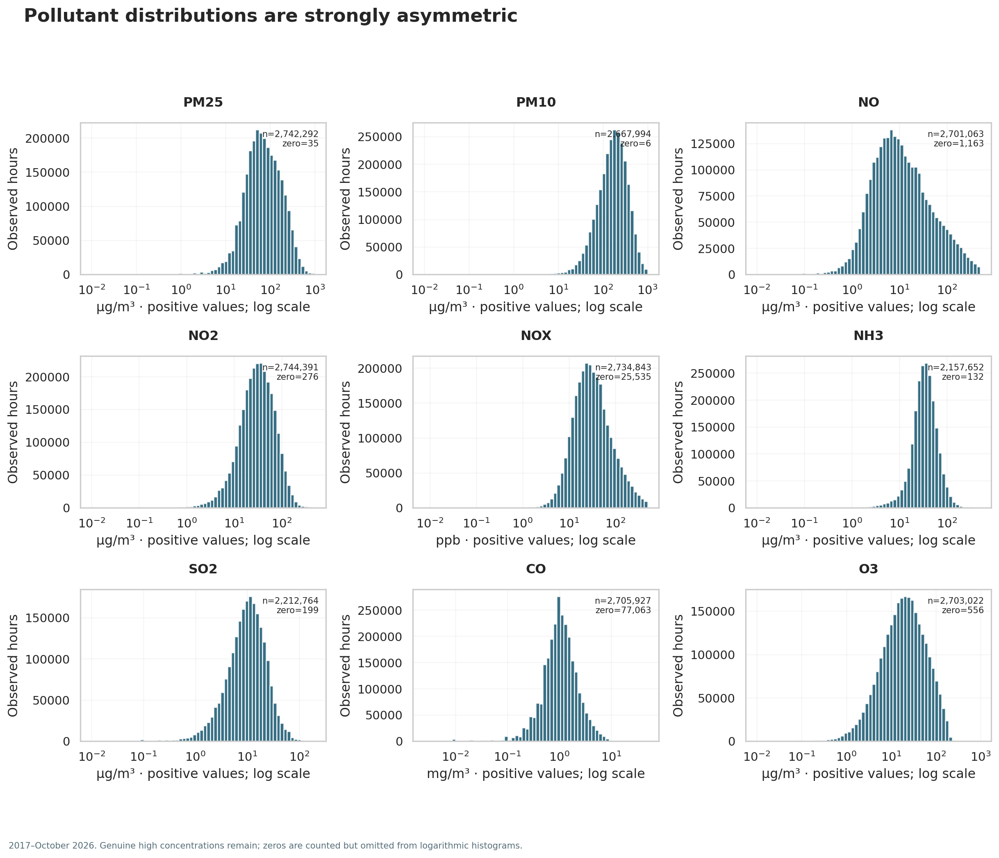

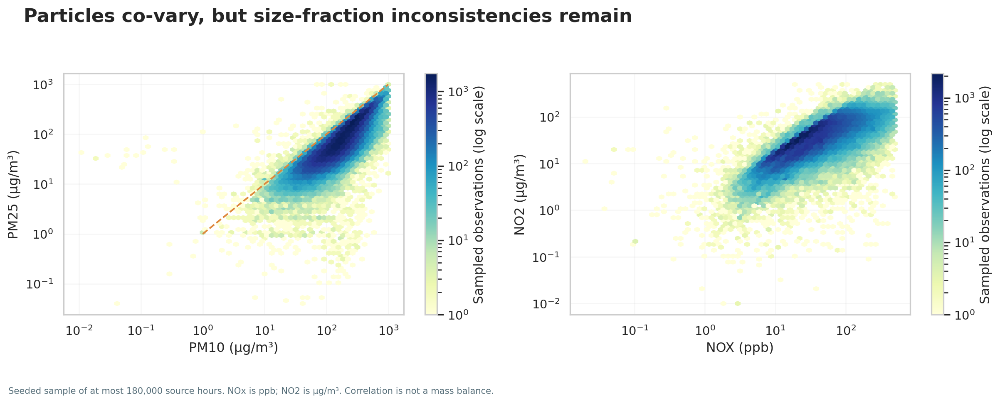

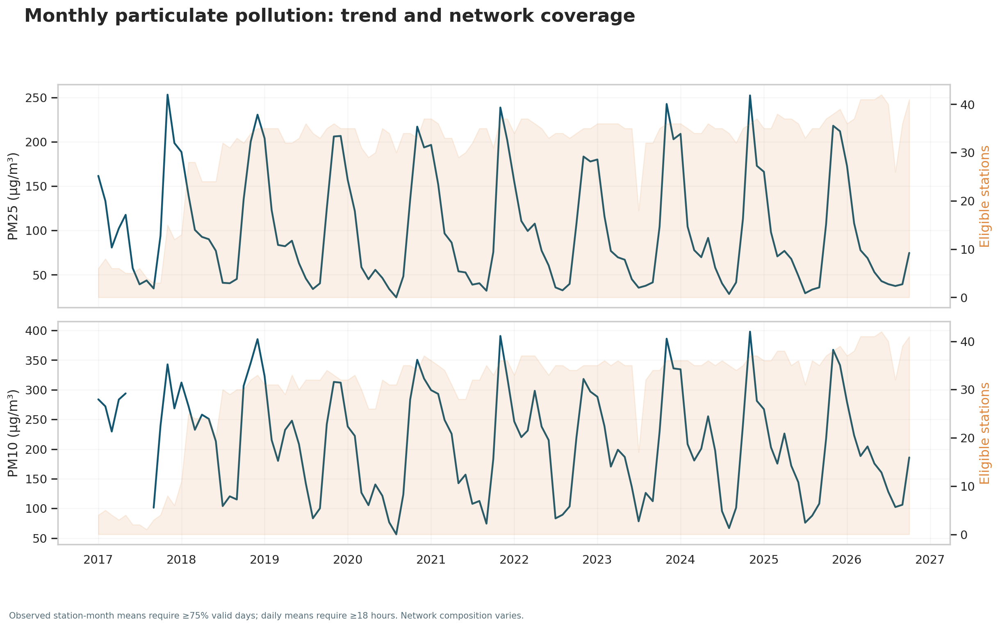

...

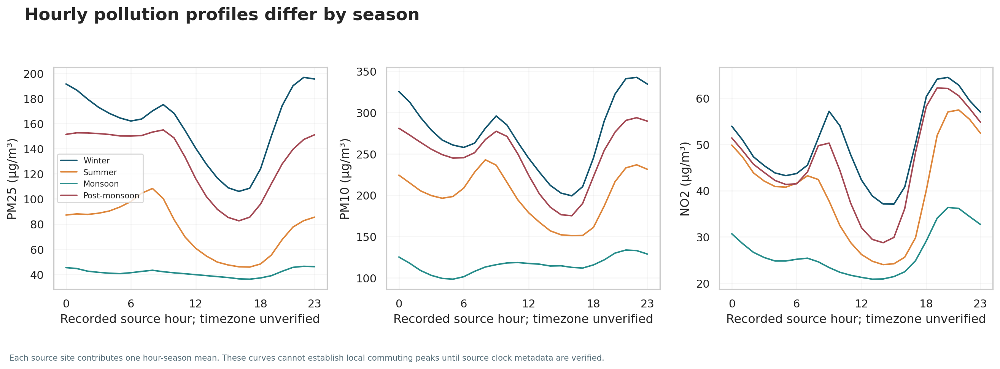

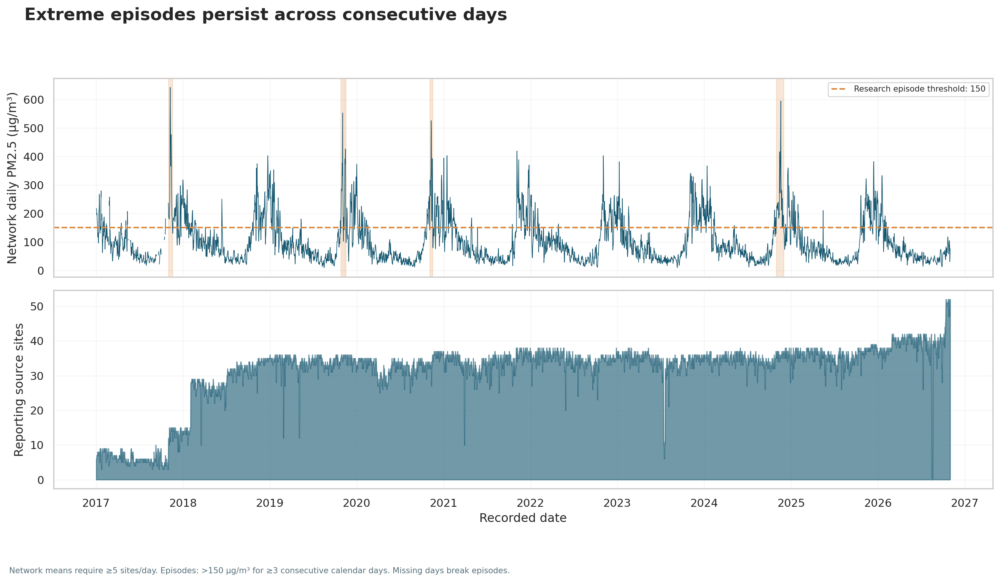

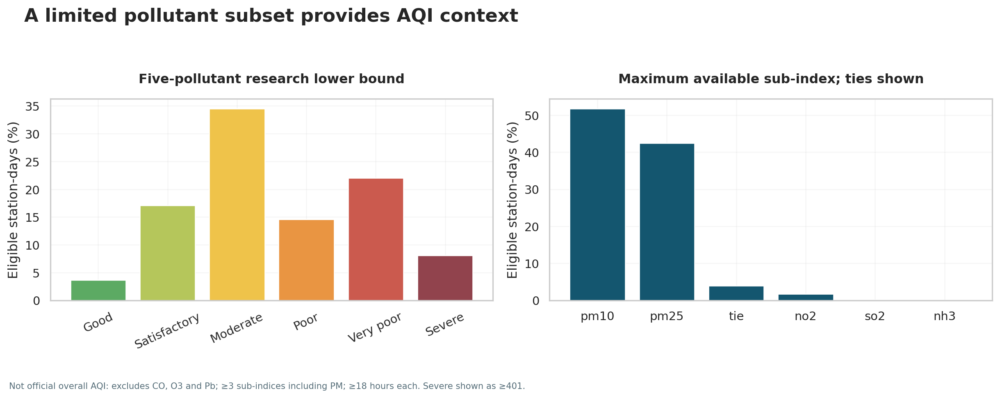

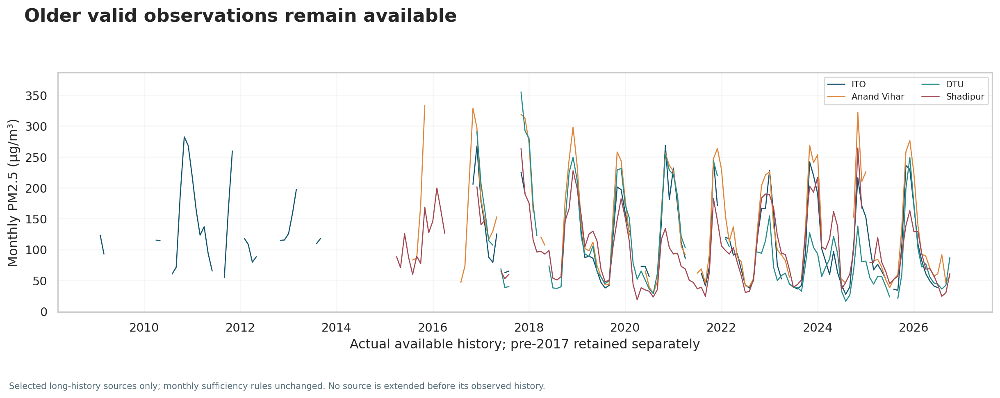

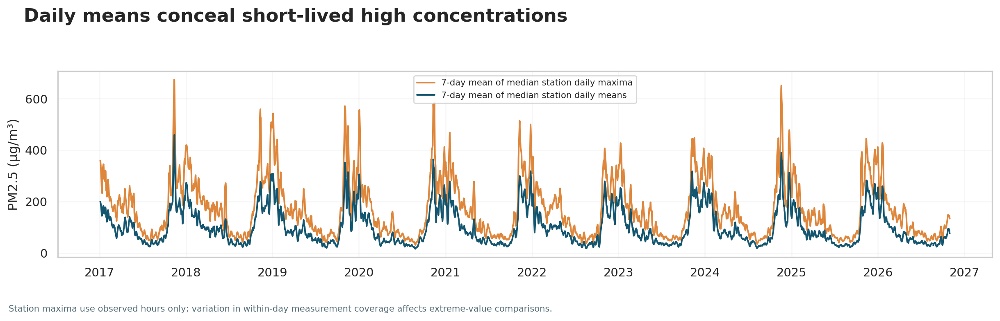

In [78]:
with _airscope_capture('f50db46b'):
    quality_and_pollution_figures(h,daily,monthly,city,annual,trends,seas,panels,aqi5,episodes,stationrank,cross)


## 14. Weather and multivariate visualizations

Read bin plots as descriptive mixtures of seasons/sites. Adjusted associations and block intervals answer narrower questions. Model-versus-monitor agreement uses valid overlap beginning in August 2022.

In [79]:
with _airscope_capture('49fe3e82'):
    def weather_figures(h,daily,w,grids,correlations,weather_effects,multi_model,wet_dry,joined,model_scores):
        fig,axes=plt.subplots(2,2,figsize=(13,9))
        specs=[('temp',[0,10,20,30,40,65],['0–10','10–20','20–30','30–40','40–65'],'Temperature (°C)'),('rh',[0,30,50,70,85,100],['0–30','30–50','50–70','70–85','85–100'],'Relative humidity (%)'),('ws',[-.001,.5,1,2,4,50],['<0.5','0.5–1','1–2','2–4','≥4'],'Wind speed (m/s)'),('rain',[-.001,0,.5,2,10,1000],['0','0–0.5','0.5–2','2–10','>10'],'Daily rain (mm)')]
        for ax,(c,bins,labs,xlabel) in zip(axes.flat,specs):
            q=daily[['pm25',c]].dropna();q['bin']=pd.cut(q[c],bins,labels=labs,include_lowest=True);g=q.groupby('bin',observed=False).pm25.agg(['median','count',lambda x:x.quantile(.25),lambda x:x.quantile(.75)])
            ax.errorbar(range(len(g)),g['median'],yerr=np.vstack([g['median']-g.iloc[:,2],g.iloc[:,3]-g['median']]),fmt='o-',capsize=3);ax.set_xticks(range(len(g)),labs,rotation=15);ax.set(xlabel=xlabel,ylabel='Daily PM2.5 (µg/m³)');ax.text(.97,.95,'Median and IQR',ha='right',va='top',transform=ax.transAxes,fontsize=8)
        figure(fig,'F13_weather_bins','Weather–pollution associations depend on context','Co-reported station-day meteorology; unadjusted bins mix seasons and locations. Whiskers show IQR, not confidence intervals.','weather')
        keys=CORE+['temp','rh','ws','rain'];matrix=pd.DataFrame(np.eye(len(keys)),index=keys,columns=keys)
        for _,r in correlations.iterrows():matrix.loc[r.x,r.y]=r.spearman;matrix.loc[r.y,r.x]=r.spearman
        fig,ax=plt.subplots(figsize=(11,9));sns.heatmap(matrix,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',ax=ax,annot_kws={'fontsize':8},cbar_kws={'label':'Spearman ρ'});figure(fig,'F14_correlations','Co-pollutants share patterns; meteorology adds structure','Pairwise-complete station-day data; pair counts exported separately. Dependent records are not independent significance tests.','statistical')
        fig,axes=plt.subplots(1,2,figsize=(13,5));r=weather_effects
        axes[0].errorbar(r.city_anomaly_rho,range(len(r)),xerr=np.vstack([r.city_anomaly_rho-r.block14_ci_low,r.block14_ci_high-r.city_anomaly_rho]),fmt='o',capsize=4);axes[0].set_yticks(range(len(r)),r.weather_parameter);axes[0].axvline(0,color='gray',ls='--');axes[0].set(xlabel='City anomaly Spearman ρ, 14-day block 95% CI',title='Station–calendar-month demeaning')
        r=multi_model;axes[1].errorbar(r.relative_change_percent,range(len(r)),xerr=np.vstack([r.relative_change_percent-r.ci_percent_low,r.ci_percent_high-r.relative_change_percent]),fmt='o',capsize=4,color=COLORS[1]);axes[1].set_yticks(range(len(r)),r.parameter);axes[1].axvline(0,color='gray',ls='--');axes[1].set(xlabel='Conditional change in (1 + PM2.5), % per IQR',title='Station, month and year fixed effects')
        figure(fig,'F15_adjusted_weather','Adjustment changes the interpretation of weather relationships','Left: city daily anomalies, 14-day moving blocks. Right: station-day model, shared 14-day calendar-block clustered intervals.','statistical')
        sample=h[['wd','ws','pm25']].dropna();sample=sample[sample.ws>=.5].copy();sample['sector']=((sample.wd+11.25)%360//22.5).astype(int);rose=sample.groupby('sector').pm25.agg(['median','count']).reindex(range(16));angles=np.arange(16)*2*np.pi/16
        fig,ax=plt.subplots(figsize=(8,7),subplot_kw={'projection':'polar'});ax.set_theta_zero_location('N');ax.set_theta_direction(-1);ax.bar(angles,rose['median'],width=2*np.pi/16*.9,color=COLORS[0],alpha=.8);ax.set_rlabel_position(135);figure(fig,'F16_pollution_rose','Wind-sector pollution context','Radial scale: median PM2.5 (µg/m³). Wind <0.5 m/s omitted. Pooled stations/seasons; direction does not establish source attribution.','weather')
        base=w[w.clock_scenario=='same_recorded_date'].copy();met=base.drop_duplicates(['model_weather_signature','timestamp']).groupby('timestamp')[WCOLS+['rain_mm','wind_ms']].mean();air=base.drop_duplicates(['model_air_signature','timestamp']).groupby('timestamp')[ACOLS].mean()
        fig,axes=plt.subplots(3,1,figsize=(13,9),sharex=False);met[['temperature_c','humidity_percent']].resample('MS').mean().plot(ax=axes[0],secondary_y='humidity_percent');axes[0].set_ylabel('Temperature (°C)');axes[0].right_ax.set_ylabel('Relative humidity (%)');met.rain_mm.resample('MS').sum(min_count=20).plot(ax=axes[1],color=COLORS[2]);axes[1].set(ylabel='Mean-grid monthly rainfall (mm)');air.aqi.dropna().resample('MS').mean().plot(ax=axes[2],color=COLORS[1]);axes[2].set(ylabel='Supplied AQI index',xlabel='Source recorded date; AQI scheme unverified')
        figure(fig,'F17_model_timelines','Meteorology and model air composition have different histories','Unique field-signature grids weighted equally. Weather: 2017–Oct 2026. AQI: Aug 2022–Oct 2026; no fabricated earlier values.','weather')
        fig,axes=plt.subplots(1,2,figsize=(13,5));q=joined[joined.clock_scenario=='same_recorded_date'][['pm10','pm10_ugm3']].dropna().sample(frac=1,random_state=SEED).head(35000);hb=axes[0].hexbin(q.pm10,q.pm10_ugm3,gridsize=65,bins='log',mincnt=1,cmap='YlGnBu');fig.colorbar(hb,ax=axes[0],label='Paired days (log scale)');axes[0].set(xlabel='Station PM10 daily mean (µg/m³)',ylabel='Model PM10 daily mean (µg/m³)');m=model_scores[model_scores.parameter=='pm10'];axes[1].bar(m.clock_scenario,m.MAE,color=COLORS[:2]);axes[1].set(ylabel='PM10 MAE (µg/m³)',xlabel='Provisional clock assumption');axes[1].tick_params(axis='x',rotation=15)
        figure(fig,'F18_model_agreement','Model values are supplementary estimates, not monitor replacements','Actual valid PM10 overlap begins August 2022. Approximate locations and clock assumptions limit agreement interpretation.','weather')
        # Explicit weather distributions use daily model values, never mislabelled as hourly observations.
        fig,axes=plt.subplots(2,3,figsize=(13,8))
        for ax,c,lab in zip(axes.flat,['temperature_c','humidity_percent','wind_ms','rain_mm','surface_pressure_hpa','shortwave_radiation_wm2'],['Temperature (°C)','Humidity (%)','Wind (m/s)','Daily rain (mm)','Pressure (hPa)','Daily mean shortwave radiation (W/m²)']):
            s=met[c].dropna();ax.hist(s,bins=50,color=COLORS[2],alpha=.8);ax.set(xlabel=lab,ylabel='Recorded days')
        figure(fig,'F19_weather_distributions','The meteorological background spans the full study window','Distributions of unique-grid mean daily model weather, 2017–October 2026; rainfall is a daily total before spatial averaging.','weather')


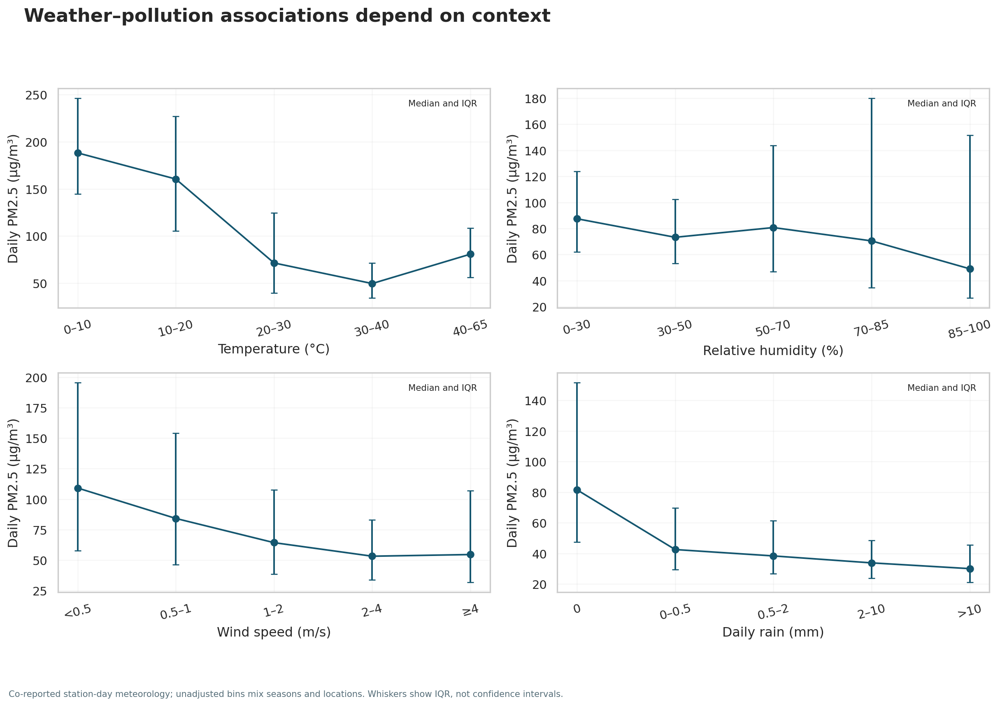

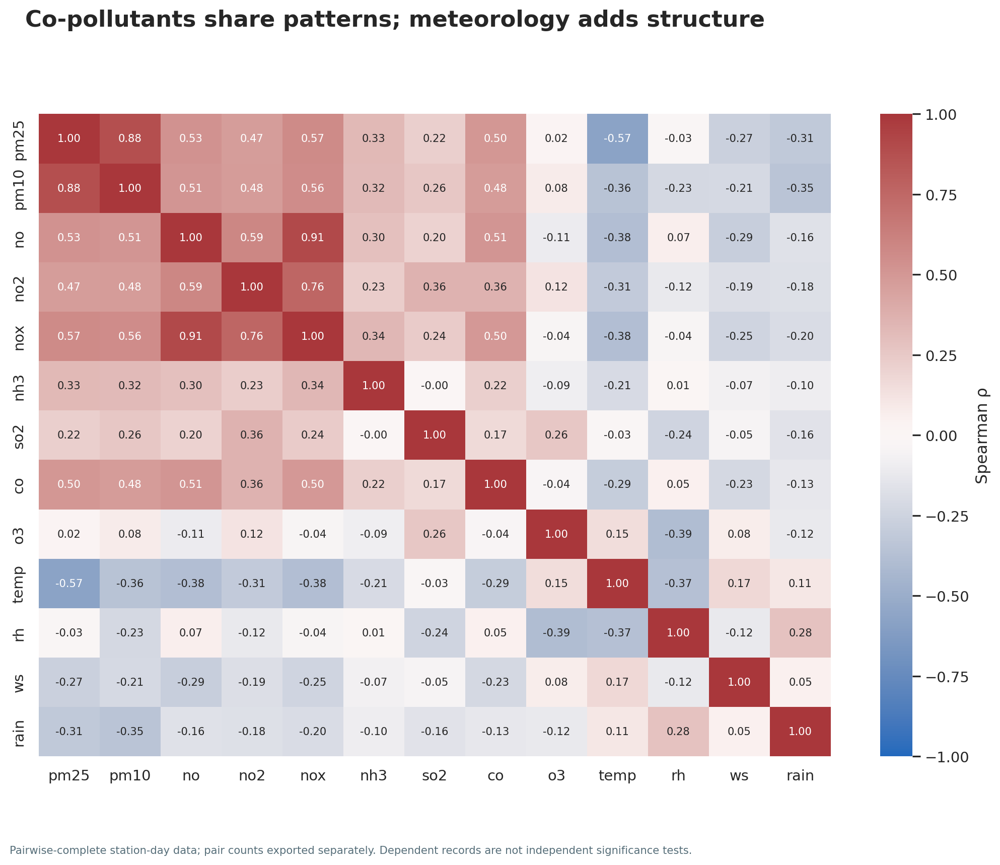

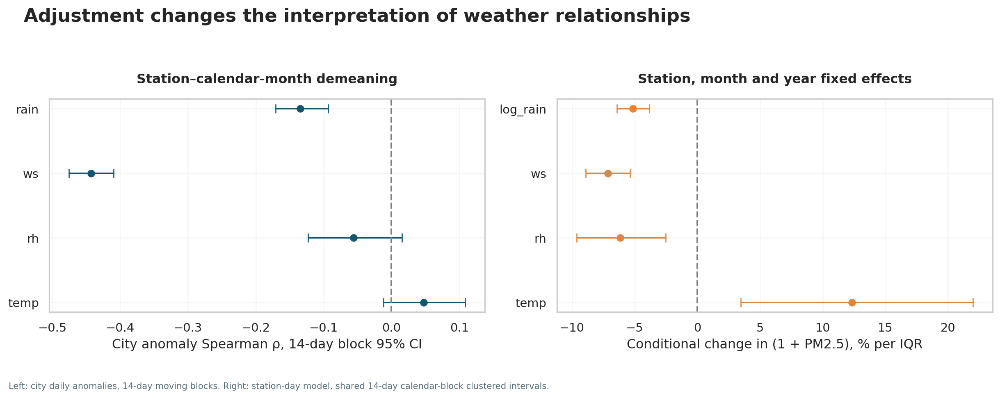

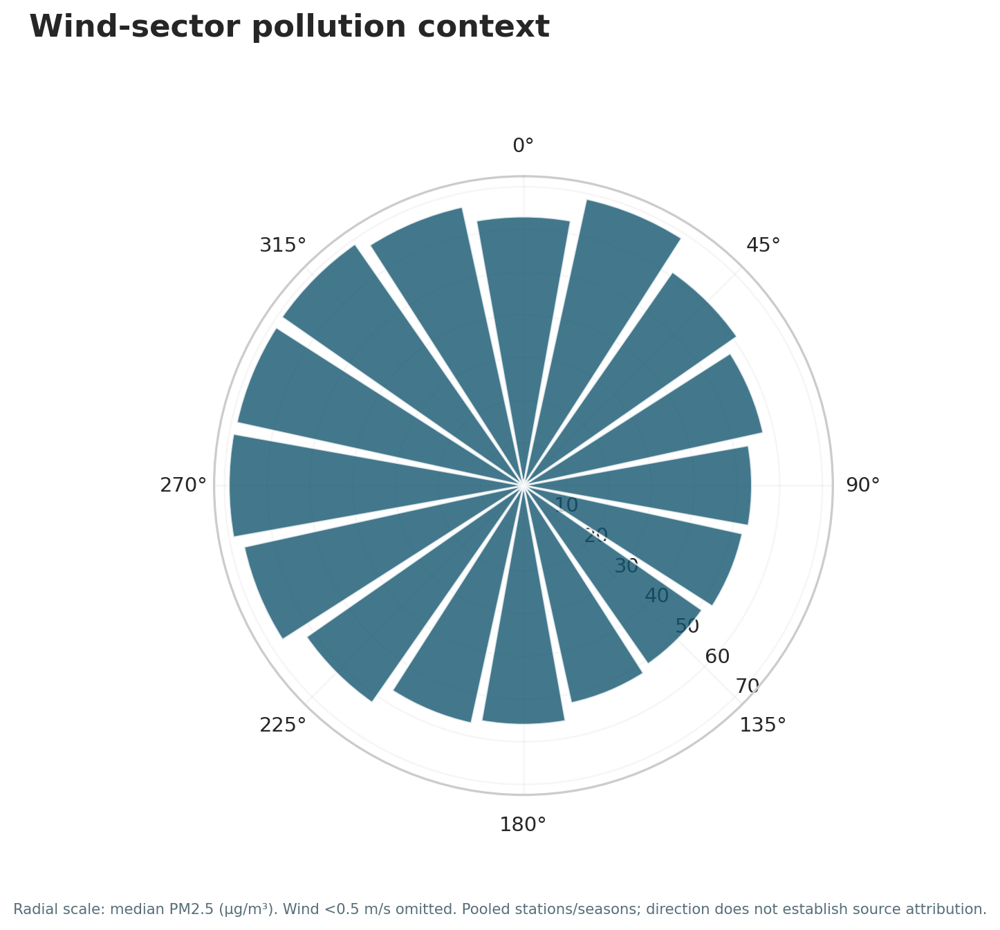

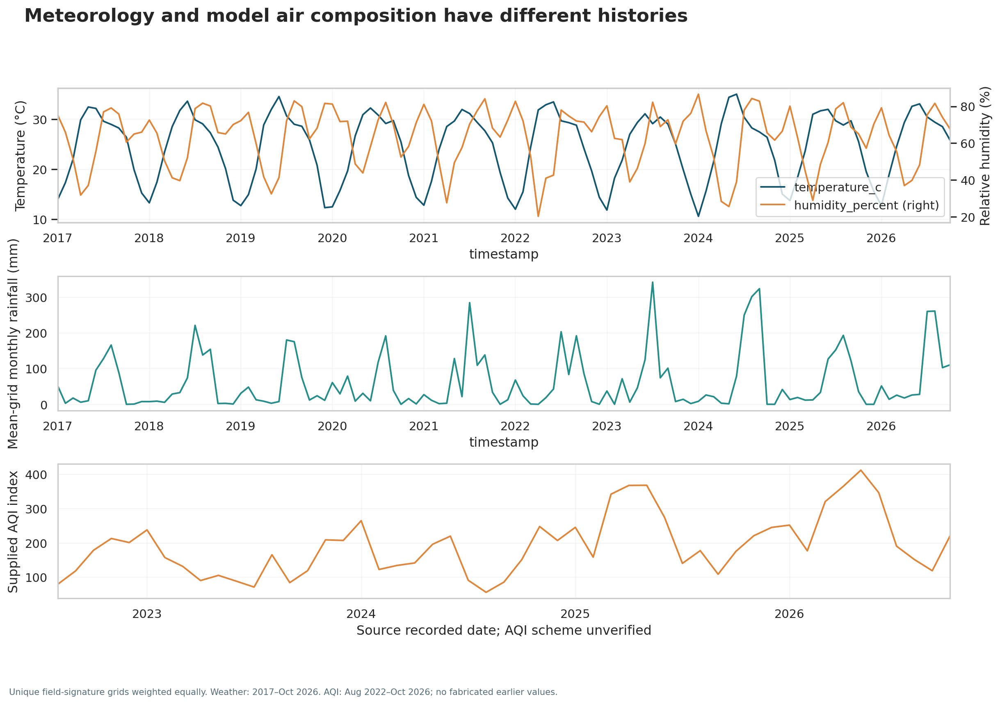

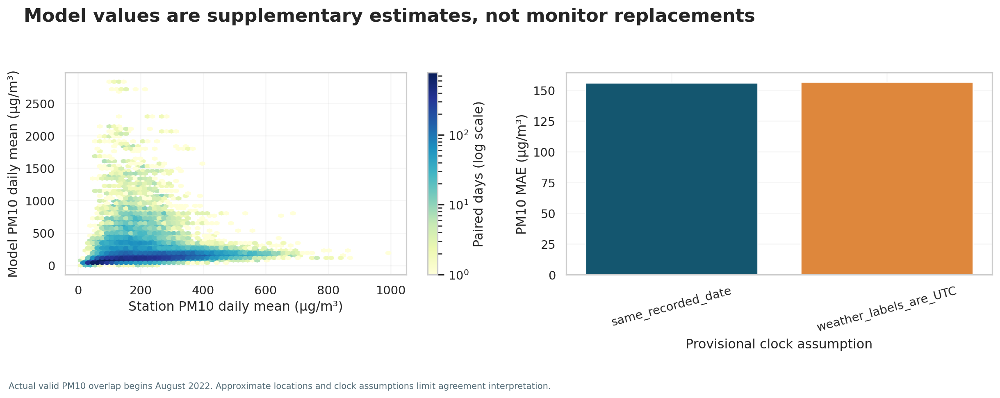

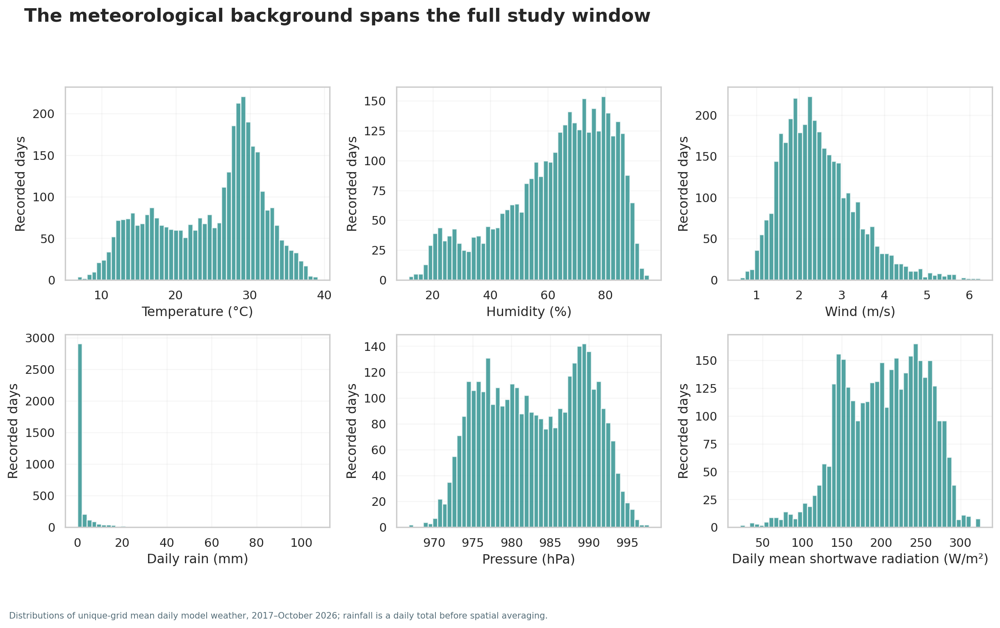

In [80]:
with _airscope_capture('bd35d3ff'):
    weather_figures(h,daily,w,grids,correlations,weather_effects,multi_model,wet_dry,joined,model_scores)


## 15. Spatial and advanced visualizations

Maps show supplied point locations and regional detections, not interpolated exposure or source-attribution surfaces. Population and emissions charts never invent intervening observations.

In [81]:
with _airscope_capture('e8c74f0d'):
    def advanced_figures(boundary,points,spatial,rf,popsum,popsamples,em,fires,firebase,firestats,stationrank,cross):
        labels=cross.set_index('site_id').label.to_dict()
        rank=stationrank.copy();rank['label']=[labels.get(x,x)+' · '+x for x in rank.site_id]
        fig,ax=plt.subplots(figsize=(11,max(6,len(rank)*.25)));ax.barh(rank.label,rank.pm25,color=COLORS[0]);ax.invert_yaxis();ax.set(xlabel='Observed daily PM2.5 mean (µg/m³)',ylabel='');figure(fig,'F20_station_comparison','Coverage-screened station comparison, 2023–2025','Each site has ≥75% valid days in each year. Dates still differ; these are descriptive monitoring-site means, not intrinsic neighbourhood rankings.','spatial')
        fig,ax=plt.subplots(figsize=(9,9));boundary.boundary.plot(ax=ax,color='#405866',linewidth=1.1);points.plot(ax=ax,color='#cbd4d8',markersize=15);spatial[spatial.pm25.notna()].plot(ax=ax,column='pm25',cmap='YlOrRd',markersize=65,edgecolor='white',linewidth=.5,legend=True,legend_kwds={'label':'2023–2025 PM2.5 (µg/m³)'})
        ax.set(xlabel='Longitude (°E)',ylabel='Latitude (°N)');figure(fig,'F21_spatial_map','Spatial context at supplied approximate locations','Coordinates are user supplied and registry-unverified. Gray points have no coverage-qualified comparison; no pollution surface is interpolated.','spatial')
        fig,axes=plt.subplots(1,2,figsize=(13,6))
        for ax,year in zip(axes,[2024,2025]):
            q=fires[fires.timestamp_ist.dt.year==year];hb=ax.hexbin(q.longitude,q.latitude,gridsize=70,bins='log',mincnt=1,cmap='YlOrRd');boundary.boundary.plot(ax=ax,color=COLORS[0],linewidth=1);ax.plot(77.209,28.6139,'o',color=COLORS[0],ms=4);ax.set(title=f'Oct–Nov {year}',xlabel='Longitude (°E)',ylabel='Latitude (°N)');fig.colorbar(hb,ax=ax,label='Detections per hexagon (log scale)')
        figure(fig,'F22_fire_geography','Regional thermal detections provide broader context','VIIRS detections are not unique fires, burned area or crop-burning labels. Hexagons aggregate detections, not emissions.','spatial')
        fig,axes=plt.subplots(2,1,figsize=(13,8))
        for ax,year in zip(axes,[2024,2025]):
            q=firebase[firebase.index.year==year];ax.plot(q.index,q.pm25,color=COLORS[0],label='Same-panel pollution');ax.set(ylabel='Daily PM2.5 (µg/m³)',title=str(year));ax2=ax.twinx();ax2.bar(q.index,q.fire_count,color=COLORS[1],alpha=.25);ax2.set_ylabel('Regional detections');ax2.grid(False);ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
        figure(fig,'F23_fire_windows','Fire–pollution comparisons use two observed seasonal windows','Delhi pollution clock assumed IST for this sensitivity. Missing fire dates are not zeros; adjusted lag results are exported separately.','temporal')
        fig,ax=plt.subplots(figsize=(11,5));ax.errorbar(firestats.lag_days-.06,firestats.conditional_log1p_coefficient,yerr=np.vstack([firestats.conditional_log1p_coefficient-firestats.HAC7_ci_low,firestats.HAC7_ci_high-firestats.conditional_log1p_coefficient]),fmt='o',capsize=5,label='Weather + year + linear within-window time')
        extended=pd.read_csv(OUT/'data/processed/tables/fire_extended_sensitivity.csv');ex=extended[extended.exposure=='fire_count'];ax.errorbar(ex.lag_days+.06,ex.coefficient,yerr=np.vstack([ex.coefficient-ex.ci_low,ex.ci_high-ex.coefficient]),fmt='s',capsize=5,color=COLORS[1],label='Add wind direction, month and quadratic time');ax.axhline(0,color='gray',ls='--');ax.set(xlabel='Fire detections lead pollution by days',ylabel='Conditional log1p association coefficient',xticks=range(4));ax.legend(fontsize=8);figure(fig,'F24_fire_lags','Fire associations depend on model controls','Unadjusted HAC7 95% intervals. None of eight expanded regional/northwest tests passes BH p<0.05; two windows cannot establish attribution.','statistical')
        fig,axes=plt.subplots(1,2,figsize=(13,6))
        for ax,year in zip(axes,[2020,2030]):
            a=popsamples[year];hb=ax.hexbin(a.Longitude,a.Latitude,C=a.Population,reduce_C_function=np.sum,gridsize=90,bins='log',mincnt=1,cmap='cividis');boundary.boundary.plot(ax=ax,color='white',linewidth=.7);ax.set(title=f'{year}'+(' · projection if GHSL R2023A' if year>=2025 else ' · modelled snapshot'),xlabel='Longitude (°E)',ylabel='Latitude (°N)');fig.colorbar(hb,ax=ax,label='Supplied Population sum (log scale)')
        figure(fig,'F25_population_maps','Population grids provide exposure context, not personal exposure','Unknown cell footprints and changing positive-value support prevent unqualified population-weighted pollution estimates.','spatial')
        fig,ax=plt.subplots(figsize=(11,5));ax.plot(popsum.epoch,popsum.population_field_sum_all/1e6,'o-',label='Sum of supplied point values');ax.axvspan(2022.5,2031,color=COLORS[1],alpha=.1,label='2025/2030 projections if GHSL R2023A');ax.set(xlabel='Supplied epoch',ylabel='Sum of Population field (millions; unit conditional)',xticks=popsum.epoch);ax.legend(fontsize=8);figure(fig,'F26_population_epochs','Population epochs remain separate from pollution timelines','Points are supplied epochs; connecting lines are guides. All point centres fall within the supplied Delhi boundary.','spatial')
        fig,axes=plt.subplots(2,2,figsize=(14,9))
        for ax,(sub,q) in zip(axes.flat,em.groupby('substance',sort=True)):
            pivot=q.pivot(index='year',columns='sector',values='emission_value_source_units').fillna(0);shares=pivot.div(pivot.sum(axis=1),axis=0)*100;shares.plot.area(ax=ax,linewidth=0,alpha=.9,cmap='tab20');ax.set(title=sub,ylabel='Share of supplied sector total (%)',xlabel='Inventory epoch');ax.legend(fontsize=6,ncol=2,loc='upper left')
        figure(fig,'F27_emissions_sectors','Sector inventories describe emissions structure across available epochs','Selected epochs only; connecting segments are guides. Source units/release unverified; shares are not ambient source contributions.','pollution')
        fig,axes=plt.subplots(1,2,figsize=(13,5));totals=em.groupby(['substance','year']).emission_value_source_units.sum().unstack(0);norm=totals/totals.iloc[0]*100;norm.plot(ax=axes[0]);axes[0].set(ylabel='Within-substance total (1975 = 100)',xlabel='Inventory epoch');last=em[em.year==2024];share=last.assign(share=lambda x:x.emission_value_source_units/x.groupby('substance').emission_value_source_units.transform('sum')*100);sns.barplot(data=share,x='sector',y='share',hue='substance',ax=axes[1]);axes[1].tick_params(axis='x',rotation=30);axes[1].set(ylabel='2024 supplied inventory share (%)',xlabel='');axes[1].legend(fontsize=7)
        figure(fig,'F28_emissions_changes','Emission totals and sector shares answer different questions','Indexed totals avoid inventing units. Urban-centre emissions geography (2,139 km²) differs from the supplied Delhi administrative boundary.','pollution')


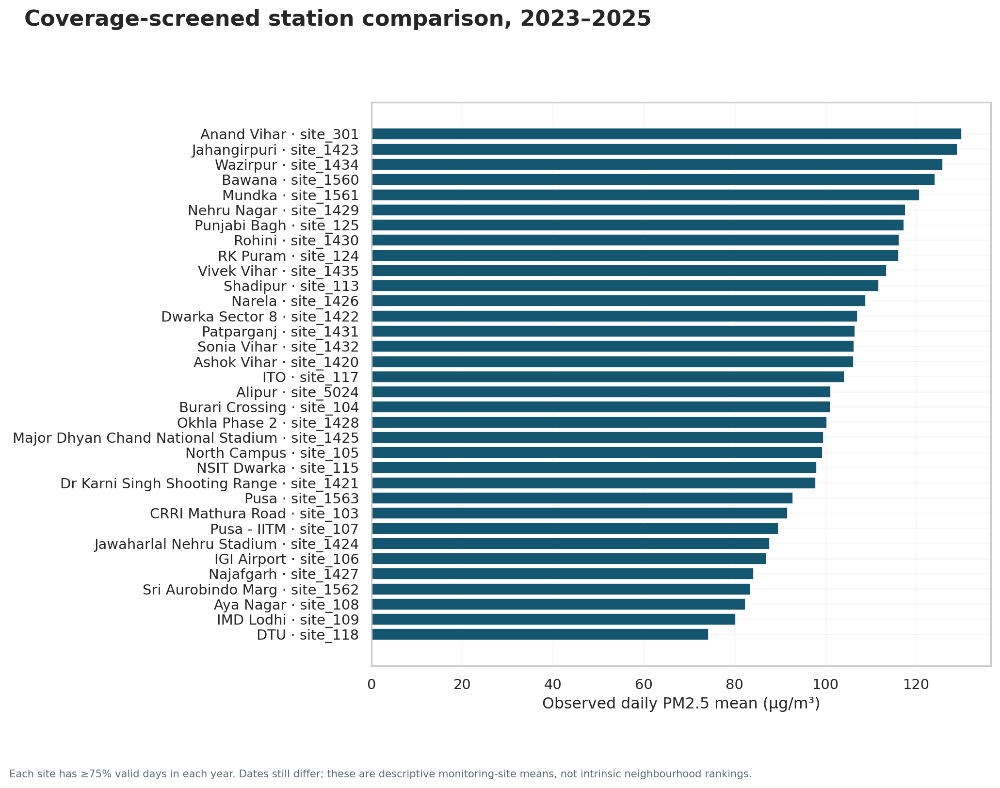

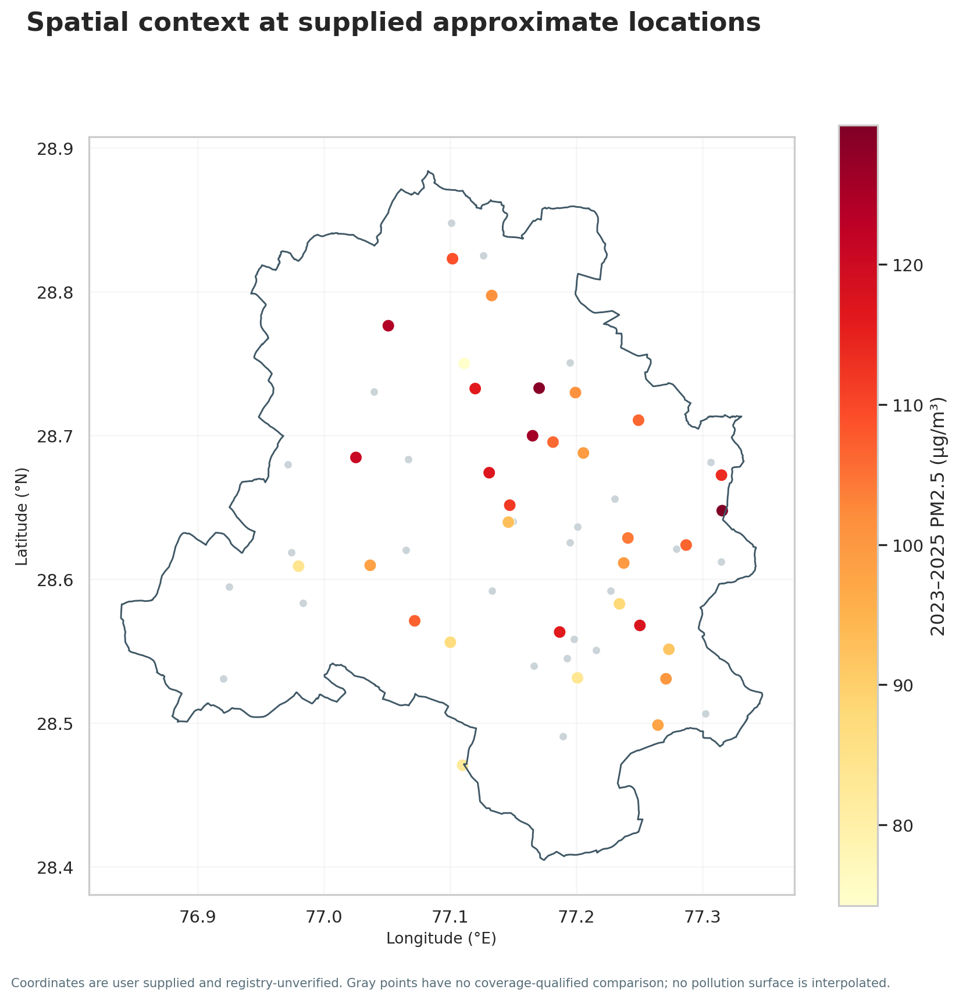

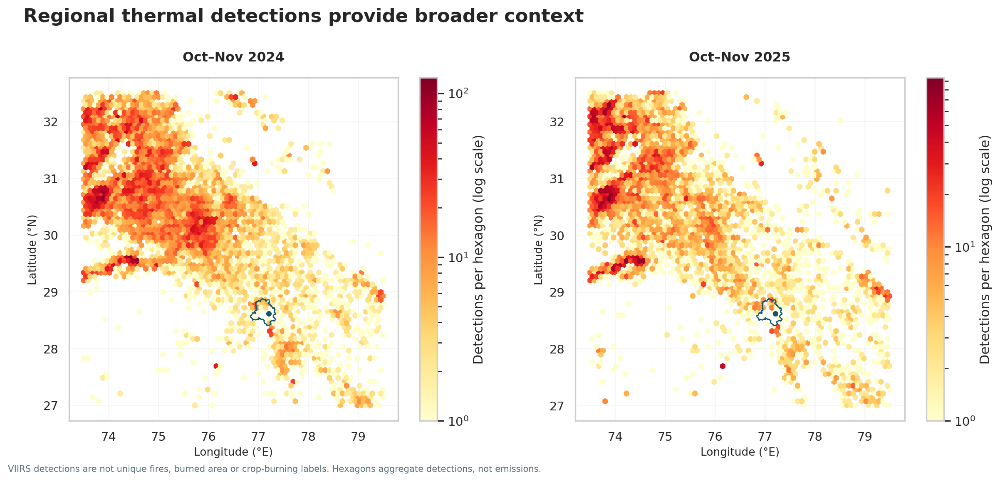

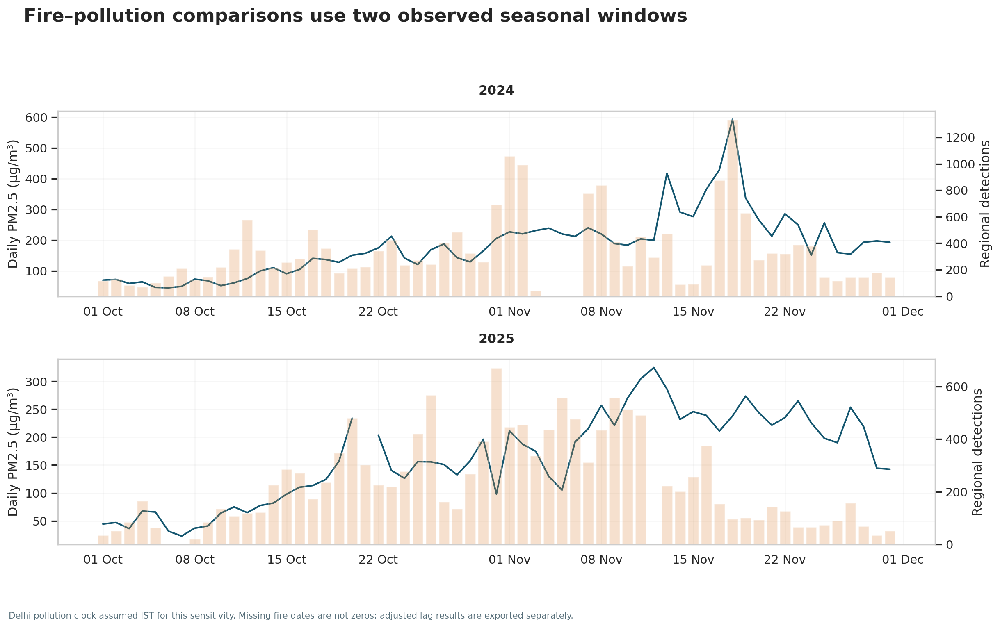

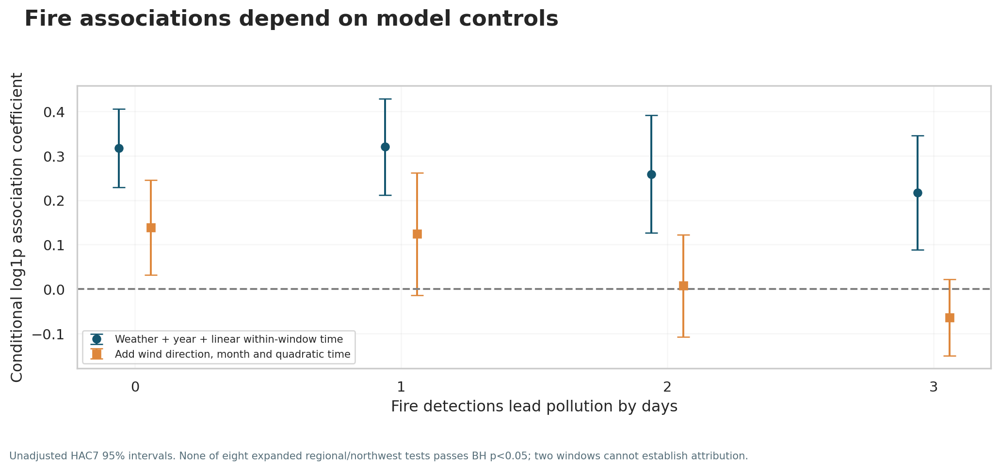

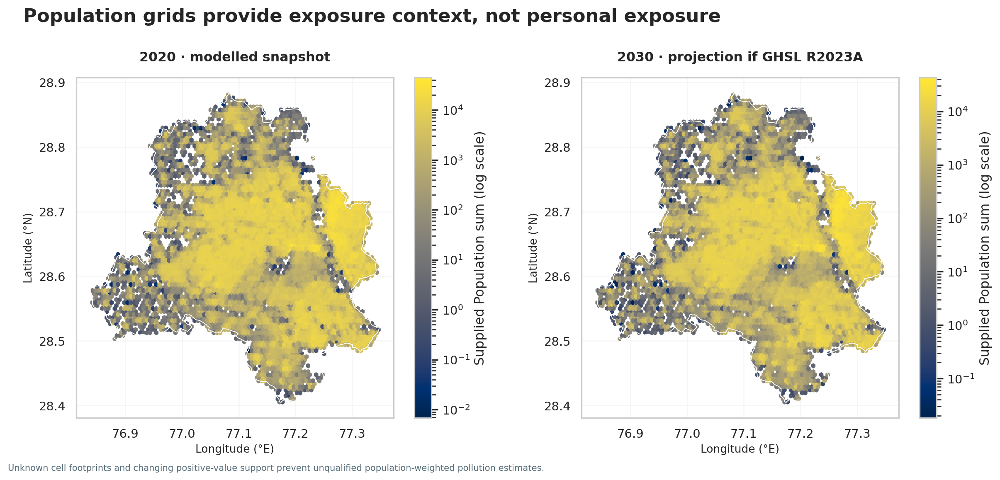

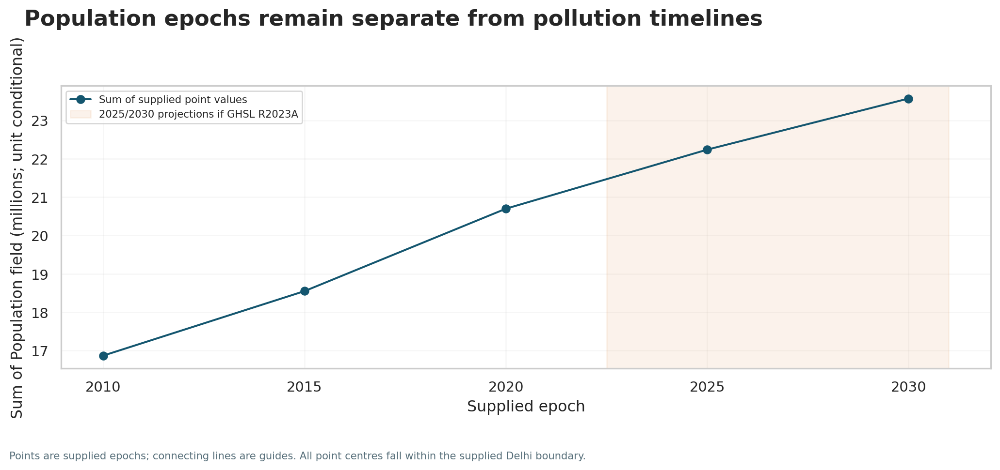

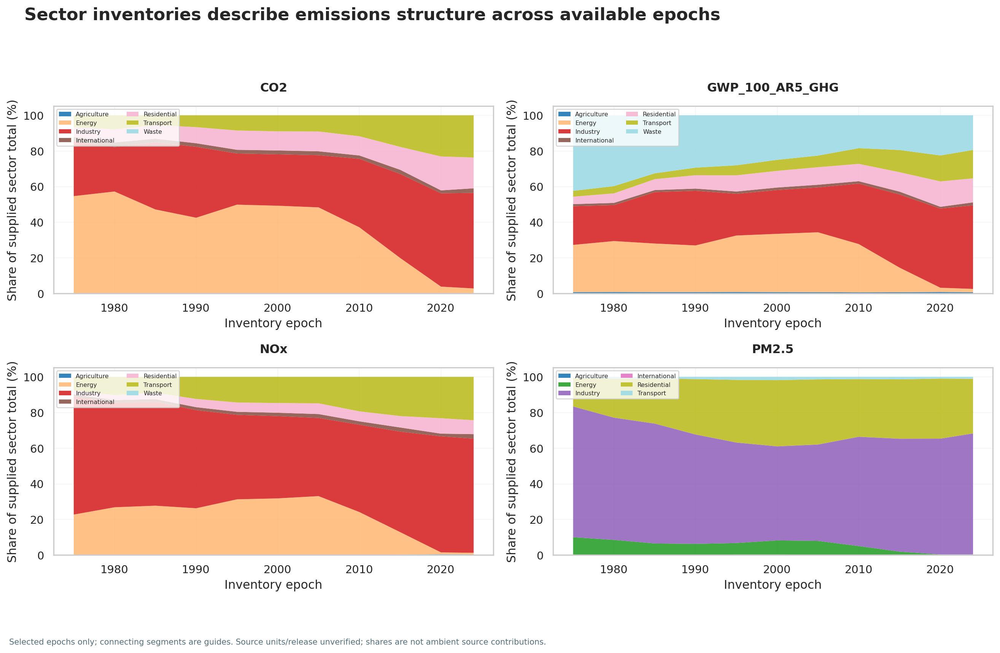

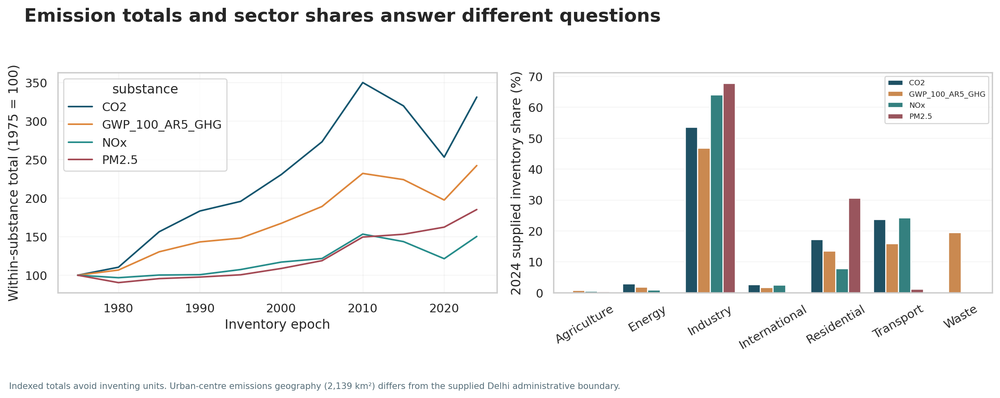

In [82]:
with _airscope_capture('7cf6dd61'):
    advanced_figures(boundary,points,spatial,rf,popsum,popsamples,em,fires,firebase,firestats,stationrank,cross)


## 16. Interactive exploration

Self-contained Plotly timelines support zooming; the station-context map uses Leaflet CDN assets. Static PNG/SVG equivalents are available. Model AQI is shown only on its own shorter history.

In [83]:
with _airscope_capture('fa24c099'):
    def interactive_outputs(city,monthly,spatial,boundary,w):
        t=city.reset_index();fig=go.Figure()
        for c in ['pm25','pm10']:fig.add_trace(go.Scatter(x=t.timestamp,y=t[c],name=c.upper(),mode='lines',line={'width':1}))
        fig.update_layout(template='plotly_white',title='Observed network daily particles · ≥5 source sites/day · composition varies',xaxis={'rangeslider':{'visible':True},'rangeselector':{'buttons':[{'count':1,'label':'1 year','step':'year','stepmode':'backward'},{'step':'all','label':'All'}]}},yaxis_title='µg/m³',height=650)
        fig.write_html(OUT/'visualizations/temporal/Interactive_Pollution_Timeline.html',include_plotlyjs=True)
        import folium
        m=folium.Map(location=[28.64,77.13],zoom_start=10,tiles=None)
        folium.GeoJson(json.loads(boundary.to_json()),name='Supplied Delhi boundary',style_function=lambda x:{'color':'#345361','weight':1.5,'fillOpacity':.03}).add_to(m)
        for _,r in spatial.iterrows():
            value=f'{r.pm25:.1f} µg/m³' if pd.notna(r.pm25) else 'No qualified 2023–2025 mean'
            text=f'{r.label} | {r.site_id}<br>{value}<br>Approximate supplied coordinates; not registry verified'
            folium.CircleMarker([r.lat,r.lon],radius=6,color='#b64d40' if pd.notna(r.pm25) else '#7f929c',fill=True,popup=text,tooltip=r.label).add_to(m)
        m.save(OUT/'visualizations/spatial/Interactive_Station_Context.html')
        # Model AQI is displayed only from its first observed date, never padded to 2017.
        a=w[(w.clock_scenario=='same_recorded_date')&w.aqi.notna()].drop_duplicates(['model_air_signature','timestamp']).groupby('timestamp').aqi.mean().reset_index()
        fig=px.line(a,x='timestamp',y='aqi',title='Supplied model AQI · scheme unverified · actual August 2022 onward coverage',template='plotly_white');fig.update_xaxes(rangeslider_visible=True);fig.update_yaxes(title='Source AQI index (not classified as Indian AQI)');fig.write_html(OUT/'visualizations/weather/Interactive_Model_AQI.html',include_plotlyjs=True)
        if SHOW_FIGURES:display(HTML(fig.to_html(include_plotlyjs=True,full_html=False)))
        print('Saved three interactive HTML artifacts. Plotly timelines embed their JavaScript; Folium requires CDN access.')


In [84]:
with _airscope_capture('e5bcf8b1'):
    interactive_outputs(city,monthly,spatial,boundary,w)


Saved three interactive HTML artifacts. Plotly timelines embed their JavaScript; Folium requires CDN access.


## 17. Validation, sensitivity and feature audit

Check source hashes, row/key conservation, valid-overlap joins, imputation boundaries and absence of look-ahead. Compare 16/18/20-hour daily rules and the optional interpolation product against observed-only results.

In [85]:
with _airscope_capture('54cd63a0'):
    def sensitivity_and_validation(h,daily,manifest):
        a=h[['site_id','timestamp','pm25','pm10']].copy();a['date']=a.timestamp.dt.floor('D')
        g=a.groupby(['site_id','date'],observed=True)[['pm25','pm10']].mean();n=a.groupby(['site_id','date'],observed=True)[['pm25','pm10']].count();sens=[]
        for threshold in [16,18,20]:
            q=g.where(n>=threshold)
            for c in ['pm25','pm10']:
                citymean=q[c].groupby('date').mean();ct=q[c].groupby('date').count();citymean=citymean.where(ct>=5)
                sens.append({'parameter':c,'minimum_hours_per_day':threshold,'eligible_station_days':int(q[c].notna().sum()),'eligible_city_days':int(citymean.notna().sum()),'mean_city_daily_concentration':citymean.mean(),'median_city_daily_concentration':citymean.median(),'p95_city_daily_concentration':citymean.quantile(.95)})
        save_table(pd.DataFrame(sens),'daily_sufficiency_sensitivity')
        impdaily=[];filled=0
        for p in sorted((OUT/'data/imputed').glob('*.parquet')):
            z=pd.read_parquet(p);z=z[z.index.to_series().between(START,END).to_numpy()]
            for c in ['pm25','pm10']:
                original=z[c+'_observed'];new=z[c];mask=z[c+'_imputed'];missing=z[c+'_originally_missing']
                check('Observed values unchanged by optional imputation: '+p.stem+' '+c,np.allclose(original[original.notna()],new[original.notna()],equal_nan=True))
                check('Imputation occurs only at original missing values: '+p.stem+' '+c,(~mask|missing).all())
                runs=missing.groupby((~missing).cumsum()).transform('sum')
                check('No long-gap interpolation: '+p.stem+' '+c,(runs[mask]<=2).all())
                filled+=int(mask.sum())
            m=z[['pm25','pm10']].resample('D').mean();cnt=z[['pm25','pm10']].resample('D').count();m=m.where(cnt>=18);m['site_id']=p.stem.split('_PM')[0];impdaily.append(m.reset_index())
        im=pd.concat(impdaily,ignore_index=True);v=im.groupby('timestamp')[['pm25','pm10']].mean();ct=im.groupby('timestamp')[['pm25','pm10']].count();v=v.where(ct>=5)
        obs=daily.groupby('timestamp')[['pm25','pm10']].mean();ct=daily.groupby('timestamp')[['pm25','pm10']].count();obs=obs.where(ct>=5)
        effects=[]
        for c in ['pm25','pm10']:
            pair=obs[[c]].join(v[[c]],lsuffix='_observed',rsuffix='_imputed').dropna()
            effects.append({'parameter':c,'common_city_days':len(pair),'observed_mean':pair[c+'_observed'].mean(),'optional_imputed_mean':pair[c+'_imputed'].mean(),'mean_difference':(pair[c+'_imputed']-pair[c+'_observed']).mean(),'maximum_absolute_daily_difference':(pair[c+'_imputed']-pair[c+'_observed']).abs().max()})
        save_table(pd.DataFrame(effects),'imputation_city_sensitivity')
        check('No quarantined station folders in main hourly analysis',not h.source_label.astype(str).isin(['Badarpur','Maidan Gharhi']).any())
        check('Primary hourly timeline respected',h.timestamp.between(START,END).all())
        check('Unique primary site/hour',not h.duplicated(['site_id','timestamp']).any())
        # Verify original source preservation by hash, not just by byte size.
        for _,r in manifest[manifest.included].iterrows():
            dest=OUT/'data/original'/r.path
            if COPY_ORIGINALS:
                check('Original copy hash: '+r.path,dest.exists() and hashlib.sha256(dest.read_bytes()).hexdigest()==r.sha256)
        for p in (OUT/'data/processed/hourly').glob('*.parquet'):
            q=pd.read_parquet(p,columns=['timestamp','pm25','pm25_lag1h']);q=q.set_index('timestamp');expected=q.pm25.reindex(pd.date_range(q.index.min(),q.index.max(),freq='h')).shift(1).reindex(q.index)
            check('One-hour lag has no look-ahead: '+p.stem,np.allclose(q.pm25_lag1h,expected,equal_nan=True))
        print(f'Validated {len(CHECKS):,} checks, including raw-copy hashes, join cardinality, observed-value conservation and bounded interpolation.')
        return pd.DataFrame(sens),pd.DataFrame(effects)
    
    def supplementary_statistics(h,full_daily,daily):
        # All numeric pollutant fields, including secondary aromatic indicators, receive profiles.
        profiles=pd.read_csv(OUT/'documentation/Cleaned_Column_Profiles.csv');summary=profiles.groupby('column').agg(source_files=('source','count'),rows=('rows','sum'),valid=('valid','sum'),minimum=('min','min'),maximum=('max','max')).reset_index();summary['missing_pct']=100*(1-summary.valid/summary.rows);save_table(summary,'all_parameter_completeness')
        # Record primary-period hourly descriptions without assuming independent samples.
        descriptions=h[CORE+MET].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.reset_index(names='parameter');descriptions['skew']=h[CORE+MET].skew().to_numpy();descriptions['kurtosis_excess']=h[CORE+MET].kurt().to_numpy();save_table(descriptions,'primary_hourly_descriptive_statistics')
        diurnal=h.groupby(['site_id','season','hour'],observed=True)[CORE].agg(['mean','count']).reset_index();diurnal.columns=['_'.join(c).strip('_') if isinstance(c,tuple) else c for c in diurnal.columns];save_table(diurnal,'hourly_seasonal_profiles')
        weekend=h.groupby(['site_id','season','weekend'],observed=True)[['pm25','pm10','no2']].mean().reset_index();save_table(weekend,'weekday_weekend_seasonal_means')
        maxima=daily[['site_id','timestamp','pm25','pm10','pm25_max','pm10_max','pm25_hours','pm10_hours']];maxima.to_parquet(OUT/'data/processed/station_daily_means_and_maxima.parquet',index=False)
        # Uncapped observed values, review indicators and anomaly summaries remain accessible.
        review=pd.DataFrame({'flag':['PM2.5 > simultaneous PM10','PM at 1000 source ceiling','Temperature >55°C (review only)'],'primary_hour_count':[int(h.pm_order_review.sum()),int(h.pm_ceiling_review.sum()),int(h.temperature_review.sum())]});save_table(review,'primary_quality_review_counts')
        return descriptions,review


In [86]:
with _airscope_capture('685905c1'):
    sensitivity, imp_effect = sensitivity_and_validation(h,daily,manifest)
    descriptions, quality_review = supplementary_statistics(h,full_daily,daily)
    display(sensitivity)
    display(imp_effect)


Validated 2,132 checks, including raw-copy hashes, join cardinality, observed-value conservation and bounded interpolation.


,parameter,minimum_hours_per_day,eligible_station_days,eligible_city_days,mean_city_daily_concentration,median_city_daily_concentration,p95_city_daily_concentration
0,pm25,16,113874,3558,101.500890,76.228916,257.401571
1,pm10,16,110844,3370,209.551186,194.649277,408.908221
2,pm25,18,112435,3542,101.544664,76.104680,257.340391
3,pm10,18,109486,3361,209.515595,194.625954,409.045334
4,pm25,20,110435,3536,101.466176,75.968565,257.405495
5,pm10,20,107615,3345,208.753590,194.447402,408.269276


,parameter,common_city_days,observed_mean,optional_imputed_mean,mean_difference,maximum_absolute_daily_difference
0,pm25,3542,101.544664,101.540772,-0.003892,8.851326
1,pm10,3361,209.515595,209.691175,0.175580,28.569860


## 18. Evidence-linked findings

Each finding includes its question, parameters, evidence, actual timeline, figure, interpretation and limitations. Every numerical claim comes from the executed tables.

In [87]:
with _airscope_capture('a7fbce99'):
    def build_findings(h,daily,city,cross,weather_effects,wet_dry,episodes,matched,model_scores,firestats,em,popsum):
        global FINDINGS
        FINDINGS=[]
        fe=pd.read_csv(OUT/'data/processed/tables/station_fixed_effects_trends.csv').set_index('parameter');end=pd.read_csv(OUT/'data/processed/tables/matched_endpoint_Jan_Oct.csv').set_index('parameter');seasonal=pd.read_csv(OUT/'data/processed/tables/paired_seasonal_contrasts.csv').set_index('parameter');wa=weather_effects.set_index('weather_parameter')
        r=fe.loc['pm25'];e=end.loc['pm25']
        finding('How has PM2.5 changed across the primary study period?',f'Station/month-adjusted slope {r.slope_per_year:.2f} µg/m³/year (95% CI {r.ci_low:.2f} to {r.ci_high:.2f}); {int(r.station_months):,} qualified station-months, {int(r.site_ids)} source sites; five-trend BH p={r.p_BH:.3g}. A separate {int(e.matched_sites)}-site January–October comparison changes from {e.first_Jan_Oct_mean:.1f} in {int(e.first_year)} to {e.last_Jan_Oct_mean:.1f} in 2026 ({e.percent_change:.1f}%).','January 2017–October 2026; endpoint subset 2019–2026','F05_monthly_trends','The data support a modest decline under the stated coverage and station-adjustment model, while severe seasonal burdens persist.','No strict decade-long fixed panel is available. Site fixed effects assume stable offsets; uncertainty uses 20 six-month calendar clusters and is not a causal policy estimate.','PM2.5, site, month, year')
        r=fe.loc['pm10'];finding('Is the PM10 trend equally conclusive?',f'Adjusted slope {r.slope_per_year:.2f} µg/m³/year; 95% CI {r.ci_low:.2f} to {r.ci_high:.2f}, BH p={r.p_BH:.3g}.','January 2017–October 2026','F06_annual_comparable','The point estimate is downward, but its uncertainty includes no change. A broad claim that every pollutant improved is unsupported.','Available-network and station-adjusted analyses give different certainty. Six-month block assumptions and changing monitor coverage remain limitations.','PM10, station/month adjustment')
        r=seasonal.loc['pm25'];finding('How much more polluted is winter than monsoon?',f'Within matched site-years, winter PM2.5 exceeds monsoon by {r.winter_minus_monsoon:.1f} µg/m³; year-bootstrap 95% CI {r.year_bootstrap_ci_low:.1f} to {r.year_bootstrap_ci_high:.1f}; {int(r.matched_site_years)} matched site-years across {int(r.years)} years.','Sufficiently covered seasons within 2017–October 2026','F07_seasonality','Seasonal concentration differences are much larger than the estimated annual trend, making timing central to the Delhi pollution story.','Seasonal definitions are explicit; incomplete boundary winters fail coverage rules. Year resampling cannot remove every interannual dependency.','PM2.5, season, site-year')
        q=h[h.timestamp.between('2023-01-01','2025-12-31')].groupby(['site_id','hour'],observed=True).pm25.mean().groupby('hour').mean();peak=int(q.idxmax());trough=int(q.idxmin())
        finding('Do recorded-hour profiles show a daily cycle?',f'In 2023–2025, equal-site recorded-hour PM2.5 means range from {q.min():.1f} µg/m³ at hour {trough:02d} to {q.max():.1f} at hour {peak:02d}; seasonal profiles are exported separately.','2023–2025 descriptive cycle; seasonal figure uses 2017–2026','F08_diurnal','A clear daily structure appears in recorded source time, consistent with varying emissions and atmospheric mixing as hypotheses.','The source timezone is unverified. These hours must not be labelled local morning/evening commuting peaks or proof of temperature inversion.','PM2.5, recorded hour, season')
        pair=daily[['pm25','pm10']].dropna();ratio=pair.loc[pair.pm10>0,'pm25']/pair.loc[pair.pm10>0,'pm10']
        finding('How tightly are PM2.5 and PM10 related?',f'Paired daily Spearman ρ={pair.pm25.corr(pair.pm10,method="spearman"):.3f}, n={len(pair):,} station-days; median PM2.5/PM10 ratio={ratio.median():.3f}. {int(h.pm_order_review.sum()):,} retained primary-period hours have PM2.5 above simultaneous PM10.','January 2017–October 2026','F04_pairs','Particles strongly co-vary, while the size-fraction ratio and inconsistent pairs merit explicit quality review.','Daily pairs are dependent; no naive p-value is reported. Ratios are not chemical source apportionment, and inconsistent pairs were flagged rather than silently removed.','PM2.5, PM10')
        r=wa.loc['ws'];finding('Does the wind relationship remain after seasonal adjustment?',f'City daily anomaly Spearman ρ={r.city_anomaly_rho:.3f}; 14-day block 95% CI {r.block14_ci_low:.3f} to {r.block14_ci_high:.3f}; {int(r.city_days):,} city days.','January 2017–October 2026, concurrent co-reported station weather','F15_adjusted_weather','Higher wind is associated with lower particulate pollution even after station–calendar-month demeaning, consistent with dispersion as an interpretation.','Wind height/exposure varies by station; residual confounding and measurement error prevent a causal wind effect estimate.','PM2.5, co-reported wind speed')
        r=wa.loc['temp'];finding('Can the raw temperature correlation be interpreted directly?',f'Raw station-day ρ={r.raw_station_day_spearman:.3f}; station-month-demeaned ρ={r.within_station_month_spearman:.3f}; city anomaly ρ={r.city_anomaly_rho:.3f}, 14-day CI {r.block14_ci_low:.3f} to {r.block14_ci_high:.3f}. The multivariable model yields a positive conditional temperature association.','January 2017–October 2026','F15_adjusted_weather','The apparent temperature relationship is strongly adjustment-dependent. A simple cold-weather scatterplot blends seasonality with within-month variation.','The multivariable coefficient answers a different conditional question and is not a causal effect; near-surface temperature alone does not establish inversion.','PM2.5, temperature, station-month context')
        r=wa.loc['rh'];finding('Does humidity consistently correspond with higher PM2.5?',f'Raw ρ={r.raw_station_day_spearman:.3f}; city anomaly ρ={r.city_anomaly_rho:.3f}, 14-day CI {r.block14_ci_low:.3f} to {r.block14_ci_high:.3f}. The conditional multivariable RH coefficient is negative.','January 2017–October 2026','F13_weather_bins','These data do not support a universal positive humidity–PM relationship; the result depends on timescale and adjustment.','A weak aggregate relation can hide chemistry, fog and season-specific mechanisms. Derived fog/mist fields cannot validate those mechanisms.','PM2.5, relative humidity, season')
        wd=wet_dry.copy();delta=wd.groupby(wd.period.str[:4]).difference.mean();finding('Are wet days less polluted within a station and month?',f'{len(wd):,} station-month contrasts meet ≥2 wet days (≥1 mm) and ≥5 dry days; mean contrast {wd.difference.mean():.1f} µg/m³ and median contrast {wd.difference.median():.1f} µg/m³.','January 2017–October 2026 on valid co-reported rainfall days','F13_weather_bins','Wet days have lower PM2.5 on average even within the same station-month, compatible with wet removal and accompanying weather conditions.','Wet/dry events are not randomized. Rain counters were excluded; remaining timing, meteorology and missingness differences can confound the comparison.','PM2.5, daily summed RF rainfall')
        labels=cross.set_index('site_id').label.to_dict();finding('Which sufficiently covered stations differ most in 2023–2025?',f'{labels.get(matched["high_site"],matched["high_site"])} versus {labels.get(matched["low_site"],matched["low_site"])}: {matched["high_mean_matched"]:.1f} versus {matched["low_mean_matched"]:.1f} µg/m³ across {matched["matched_days"]} shared valid days; difference {matched["difference"]:.1f}, 14-day CI {matched["block14_ci_low"]:.1f} to {matched["block14_ci_high"]:.1f}.','January 2023–December 2025','F20_station_comparison','Persistent observed site differences support location-sensitive monitoring and investigation.','Extremes were selected after inspecting the same data. Rankings cover 34 qualified sites, not every Delhi location; coordinates are approximate and source identity is not registry-certified.','PM2.5, source site, matched days')
        ep=episodes.iloc[0];long=episodes.sort_values('duration_days',ascending=False).iloc[0]
        finding('What do the strongest pollution episodes look like?',f'{len(episodes)} episodes exceed the research threshold. The highest-peak episode runs {pd.Timestamp(ep.start).date()}–{pd.Timestamp(ep.end).date()} ({int(ep.duration_days)} days), peaking at {ep.peak_city_daily_pm25:.1f} µg/m³. The longest lasts {int(long.duration_days)} days.','January 2017–October 2026','F09_episodes','Severe pollution often persists across days rather than appearing only as isolated hourly spikes.','Episodes use >150 µg/m³ for ≥3 days and ≥5 sites/day; network composition changes. The threshold is analytical, not an official episode declaration.','Daily PM2.5, persistence, reporting-site count')
        r=firestats[firestats.lag_days==0].iloc[0];extended=pd.read_csv(OUT/'data/processed/tables/fire_extended_sensitivity.csv');ex=extended[(extended.exposure=='fire_count')&(extended.lag_days==0)].iloc[0]
        finding('Are regional fire detections associated with Delhi pollution?',f'Basic same-day log1p coefficient {r.conditional_log1p_coefficient:.3f} (HAC7 CI {r.HAC7_ci_low:.3f} to {r.HAC7_ci_high:.3f}); {int(r.paired_days)} paired days, {int(r.same_panel_sites)}-site panel. With wind direction, month and quadratic time, the coefficient falls to {ex.coefficient:.3f} (CI {ex.ci_low:.3f} to {ex.ci_high:.3f}); eight-test BH p={ex.p_BH_eight_tests:.3g}. No expanded test has BH p<0.05.','October–November 2024 and October–November 2025 only','F24_fire_lags','The positive basic-model association is sensitive to seasonal and wind controls; the expanded tests do not establish a robust independent fire relationship.','Only two windows, uncertain acquisition completeness, clock assumptions and residual confounding limit inference. Detections are not crop-burning labels, emissions estimates or proof of transport to Delhi.','VIIRS detections, PM2.5, temperature, RH, wind and seasonal controls')
        r=model_scores[(model_scores.parameter=='pm10')&(model_scores.clock_scenario=='same_recorded_date')].iloc[0];finding('Can model PM10 replace station observations?',f'{int(r.n_paired_station_days):,} paired days: Spearman ρ={r.spearman:.3f}, Pearson r={r.pearson:.3f}, MAE={r.MAE:.1f} µg/m³ under the same-recorded-date assumption. Distinct signatures: 56 meteorological and 21 air-composition series across 58 locations.','Actual August 2022–October 2026 valid overlap','F18_model_agreement','The supplied model PM10 should be treated as supplementary regional context rather than a substitute for local monitoring.','Approximate coordinates, source-model identity, unresolved clocks, model extremes and shared signatures all affect agreement; signatures are not verified model-grid IDs.','Station PM10, supplied model PM10')
        a=em[(em.year==2024)&(em.substance=='PM2.5')].copy();a['share']=100*a.emission_value_source_units/a.emission_value_source_units.sum();r=a.sort_values('share',ascending=False).iloc[0]
        finding('Which sector dominates the supplied PM2.5 inventory?',f'{r.sector} contributes {r.share:.1f}% of the sum of supplied PM2.5 sector inventory values in 2024.','2024 sector snapshot, with separate 1975–2024 epoch history','F27_emissions_sectors','The supplied urban-centre inventory suggests a sector priority for contextual investigation.','Units and exact EDGAR/GHSL release are unverified; urban-centre boundaries differ from Delhi administrative geography. Inventory shares do not apportion measured ambient PM.','Urban-centre PM2.5 emissions by sector')
        p20=popsum[popsum.epoch==2020].iloc[0];p30=popsum[popsum.epoch==2030].iloc[0]
        finding('What population context is available for exposure research?',f'Supplied Population sums are {p20.population_field_sum_all/1e6:.2f} million (2020) and {p30.population_field_sum_all/1e6:.2f} million (2030). All supplied point centres fall within the Delhi boundary; grid row counts vary by epoch.','Supplied epochs 2010, 2015, 2020, 2025 and 2030','F26_population_epochs','The spatial concentration of population provides useful context for future exposure modelling.','Counts are conditional on GHSL provenance and grid units. If GHS-POP R2023A, 2025/2030 are projections. No interpolated population history or personal exposure estimate is claimed.','Population grid values, coordinates, epoch')
        dump(FINDINGS,'reports/Key_Findings.json');pd.DataFrame(FINDINGS).to_csv(OUT/'reports/Key_Findings.csv',index=False)
        return FINDINGS
    
    def markdown_table(df):
        a=df.copy().fillna('—')
        for c in a:
            if pd.api.types.is_numeric_dtype(a[c]):a[c]=a[c].map(lambda x:f'{x:,.3g}' if isinstance(x,(float,np.floating)) else str(x))
        a=a.astype(str);return '| '+' | '.join(a.columns)+' |\n| '+' | '.join(['---']*len(a.columns))+' |\n'+'\n'.join('| '+' | '.join(x.replace('|','/').replace('\n',' ') for x in row)+' |' for row in a.to_numpy())
    
    def academic_report(h,daily,full_daily,city,cross,manifest,weather_effects,multi_model,firestats,popsum,sensitivity,imp_effect):
        # Canonical content blocks feed Markdown, HTML and PDF, keeping evidence identical.
        blocks=[]
        def head(s):blocks.append(('h',s))
        def para(s):blocks.append(('p',s))
        def table(df):blocks.append(('table',df))
        def fig(fid):blocks.append(('fig',fid))
        nraw=pd.read_csv(OUT/'documentation/Executed_File_Inventory.csv');pol=nraw[nraw.family=='pollutants'];fe=pd.read_csv(OUT/'data/processed/tables/station_fixed_effects_trends.csv');ep=pd.read_csv(OUT/'data/processed/tables/matched_endpoint_Jan_Oct.csv');impc=pd.read_csv(OUT/'data/processed/tables/imputation_counts.csv');actions=pd.read_csv(OUT/'documentation/Cleaning_Actions.csv')
        head('1. Introduction and environmental context')
        para('AIRSCOPE INDIA investigates Delhi air pollution within Project NIErmaya – DAV-26-080, aligned with SDG 13. It combines supplied ambient-monitor-labelled records, model meteorology and air composition, regional satellite fire detections, spatial population snapshots and a sector emissions inventory. Air pollution and greenhouse-gas mitigation share emissions context, but ambient concentration trends are not direct evidence of climate-change attribution.')
        para('Primary period: 1 January 2017–31 October 2026. Earlier valid pollution records are preserved and summarized separately. Each supplementary source keeps its own actual timeline. No external environmental observations were added; official documentation supports interpretation only. Source identity, timezone and provenance limitations accompany the results.')
        head('2. Problem statement and objectives')
        para('The project asks how pollutant distributions, seasonal cycles, daily persistence, weather associations and monitoring-site differences change over time. It prioritizes particulate pollution, evaluates important co-pollutants and tests whether simple associations survive adjustment. Data discovery, original preservation, explicit missingness, reproducible statistics, student-readable code and publication-quality figures are central objectives.')
        head('3. Dataset descriptions, sources and timeline coverage')
        table(pd.DataFrame([
            ['Pollutant records','488 CSVs; 4,047,408 rows','Source grids 2009–Oct 2026; hourly; source/site validity varies'],
            ['Basic model weather','58 files; 4,998,672 hourly rows','Jan 2017–Oct 2026'],
            ['Model air composition / supplied AQI','Inside the same 58 weather files','4 Aug 2022 05:00–31 Oct 2026 23:00; no earlier values'],
            ['FIRMS','33,987 detections; 118 UTC acquisition dates','Oct–Nov 2024 and Oct–Nov 2025; discontinuous windows'],
            ['Population','494,261 point rows across five files','2010/2015/2020/2025/2030 snapshots; no annual interpolation'],
            ['Sector inventory','One sheet, one urban-centre row, 304 columns','11 selected epochs, 1975–2024; 297 emissions fields'],
            ['Spatial context','58 coordinates; 1 Delhi and 36 India boundaries; 500,055 road edges','Static layers; OSM cache timestamp 2 Nov 2026; no historical road reconstruction']
        ],columns=['Source','Size','Actual timeline / resolution']))
        para('Different start dates reflect actual source and variable availability, not a common coverage assumption. In particular, weather files contain complete basic meteorology from 2017 but structurally missing air-composition fields before August 2022. File and parameter timelines are exported separately; those leading gaps are never zero-filled. Population 2025/2030 are projections if the referenced GHS-POP R2023A provenance is confirmed [3]. The emissions sheet actually begins in 1975 despite its filename.')
        fig('F17_model_timelines')
        head('4. Recursive discovery and data understanding')
        para(f'The execution census enumerated {len(manifest):,} input files and preserved {int(manifest.included.sum()):,} non-secret project sources. Software environments, generated prior results, OS metadata and .env were explicitly excluded. All research CSVs, workbook sheets, spatial layers, caches and prior documentation were inspected in Phase 0; the discovery snapshot is retained. The final run independently reloaded every analytical source and verified preservation hashes. Source samples, complete column profiles, unique counts and schema inventories accompany this report.')
        head('5. Data-quality assessment and source identity')
        para('Byte-identical Aya Nagar/Badarpur annual files and the Maidan Gharhi copies of site 5395 Lodhi Road are quarantined from independent-site analysis. Their raw and cleaned rows remain available. Retaining the Aya Nagar-labelled representative avoids double counting but does not certify its physical monitor identity. Site-ID transitions at Major Dhyan Chand National Stadium and Vivek Vihar remain separate source IDs. The resulting analysis includes 52 retained station folders and 54 source-site IDs.')
        para('Six header-only early files and many all-missing pollutant grids are not operational-monitoring evidence. Pressure values conflict with the mmHg header; pressure is retained and flagged but excluded from main modelling. Cumulative TOT-RF is not treated as hourly rainfall. Signed negative vertical wind is retained. PM2.5 above PM10, source-ceiling values and high temperatures are review flags, not automatic errors. Constant-zero fog/mist indicators do not establish that fog never occurred.')
        table(pd.read_csv(OUT/'data/processed/tables/primary_quality_review_counts.csv'))
        head('6. Cleaning and imputation methodology')
        para(f'Original sources are preserved byte-for-byte. Numeric parsing, explicit nonnegative constraints for pollutant/rain/horizontal-speed fields and physical bounds for RH/direction/temperature are applied in a separate cleaned layer. The execution log records every changed value and provenance exclusion. There are {len(actions)} logged action groups. Originally missing and invalid cells use documented bit masks; suspect extrema are retained. No outlier winsorization, global mean/median fill, cross-station borrowing or long-gap interpolation is used.')
        para(f'Optional PM-only sensitivity datasets interpolate interior gaps of at most two hours within one source-site series, bounded by observed endpoints. Linear interpolation is enabled only where masked observed-gap tests outperform forward fill and a station-median baseline. {int(impc.imputed_values.sum()):,} values are filled across the full retained histories. Withheld observed gaps cannot prove accuracy during real outages; the principal EDA uses observed values exclusively. Mode/KNN and global means would impose unsupported patterns on seasonal, spatially dependent environmental records.')
        table(imp_effect.round(3));fig('F02_imputation')
        head('7. Multi-source integration methodology')
        para('Same-row station pollutant–meteorology comparisons provide the main weather evidence. Approximate coordinate-name matching supports a separate daily model comparison, with many-to-one join checks that preserve station-day cardinality. Two clock hypotheses are exported: matching recorded calendar labels and treating weather labels as UTC before a +05:30 shift. Neither is described as verified. The source-default timezone documented by Open-Meteo cannot authenticate an undocumented local export [2]. Co-reported source clocks remain unverified, so hourly profiles are labelled recorded hour.')
        para('Raw FIRMS HHMM times are parsed as UTC and converted to IST using the documented product convention [4]. Delhi pollution is assumed IST only for the fire sensitivity; this assumption remains explicit. Missing acquisition dates are not zeros. Population is handled at supplied epochs and point-centre support; emissions remain a separate urban-centre inventory. No raw fire-event join multiplies hourly monitor rows. No grid population is assigned to monitors as personal exposure.')
        head('8. Univariate and bivariate EDA')
        para('PM2.5 and PM10 receive priority, followed by nitrogen oxides, ozone, CO, SO2 and NH3. Aromatic pollutants are profiled in the dictionary and quality tables but are secondary because of missingness. Histograms preserve extremes and disclose omitted zeros on logarithmic axes. Paired particle and nitrogen-oxide plots show relationships while retaining their different units. A NOx ppb value is never summed directly with NO/NO2 mass concentrations.')
        fig('F03_distributions');fig('F04_pairs')
        head('9. Multivariate and statistical analysis')
        para('Descriptive statistics include count, dispersion, quantiles, skewness and excess kurtosis. Pearson and Spearman coefficients use pairwise-complete station-days with sample counts; naive independent-hour p-values are omitted. The primary monthly trend includes site and calendar-month fixed effects, with six-month calendar-block clustered t intervals. Three-/six-/twelve-month block sensitivities are exported. An available-network HAC12 trend and seasonal Kendall/Sen estimates are secondary diagnostics; Kendall p-values do not correct residual serial dependence and are labelled exploratory [6].')
        para('The multivariable weather model explains log(1 + PM2.5) using temperature, RH, wind and log(1 + rain), scaled by their observed IQRs, with site/month/year effects and shared 14-day calendar clusters. City anomaly associations use station–calendar-month demeaning and 7-/14-day moving-block intervals. Five trend tests, four weather coefficients and four fire lags use separate Benjamini–Hochberg families; confidence intervals are unadjusted 95% intervals unless otherwise stated. Effect size and environmental magnitude are evaluated alongside p-values.')
        ft=fe[['parameter','slope_per_year','ci_low','ci_high','p_BH']].round(4).copy();ft.insert(1,'unit per year',np.where(ft.parameter=='co','mg/m³','µg/m³'));ft=ft.rename(columns={'parameter':'Pollutant','slope_per_year':'Slope/year','ci_low':'95% CI low','ci_high':'95% CI high','p_BH':'BH p'})
        table(ft);fig('F14_correlations');fig('F15_adjusted_weather')
        head('10. Temporal analysis and comparability')
        para('The hourly layer preserves original resolution and supports recorded-hour, weekday/weekend and seasonal profiles. Daily means require at least 18 of 24 valid source hours; daily maxima remain observed-only. A monthly mean needs at least 75% valid days. Complete season denominators use DJF, MAM, JJAS and ON, with December assigned to the next winter year. Annual January–October comparisons require all ten qualified monthly means, so 2026 is never compared as a full year. No station meets the strict full-history annual panel; a station-adjusted observed-month model is therefore primary.')
        table(ep[['parameter','first_year','last_year','matched_sites','first_Jan_Oct_mean','last_Jan_Oct_mean','percent_change']].round(2));fig('F05_monthly_trends');fig('F07_seasonality');fig('F08_diurnal')
        head('11. Weather–pollution relationships')
        para('Basic model weather retains the full January 2017–October 2026 timeline. Main paired analyses use reliable co-reported station RF rainfall, RH, temperature and wind. Wet/dry comparisons are made within site-months. A circular direction summary avoids averaging 359° and 1° to 180°. Wind-sector results exclude calm winds below 0.5 m/s and do not identify upwind sources. Temperature relationships change with adjustment, and no vertical temperature profiles or stability observations support a confirmed inversion diagnosis.')
        fig('F13_weather_bins');fig('F16_pollution_rose')
        head('12. Station-level and spatial analysis')
        para('The 2023–2025 comparison includes sites with at least 75% valid PM2.5 days in each year. The table uses the same period but not identical dates; the selected high/low-site contrast is recomputed on shared dates and flagged as post-selection descriptive evidence. Maps use approximate user-supplied coordinates without inventing a continuous pollution surface. Unmapped IMD Lodhi and Pusa-IITM remain in nonspatial statistics. One supplied point lies outside the supplied administrative polygon and is flagged rather than relocated.')
        para('All 500,055 road geometries were checked for validity. Major-road reverse/identical geometries were deduplicated before recomputing unique-geometry length in 1-km station buffers and true nearest-road distance in EPSG:32643 metres. The 58-location recomputed and originally supplied features are both exported. Roads are proximity proxies, not traffic counts or measured emissions; spatial associations are exploratory.')
        fig('F20_station_comparison');fig('F21_spatial_map')
        head('13. Advanced environmental investigation')
        para('Fire analysis is confined to October–November 2024 and October–November 2025. Four UTC acquisition dates are absent: 3–5 November 2024 and 6 October 2025. A conservative local-date context flag requires both contributing UTC dates to appear in the detection file, but this still cannot prove acquisition success. The main fire model uses a 34-site pollution panel, temperature/RH/wind controls, year and linear within-window time with HAC7 uncertainty. Extended sensitivity adds wind-direction components, month, quadratic time and a northwest 100–400 km regional subset. No agricultural/stubble classification or transport attribution is inferred.')
        para('The basic fire association weakens under the expanded controls. None of the eight expanded regional/northwest lag tests passes BH p<0.05; this negative robustness result is part of the main interpretation. Episode tables additionally quantify annual/seasonal frequency, co-reported weather, network excess above the research threshold and station-level variation on sufficiently covered episode days.')
        fig('F22_fire_geography');fig('F23_fire_windows');fig('F24_fire_lags')
        para('Population snapshots are mapped independently; changing grid support, missing cell footprints and unverified product metadata prevent a defensible population-weighted pollution surface from these inputs alone. All supplied point centres intersect the Delhi polygon. Population sums are context rather than personal exposure. The emissions workbook is reshaped losslessly to 297 substance-sector-epoch rows. Relative sector shares and within-substance indexed totals avoid inventing absolute units. New Delhi urban-centre descriptors refer to 2,139 km² and are not the same geographic support as the administrative polygon [3,5].')
        table(popsum[['epoch','grid_points','population_field_sum_all','classification']]);fig('F25_population_maps');fig('F27_emissions_sectors')
        head('14. AQI interpretation')
        para('The source model AQI has no confirmed standard and is described only as a supplied index from August 2022 onward. A separate five-pollutant research lower bound uses 24-hour PM2.5/PM10/NO2/SO2/NH3 sub-indices, at least three available including PM, and the stricter 18-hour daily rule. It omits CO, ozone and lead, uses continuous interpolation between published finite upper breakpoints and reports the open-ended severe class as ≥401, without inventing a 500 endpoint. This is not official overall CPCB AQI; missing omitted pollutants could raise the overall category [1].')
        fig('F10_research_aqi')
        head('15. Feature engineering')
        para('Derived fields include recorded hour/date/month/year, weekday/weekend, season and winter-year, observed hourly counts, site/period completeness, original-missing and invalid-value masks, ceiling/order/spike review flags, lagged PM and trailing 24-hour PM means, research city-episode flags, clock-scenario labels, model-series fingerprints and fire distance/bearing subsets. One-hour lags and rolling means use prior/current measurements only; no centred smoother is used as a predictive feature. A centred rolling median/MAD is used solely for retrospective spike review. Derived variable meanings and units are documented separately.')
        head('16. Key findings and environmental interpretation')
        for f in FINDINGS:
            para(f'Finding {f["id"]}: {f["question"]}')
            para('Evidence: '+f['evidence']+' Timeline: '+f['timeline']+'.')
            para('Interpretation and significance: '+f['interpretation']+' Limitation: '+f['limitations']+' Supporting figure: '+f['visualization']+'. Parameters: '+f['parameters']+'.')
        head('17. Sensitivity checks, execution and validation')
        table(sensitivity.round(3));para('Daily sufficiency sensitivity uses 16/18/20 hours. Optional interpolation is compared on common city days against observed-only results. Preserved raw copies are verified against source SHA-256 values. Tests check timestamp parsing and uniqueness, per-site hourly keys, source row conservation, joins, original-value conservation, maximum imputed gap length, lag alignment, emissions reshape totals and FIRMS derivative reconciliation. The supplied notebook is executed sequentially against the accessible inputs; a machine-readable validation log and execution metadata record the actual outcome.')
        head('18. Limitations')
        para('The source files are supplied exports rather than authenticated downloads. Confirmed copied content, unresolved physical-station identity, site-ID transitions, variable-specific missingness, possible sensor ceilings, ambiguous pressure/cumulative-rain definitions and source-clock uncertainty limit inference. Coordinates are approximate; model signatures are not independently verified grids. No strict complete-history monitor panel exists. Calendar clusters and block bootstraps approximate dependence and do not guarantee independence. Station extremes are selected post hoc. Fire coverage lacks acquisition logs; only two fire windows are available. Population support, inventory units/release and geographic comparability are unverified. Correlation and regression do not establish causes, policy effectiveness, inversion or source apportionment.')
        head('19. Conclusion')
        para('Delhi pollution in these supplied data is characterized by large seasonal swings, persistent high-concentration episodes, substantial site variation and strong co-pollutant dependence. The station-adjusted PM2.5 trend is modestly downward under the stated model, whereas PM10 is less conclusive. Wind and rainfall associations persist under several adjustments, while temperature and humidity results are more specification-dependent. The apparent regional fire association weakens under expanded seasonal/wind controls and does not establish a robust independent relationship or source attribution. Provenance and coverage decisions materially affect the strength of every conclusion.')
        head('20. Future scope and reproducibility')
        para('Priority next evidence includes official monitor registry/relocation histories; original download requests with timezone, units and product versions; instrument QA flags and calibration records; full FIRMS acquisition-success logs and agricultural land-cover classification; cell footprints and confirmed GHSL population releases; emissions metadata/urban-centre boundaries; and vertical atmospheric profiles or boundary-layer observations. These would support stronger harmonization, exposure modelling and causally designed intervention studies. The Colab notebook embeds all analysis code, offers ZIP upload/Drive workflows, uses relative outputs, and exports a compact results ZIP or a full archive with original sources.')
        head('21. References')
        refs=[('[1] CPCB. National Air Quality Index technical report.','https://airquality.cpcb.gov.in/ccr_docs/FINAL-REPORT_AQI_.pdf'),('[2] Open-Meteo. Historical Weather and Air Quality API documentation.','https://open-meteo.com/en/docs/historical-weather-api'),('Open-Meteo. Air Quality API.','https://open-meteo.com/en/docs/air-quality-api'),('[3] European Commission JRC. GHS-POP R2023A documentation.','https://human-settlement.emergency.copernicus.eu/ghs_pop2023.php'),('[4] NASA ARSET. VIIRS file-content and UTC acquisition-time guidance.','https://appliedsciences.nasa.gov/sites/default/files/2023-03/D1P5_FireDetection_Final.pdf'),('[5] European Commission JRC. EDGAR emissions in urban areas.','https://edgar.jrc.ec.europa.eu/dataset_ucdb'),('[6] pyMannKendall. Seasonal trend-test documentation.','https://github.com/mmhs013/pyMannKendall')]
        for title,url in refs:blocks.append(('ref',{'title':title,'url':url}))
        para('Primary empirical sources: the five supplied locations, preserved under data/original, with file hashes and source-specific inventories. The supplied README/scripts are provenance evidence only; their instructions were never executed. Product documentation explains conditional meanings and does not authenticate the local exports.')
        return blocks


In [88]:
with _airscope_capture('9e9aa203'):
    findings = build_findings(h,daily,city,cross,weather_effects,wet_dry,episodes,matched,model_scores,firestats,em,popsum)
    blocks = academic_report(h,daily,full_daily,city,cross,manifest,weather_effects,multi_model,firestats,popsum,sensitivity,imp_effect)
    display(pd.DataFrame(findings)[["id","question","evidence","timeline"]])


,id,question,evidence,timeline
0,1,How has PM2.5 changed across the primary study...,Station/month-adjusted slope -1.68 µg/m³/year ...,January 2017–October 2026; endpoint subset 201...
1,2,Is the PM10 trend equally conclusive?,Adjusted slope -2.48 µg/m³/year; 95% CI -5.86 ...,January 2017–October 2026
2,3,How much more polluted is winter than monsoon?,"Within matched site-years, winter PM2.5 exceed...",Sufficiently covered seasons within 2017–Octob...
3,4,Do recorded-hour profiles show a daily cycle?,"In 2023–2025, equal-site recorded-hour PM2.5 m...",2023–2025 descriptive cycle; seasonal figure u...
4,5,How tightly are PM2.5 and PM10 related?,"Paired daily Spearman ρ=0.879, n=107,071 stati...",January 2017–October 2026
5,6,Does the wind relationship remain after season...,City daily anomaly Spearman ρ=-0.443; 14-day b...,"January 2017–October 2026, concurrent co-repor..."
6,7,Can the raw temperature correlation be interpr...,Raw station-day ρ=-0.571; station-month-demean...,January 2017–October 2026
7,8,Does humidity consistently correspond with hig...,"Raw ρ=-0.030; city anomaly ρ=-0.056, 14-day CI...",January 2017–October 2026
8,9,Are wet days less polluted within a station an...,866 station-month contrasts meet ≥2 wet days (...,January 2017–October 2026 on valid co-reported...
9,10,Which sufficiently covered stations differ mos...,Anand Vihar versus DTU: 131.4 versus 75.3 µg/m...,January 2023–December 2025


## 19. Final academic reports

Matching Markdown, HTML and PDF use the same evidence blocks. Reports retain provenance, scientific uncertainty, references and all requested academic sections.

In [89]:
with _airscope_capture('081ba282'):
    def render_reports(blocks):
        import html
        from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Image as RLImage,LongTable,TableStyle,PageBreak,KeepTogether
        from reportlab.lib import colors
        from reportlab.lib.styles import getSampleStyleSheet,ParagraphStyle
        from reportlab.lib.enums import TA_LEFT
        from reportlab.lib.pagesizes import A4
        from reportlab.pdfbase import pdfmetrics
        from reportlab.pdfbase.ttfonts import TTFont
        catalogue={f['id']:f for f in FIGURES}
        title='AIRSCOPE INDIA'
        subtitle='Comprehensive environmental exploratory data analysis | NIErmaya – DAV-26-080 | SDG 13'
        md=['# '+title,'\n'+subtitle+'\n','Primary study: January 2017–October 2026. Executed research report.\n']
        ht=['<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>AirScope India EDA Report</title><style>body{font:16px/1.7 system-ui;color:#243f4d;background:#edf2f4;margin:0}main{max-width:1080px;background:white;padding:55px;margin:30px auto}h1{font-size:40px;color:#124559;border-bottom:5px solid #d88a43}h2{margin-top:50px;font-size:25px}p{max-width:1000px}table{border-collapse:collapse;font-size:13px;width:100%}td,th{padding:10px;border-bottom:1px solid #d5dfe3;text-align:left;vertical-align:top}th{background:#124559;color:white}tr:nth-child(even){background:#f1f6f7}.table{overflow-x:auto}img{max-width:100%;height:auto}figcaption{font-size:13px;color:#58717c}figure{margin:35px 0}a{color:#086d92}@media print{main{margin:0;padding:15px}h2{break-after:avoid}tr,figure{break-inside:avoid}}</style><main><h1>AIRSCOPE INDIA</h1><p>'+html.escape(subtitle)+'</p><p>Primary study: January 2017–October 2026. Executed research report.</p>']
        fontdir=Path(matplotlib.get_data_path())/'fonts/ttf'
        pdfmetrics.registerFont(TTFont('AirSans',str(fontdir/'DejaVuSans.ttf')));pdfmetrics.registerFont(TTFont('AirSans-Bold',str(fontdir/'DejaVuSans-Bold.ttf')))
        sty=getSampleStyleSheet();sty.add(ParagraphStyle(name='AirBody',fontName='AirSans',fontSize=9.1,leading=14,spaceAfter=8,textColor=colors.HexColor('#243f4d'),allowWidows=0,allowOrphans=0));sty.add(ParagraphStyle(name='AirHead',fontName='AirSans-Bold',fontSize=15,leading=20,spaceBefore=19,spaceAfter=10,keepWithNext=True,textColor=colors.HexColor('#124559')));sty.add(ParagraphStyle(name='AirFinding',fontName='AirSans-Bold',fontSize=10,leading=15,spaceBefore=11,spaceAfter=6,keepWithNext=True,textColor=colors.HexColor('#124559')));sty.add(ParagraphStyle(name='AirSmall',fontName='AirSans',fontSize=7.3,leading=10,spaceAfter=7,textColor=colors.HexColor('#536b75')));sty.add(ParagraphStyle(name='AirCell',fontName='AirSans',fontSize=7,leading=10));sty.add(ParagraphStyle(name='AirCellHead',fontName='AirSans-Bold',fontSize=7,leading=10,textColor=colors.white))
        story=[Spacer(1,55),Paragraph('AIRSCOPE<br/>INDIA',ParagraphStyle(name='cover',fontName='AirSans-Bold',fontSize=42,leading=48,textColor=colors.HexColor('#124559'))),Spacer(1,20),Paragraph('Environmental data, examined with provenance and uncertainty',sty['AirHead']),Paragraph(subtitle.replace('–','-'),sty['AirBody']),Spacer(1,20),Paragraph('Delhi, India<br/>Primary study: January 2017 - October 2026<br/>Comprehensive EDA, cleaning, statistics and visualization',sty['AirBody']),Spacer(1,30),Paragraph('Evidence priorities: preserve observed history; distinguish monitors from model estimates; avoid causal claims from association.',sty['AirBody']),PageBreak()]
        def escaped(text):return html.escape(str(text)).replace('\n','<br/>').replace('–','-').replace('—','-')
        width=A4[0]-84
        for kind,obj in blocks:
            if kind=='h':
                md.append('\n## '+obj+'\n');ht.append('<h2>'+html.escape(obj)+'</h2>')
                if obj.startswith('21. '):story.append(PageBreak())
                story.append(Paragraph(escaped(obj),sty['AirHead']))
            elif kind=='p':
                isfinding=obj.startswith('Finding ');md.append(('### ' if isfinding else '')+obj+'\n');ht.append(('<h3>' if isfinding else '<p>')+html.escape(obj)+('</h3>' if isfinding else '</p>'));story.append(Paragraph(escaped(obj),sty['AirFinding'] if isfinding else sty['AirBody']))
            elif kind=='table':
                md.append(markdown_table(obj)+'\n');ht.append('<div class="table">'+obj.to_html(index=False,border=0,escape=True)+'</div>')
                rows=[[Paragraph(escaped(c),sty['AirCellHead']) for c in obj.columns]]
                for row in obj.fillna('—').to_numpy():rows.append([Paragraph(escaped(f'{x:,.3g}' if isinstance(x,(float,np.floating)) else x),sty['AirCell']) for x in row])
                tab=LongTable(rows,colWidths=[width/len(obj.columns)]*len(obj.columns),repeatRows=1,hAlign='LEFT');tab.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#124559')),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.white,colors.HexColor('#f1f6f7')]),('VALIGN',(0,0),(-1,-1),'TOP'),('BOTTOMPADDING',(0,0),(-1,-1),7),('TOPPADDING',(0,0),(-1,-1),7),('LINEBELOW',(0,0),(-1,0),.4,colors.white)]));story.extend([tab,Spacer(1,10)])
            elif kind=='ref':
                md.append(f'[{obj["title"]}]({obj["url"]})\n');ht.append('<p><a href="'+html.escape(obj['url'],quote=True)+'">'+html.escape(obj['title'])+'</a></p>')
                story.append(Paragraph('<link href="'+html.escape(obj['url'],quote=True)+'" color="#086d92">'+escaped(obj['title'])+'</link>',sty['AirBody']))
            elif kind=='fig':
                f=catalogue[obj];path=OUT/f['path'];rel='../'+f['path'];md.append(f'![{f["id"]}: {f["title"]}]({rel})\n\n{f["caption"]}\n');ht.append('<figure><img src="'+html.escape(rel)+'" alt="'+html.escape(f['title'])+'"><figcaption>'+html.escape(f['id']+' · '+f['caption'])+'</figcaption></figure>')
                from PIL import Image as PILImage
                im=PILImage.open(path);ww,hh=im.size;scale=min(width/ww,500/hh)
                imageflow=RLImage(str(path),width=ww*scale,height=hh*scale,hAlign='LEFT');caption=Paragraph(escaped(f['id']+' · '+f['title']+'. '+f['caption']),sty['AirSmall']);story.append(KeepTogether([Spacer(1,10),imageflow,caption]))
        (OUT/'reports/EDA_Report.md').write_text('\n'.join(md));(OUT/'reports/EDA_Report.html').write_text('\n'.join(ht)+'</main></html>')
        def footer(canvas,doc):
            canvas.saveState();canvas.setStrokeColor(colors.HexColor('#dae3e8'));canvas.line(42,34,A4[0]-42,34);canvas.setFont('AirSans',7);canvas.setFillColor(colors.HexColor('#526d79'));canvas.drawString(42,23,'AIRSCOPE INDIA | NIErmaya - DAV-26-080');canvas.drawRightString(A4[0]-42,23,str(doc.page));canvas.restoreState()
        doc=SimpleDocTemplate(str(OUT/'reports/EDA_Report.pdf'),pagesize=A4,rightMargin=42,leftMargin=42,topMargin=40,bottomMargin=46,title='AirScope India - Comprehensive EDA',author='AirScope India | NIErmaya DAV-26-080')
        doc.build(story,onFirstPage=footer,onLaterPages=footer)
        print('Saved matching Markdown, HTML and PDF academic reports.')


In [90]:
with _airscope_capture('7cfb181d'):
    render_reports(blocks)


Saved matching Markdown, HTML and PDF academic reports.


## 20. Final documentation and project validation

The dictionary, cleaning log, methodology, timelines, package versions and actual validation outcomes complete the reproducible deliverables.

In [91]:
with _airscope_capture('d7376756'):
    def write_documentation(manifest,h,daily,cross):
        import importlib.metadata as metadata
        versions={name:metadata.version(name) for name in ['numpy','pandas','matplotlib','seaborn','scipy','statsmodels','plotly','pyarrow','geopandas','shapely','folium','nbformat','nbclient','reportlab']}
        dump(versions,'documentation/Executed_Library_Versions.json')
        (OUT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\nopenpyxl\npypdf\npypdfium2\nipykernel\n')
        policy='''# Cleaning log and provenance decisions
    
    This final log replaces the Phase 0 no-cleaning checkpoint. `Cleaning_Actions.csv` records actual changes and quarantine row counts. Every original non-secret project source is preserved byte-for-byte in `data/original`, with execution-time hashes in `Execution_Source_Manifest.csv`.
    
    1. Keep source timestamps and all hourly source rows in the cleaned layer. Coerce numeric types; use separate original-missing and invalid-value bit masks. There was no silent unit conversion for pressure, NOx or the model smog score.
    2. Quarantine the complete Badarpur folder as an identical Aya Nagar-labelled representative series, and Maidan Gharhi as duplicated site 5395 Lodhi Road. These exclusions apply to analysis only. Both original/cleaned copies remain. The retained representative does not certify physical-site provenance.
    3. Preserve 52 retained source folders as 54 distinct site IDs. Multiple IDs at a named station are not silently joined across possible replacement/relocation changes.
    4. Set physically invalid negative pollutant, horizontal speed, rainfall or radiation values to missing; bound RH to 0–100, direction to 0–360 and temperature to a deliberately broad -50–65°C envelope. High but plausible values remain. Exact per-file actions are in CSV; the sole observed numeric invalidity was a negative TOT-RF value.
    5. Retain signed vertical wind, genuine pollution extremes, PM2.5 > PM10 pairs, source-ceiling values, >55°C temperature-review flags and ambiguous pressure. IQR, z-score and rolling median/MAD flags never automatically delete extremes. Exclude pressure and cumulative TOT-RF from principal meteorological models pending definitions.
    6. Main EDA is observed-only. Optional PM2.5/PM10 sensitivity layers fill interior gaps ≤2 hours only within one site, with observed endpoints and station-specific masked-gap validation against forward fill/station median. No leading structural missingness, long gaps, different stations or future years are imputed. Actual imputed/originally-missing indicators are stored beside each value.
    7. Model weather stays separate from station observations. Basic weather spans 2017–Oct 2026; air composition starts 4 Aug 2022. Constant fog/mist flags and unverified derived scores are retained, but not treated as independent fog/inversion evidence.
    8. Population and emissions retain their actual epochs. Spatial-context geometry de-duplication changes only recomputed road features, not source road files. No emissions unit or population cell footprint is invented.
    '''
        (OUT/'documentation/Cleaning_Log.md').write_text(policy)
        dictionary='''# Final data dictionary
    
    `Column_Profiles.csv` and the Phase 0 dictionary snapshot cover every supplied field. `Cleaned_Column_Profiles.csv` adds full-file post-rule profiles, skewness, excess kurtosis and unique counts. `all_parameter_completeness.csv` summarizes all original pollutant fields; `primary_hourly_descriptive_statistics.csv` describes primary-period analysis variables.
    
    | Analysis name | Original meaning | Unit / qualification |
    | --- | --- | --- |
    | pm25, pm10 | PM2.5, PM10 | µg/m³ |
    | no, no2, nh3, so2, o3 | NO, NO2, NH3, SO2, ozone | µg/m³ |
    | nox | NOx | ppb; not directly additive with mass units |
    | co | Carbon monoxide | mg/m³ |
    | benzene, toluene, xylene, o_xylene, eth_benzene, mp_xylene | Aromatic pollutants | µg/m³; full profiles retained |
    | temp, rh | Co-reported temperature / relative humidity | °C / % |
    | ws, wd, vws | Horizontal wind speed / direction / signed vertical wind | m/s / degrees / m/s; negative VWS retained |
    | rain | Co-reported RF | mm per hour; summed daily only with ≥18 valid hours |
    | total_rain_counter | TOT-RF | Header mm; cumulative/reset behavior unresolved; not hourly rain |
    | pressure_header_mmhg | BP source field | Header mmHg inconsistent with many values; excluded from explanatory models |
    | solar | Co-reported radiation | W/m² |
    | site_id | Filename source identifier | Separate source IDs retained across apparent replacements |
    | timestamp | Parsed source timestamp | Naive recorded clock; timezone unverified for pollutant/weather exports |
    | source_folder/source_file/source_label | Provenance | Preserved labels; alias corrections have an explicit crosswalk |
    | analysis_eligible/exclusion_reason | Inclusion policy | Copies retained in cleaned layer but excluded from independent-site analysis |
    | original_missing_mask/invalid_value_mask | Cell lineage | uint32 bit k corresponds to the ordered numeric fields below |
    | pm_order_review / pm_ceiling_review | Particle consistency / 1000 ceiling flag | Review, not deletion |
    | pressure_unit_review / temperature_review | BP >850 under mmHg header / T >55°C | Review, not correction |
    | pm25_spike_review / pm10_spike_review | Centred rolling median/MAD anomaly flag | Retrospective review only, no deletion |
    | *_lag1h | Prior-hour concentration | Correct timestamp alignment; no look-ahead |
    | *_rolling24h | Trailing 24-hour mean | ≥18 valid hours, includes current hour |
    | *_hours | Valid hourly count within day | Used for daily sufficiency |
    | *_max | Observed daily maximum | Not imputed; coverage varies |
    | year/month/hour/weekday/weekend/season | Time features | Source clock; weekday 0=Monday |
    | season_year | Winter-year convention | December belongs to the following DJF winter |
    | wd_resultant | Circular wind concentration | 0–1; small values imply variable daily direction |
    | *_observed / *_originally_missing / *_imputed | PM sensitivity lineage | Original values and exact imputation flags retained |
    | model_*_signature | Identical-series fingerprints | Not independently verified physical grid IDs |
    | wind_ms / rain_mm | Converted supplementary model weather | km/h ÷3.6; rain_cm ×10, as source headers specify |
    | clock_scenario | Provisional daily integration assumption | Same recorded date vs weather labels interpreted UTC |
    | aqi / smog_pm25 / fog_level / smoke_level | Supplied supplementary fields | AQI scheme, smog units and score algorithms unverified |
    | aqi5_lower_bound/category | Five-pollutant research index/category | Not official overall AQI; no CO/O3/Pb; severe represented as ≥401 |
    | research_episode | Network episode indicator | PM2.5 >150 for ≥3 consecutive calendar days; ≥5 sites/day |
    | timestamp_utc/timestamp_ist/local_date | FIRMS times | Documented UTC acquisition clock converted to IST |
    | fire_count/frp_mw | Detected pixels / summed fire radiative power | Not unique fires, burned area or total emissions |
    | recorded_context_both_UTC_dates | Conservative fire-date availability | Both contributing UTC dates appear; still no proof of acquisition completeness |
    | Population / epoch | Supplied grid values and snapshot year | People/cell conditional on unverified GHSL provenance; 2025/2030 projections if R2023A |
    | emission_value_source_units | Reshaped urban-centre inventory value | Absolute units and release unverified; comparisons use within-substance ratios |
    
    Missing/invalid bit order (zero-based):
    '''
        dictionary+='\n'+', '.join(f'{k}={v}' for k,v in enumerate([v for v in RENAME.values() if v!='timestamp']))+'\n'
        (OUT/'documentation/Data_Dictionary_Phase0_Snapshot.md').write_text((OUT/'documentation/Data_Dictionary.md').read_text() if (OUT/'documentation/Data_Dictionary.md').exists() else 'Phase 0 dictionary not supplied in this Colab run; source profiles are regenerated.') if not (OUT/'documentation/Data_Dictionary_Phase0_Snapshot.md').exists() else None
        (OUT/'documentation/Data_Dictionary.md').write_text(dictionary)
        methodology='''# Final methodology and reproducibility
    
    The executed notebook is the authoritative workflow. It embeds all function definitions and needs only the provided input corpus, not source scripts from this computer. Upload a ZIP preserving the four input folders and emissions workbook, or mount Google Drive. Never upload .venv, .env, prior generated AirScope_India folders, or OS metadata. Archive extraction validates paths/symlinks, applies an uncompressed-size quota and supports nested ZIPs. No code from input documents/scripts is executed.
    
    Main inference uses observed-only primary-period data, separate filename site IDs, explicit provenance exclusions and variable-specific missingness. Hourly source observations are retained; daily means need ≥18 hours, monthly/seasonal means ≥75% complete days. Annual Jan–Oct station means require all ten qualified months. No strict decade-long fixed panel is available, so site/month-adjusted observed-month trend models are primary; matched endpoint comparisons are separately labelled. Pre-2017 data are preserved in full-history outputs and a distinct historical figure.
    
    Trend intervals cluster shared calendar time in six-month blocks with t inference; 3/12-month alternatives are exported. Available-network HAC12 and seasonal Kendall/Sen estimates are secondary. The seasonal Kendall variance adjusts ties/seasonality but not serial dependence. Weather regression uses log1p PM2.5, IQR-scaled weather, site/month/year effects and shared 14-day calendar clusters. City anomaly correlations demean within site/calendar-month and bootstrap 7/14-day calendar blocks with missing positions intact. Seasonal paired contrasts resample annual mean contrasts, retaining uncertainty about interannual dependence. Station extremes are selected post hoc and compared on shared dates, with block uncertainty labelled descriptive.
    
    Multiple-testing families are explicit: five trend tests, four weather terms, four primary fire lags and eight expanded fire sensitivities. BH adjustments control each declared family separately, not the entire exploratory project. CIs are unadjusted 95% intervals. No naive independent-hour significance or causal/policy attribution is claimed.
    
    Supplementary source integration is daily and conditional on approximate location and clock assumptions; cardinality and overlap are checked. The basic weather timeline is not truncated to the shorter air-composition timeline. Identical model field signatures are coalesced for city summaries, without claiming independently verified grid IDs. All source AQI values retain unknown scheme status. A five-24h-pollutant lower-bound research index is distinguished from official AQI.
    
    FIRMS detections keep UTC and converted IST clocks, explicit missing-date/context flags, original confidence/type fields and geographic bearings/distances. Only the two provided windows are compared. Population epochs remain separate, with point-centre masks and conditional projected-epoch labels. Spatial road proximity uses unique normalized major-road geometries, EPSG:32643 metre distances and no assumed historical road inventory. Sector emissions are unpivoted losslessly and analyzed as shares/indexed totals while units/geography remain unverified.
    
    Quality flags are lineage, not automatic outlier deletion. Optional short-gap interpolation is confined to one site and validated against simple baselines; its results are a sensitivity product only. The code exports raw/cleaned/processed/imputed layers, coverage tables, figure sources, executed package versions, hash manifests and scientific validation checks. Seed: 26080. Review README and limitations before interpretation.
    '''
        (OUT/'documentation/Methodology.md').write_text(methodology)
        timeline='''# Final timeline coverage
    
    Do not confuse timestamp grids with parameter availability. The discovery file/column/monthly matrices remain available from Phase 0. The final run additionally exports `Executed_File_Inventory.csv`, `weather_parameter_timeline.csv`, `station_monthly_full_history.parquet`, and per-site hourly outputs. `integration_overlap_counts.csv` documents the actual paired period for every model comparison and clock scenario.
    
    | Source | Own actual coverage | Analysis treatment |
    | --- | --- | --- |
    | Pollutant source grids | 2009–31 Oct 2026; site/parameter-specific first values | Preserve all history; main 2017–Oct 2026; older data separate; no pre-coverage filling |
    | Basic model weather | 1 Jan 2017–31 Oct 2026, hourly | Full independent EDA |
    | Model composition / supplied AQI | 4 Aug 2022 05:00–31 Oct 2026 23:00 | Actual shorter EDA; daily paired comparisons only on simultaneous valid overlap |
    | FIRMS | Oct–Nov 2024 and Oct–Nov 2025 | Two discontinuous windows; missing dates never zero-filled |
    | Population | 2010, 2015, 2020, 2025, 2030 | Independent snapshots; projected 2025/2030 conditional on GHS-POP R2023A provenance |
    | Sector inventory | 1975/1980/1985/1990/1995/2000/2005/2010/2015/2020/2024 | Sparse actual epochs; no fabricated annual records |
    | Roads, boundaries, coordinates | Static snapshots; OSM cache timestamp 2 Nov 2026 | Spatial context, no historical road trends |
    
    Different dataset start years reflect genuine supplied availability. A file named 2017–2026 may contain several variables whose first valid value is in 2022. Every direct comparison requires valid time overlap plus compatible station identity, units, resolution and clock assumptions.
    '''
        (OUT/'documentation/Timeline_Coverage.md').write_text(timeline)
        (OUT/'documentation/Student_Guide.md').write_text('''# Reading the analysis
    
    Start with the PDF, then open Key_Findings.csv and follow the named figure/table. The notebook explains each major stage before its modular functions. Full-detail tables and source files are retained so every result can be checked.
    
    - A timestamp grid can be complete even when every pollutant value is missing. Availability percentages always state their denominator.
    - A station-day is one station on one day. Thousands of station-days do not behave like thousands of independent experiments because nearby sites share weather and adjacent days are correlated.
    - Station fixed effects account for persistently higher/lower levels at different source sites. Calendar-month effects account for a recurring seasonal cycle. They do not prove a causal explanation or repair a misidentified monitor.
    - Block uncertainty resamples/groups neighbouring days or months together. This avoids pretending each hourly row supplies wholly new independent information. Changing block length is a useful sensitivity check.
    - A 95% confidence interval describes uncertainty under a model. An interval crossing zero makes the direction of that model's association less conclusive; a narrow interval does not remove source-provenance or causal limitations.
    - A p-value is not an effect size. A small p-value does not mean a large environmental change. Compare estimated annual trends with the much larger winter–monsoon concentration difference.
    - BH adjustment addresses a declared family of multiple exploratory tests. A result may look convincing in one basic model and weaken when controls or the test family change; the fire analysis illustrates this.
    - Pearson measures linear co-variation; Spearman measures monotonic rank co-variation. Neither identifies a cause. Temperature and humidity comparisons are especially sensitive to season and conditioning variables.
    - A model estimate, an ambient monitor concentration, an emissions inventory value, a satellite fire detection and a population snapshot describe different things. Shared units or dates alone do not make them interchangeable.
    - The five-pollutant research AQI is a lower bound from a restricted subset, not official overall AQI. The separate supplied model AQI has an unknown scheme.
    - Raw files are in data/original. Cleaned Parquet files retain provenance and flags. Processed files add coverage-aware summaries/features. Imputed PM files are an optional sensitivity product and never supply the main findings.
    - Read Parquet with pandas.read_parquet. Read CSV summary tables in a spreadsheet or pandas. PNGs are convenient for slides; SVGs retain sharp text/lines when enlarged. The interactive timelines allow zooming.
    ''')
        rd='''# AirScope India
    
    NIErmaya – DAV-26-080 | Delhi, India | SDG 13 | Primary period January 2017–October 2026
    
    ## Open first
    
    - `reports/EDA_Report.pdf`: academic report with evidence, methods, figures and limitations.
    - `reports/EDA_Report.html` / `.md`: matching editable/readable versions.
    - `reports/Key_Findings.csv` / `.json`: 15 findings with question, evidence, timeline, figure and limitation.
    - `notebooks/Complete_EDA.ipynb`: executed, self-contained Colab-compatible workflow.
    - `documentation/Final_Validation.json`: actual scientific checks and run status.
    
    ## Dataset upload in Colab
    
    Provide these four folders, preserving their nested structure, and the workbook:
    
    1. Weather 2017-2026/
    2. Pollutants 2017-2026/ (all station subfolders)
    3. Population (5 Years)/
    4. delhi_air_project/ (data/raw, data/processed, stations and supporting metadata)
    5. All from 1985 - 2024.xlsx
    
    For small test corpora use the notebook's `files.upload()` ZIP workflow. For this large corpus use optional Google Drive mounting and set the folder containing these five inputs. One combined ZIP or separate folder ZIPs plus the workbook are supported. Nested ZIPs are inspected and safely extracted. The notebook does not assume any files already exist in Colab and contains no Desktop path dependency. Keep `.venv`, `.env`, `.DS_Store` and previously generated AirScope_India output folders out of uploads. None is needed for analysis.
    
    Run cells sequentially. The notebook installs missing analysis/report dependencies, recursively discovers sources, copies originals, cleans and audits, analyzes/plots, writes reports and offers compact/full ZIP export. Input and output roots must be separate. Re-running overwrites generated outputs but never changes inputs. Source-copy decisions are explicit and remain valid only for this provided corpus; review them when adding new sources.
    
    ## Data layers
    
    - `data/original`: byte-preserved non-secret source corpus; software/secret/generated folders excluded, with reasons in the manifest.
    - `data/cleaned/pollutants`: one full hourly Parquet per original station-labelled folder, including quarantined copies and cell lineage masks.
    - `data/cleaned/weather`: hourly model/weather fields with original shorter air-composition coverage; basic weather unit conversions are additional columns.
    - `data/imputed`: optional two-hour-gap PM sensitivity datasets with original values and exact flags; never used as the main evidence layer.
    - `data/processed/hourly`: one observed-only, feature-enriched file per retained filename site ID, with its full available history.
    - `data/processed/primary_hourly_observed.parquet`: primary study hours, preserving missingness and source-site identity.
    - Other processed Parquets/CSVs: daily/monthly/full-history summaries, overlap scenarios, episodes, limited research AQI, population context, emissions and fire data.
    - `data/processed/tables`: figure/statistical source tables, coverage/uncertainty and sensitivity results.
    
    Read Parquet with `pd.read_parquet(path)`; use the notebook or a Parquet-capable tool. This preserves datetimes/types and avoids many gigabytes of CSV expansion. Small summary tables are CSV. Plotly timelines embed JavaScript for offline use; the Folium map needs CDN assets, and a static map is supplied. No monitoring registry or model request metadata is fabricated.
    
    ## Interpretation
    
    Two copied folder series are quarantined, while multiple site IDs remain separate. Source clocks and approximate coordinates are unverified. Pressure and cumulative rainfall do not enter the main explanatory model. Model AQI is not relabelled as Indian AQI; the separately derived five-pollutant research index is a lower bound, not official overall AQI. Population projections, unknown inventory units and regional fire detections retain their explicit limits. Statistical associations are not causal explanations.
    
    ## Reproduce locally
    
    Install `requirements.txt` in an isolated Python environment. Run the notebook with `AIRSCOPE_DATA_ROOT` set to the directory containing the five inputs and `AIRSCOPE_OUTPUT_ROOT` set to the desired output directory. The companion `src/airscope_pipeline.py` provides the same code and a command-line `--data-root` / `--output-root` workflow. The executed library versions are recorded separately; Colab dependency installation uses compatible lower bounds and records the actual versions of each rerun.
    
    The Phase 0 discovery report and snapshot tables are retained for provenance. `Execution_Source_Manifest.csv` is the final-run census; counts can differ from Phase 0 because generated prior results are now present and explicitly excluded.
    '''
        (OUT/'README.md').write_text(rd)
        quality='''# Final data-quality report
    
    All originals remain unchanged. See the execution manifest, cleaned column profiles, source-level cleaning actions, primary quality review counts, outlier review counts, model-signature table and imputation validation/sensitivity tables. F01 and F02 visualize availability and imputation; F04 shows particulate consistency.
    
    Confirmed file-copy conflicts are excluded only from the analytical layer. Header-only or all-missing pollution grids do not imply zero concentrations. Review flags preserve extreme pollution. Pressure/TOT-RF ambiguities prevent unjustified unit correction. Constant fog/mist flags and unidentified AQI/score definitions limit their scientific use. One coordinate is outside the supplied boundary, and none has an authenticated monitor-registry match. All 500,055 road geometries were valid; identical reverse major-road geometries were removed only for recomputed proximity context.
    
    Final row/hash checks, bounded-gap interpolation and valid-overlap joins are recorded in Final_Validation.json. No unresolved limitation is hidden as a zero, an imputed historical observation or a causal conclusion.
    '''
        (OUT/'reports/Data_Quality_Report.md').write_text(quality)
        # Format and content checks are independent of successful plotting calls.
        from PIL import Image as PILImage
        for f in FIGURES:
            p=OUT/f['path'];im=PILImage.open(p);check('Figure has usable pixels: '+f['id'],im.width>=800 and im.height>=500,(im.width,im.height))
        from pypdf import PdfReader
        pdf=PdfReader(OUT/'reports/EDA_Report.pdf');text='\n'.join(p.extract_text() or '' for p in pdf.pages)
        check('PDF has complete report sections',all(f'{k}. ' in text for k in range(1,22)))
        check('All 15 evidence-linked findings',len(FINDINGS)==15 and all(x['evidence'] and x['limitations'] for x in FINDINGS))
        check('PDF contains no unresolved placeholders',not any(x in text for x in ['TODO','PLACEHOLDER','INSERT FIGURE']))
        from datetime import datetime
        from zoneinfo import ZoneInfo
        validation={'completed_at_India_time':datetime.now(ZoneInfo('Asia/Kolkata')).isoformat(),'checks_total':len(CHECKS),'checks_passed':sum(x['passed'] for x in CHECKS),'checks':CHECKS,'figures':len(FIGURES),'interactive_artifacts':3,'key_findings':len(FINDINGS),'pdf_pages':len(pdf.pages),'primary_retained_source_hours':len(h),'source_site_ids':h.site_id.nunique(),'notebook_execution':'Cell execution is recorded by Jupyter; final completion metadata is attached after the kernel run.','known_limits':['monitor identity and coordinates unverified','source clocks unverified','no strict full-history panel','population/inventory provenance and units conditional','two-window fire associations, not source attribution']}
        dump(validation,'documentation/Final_Validation.json');dump(FIGURES,'documentation/Figure_Catalogue.json')
        print('Final documentation saved;',len(pdf.pages),'PDF pages;',len(CHECKS),'passed scientific/output checks.')
    
    def export_project_zip(include_originals=False,filename='AirScope_India_Colab_Results.zip'):
        dest=OUT.parent/filename
        with zipfile.ZipFile(dest,'w',zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
            for p in sorted(OUT.rglob('*')):
                if p.is_file() and (include_originals or not p.is_relative_to(OUT/'data/original')):
                    z.write(p,Path('AirScope_India')/p.relative_to(OUT))
        print('ZIP export:',dest.name,f'({dest.stat().st_size/1024**2:.1f} MiB)');return dest


In [92]:
with _airscope_capture('c6791d64'):
    write_documentation(manifest,h,daily,cross)
    print("All analysis, report and documentation stages completed.")


Final documentation saved; 23 PDF pages; 2163 passed scientific/output checks.
All analysis, report and documentation stages completed.


## 21. Verify complete outputs and automatically save to Drive

After this cell finishes, its capture context checks every execution, all expected output cells, all 28 embedded PNG figures, and the interactive Plotly output. It then saves the fully executed notebook and output validation record, creates and CRC-checks the results ZIP, and verifies the uploaded files against local sizes and MD5 checksums. Earlier run folders remain untouched.

Wait for **FULLY EXECUTED NOTEBOOK AND RESULTS SAVED** before disconnecting. Open the separate notebook in that new Drive folder to see the complete captured outputs. The working browser notebook is convenient for live interaction; the saved runtime copy is the authoritative executed artifact.

In [93]:
with _airscope_capture('aebf3906'):
    EXPORT_ZIP = True
    INCLUDE_ORIGINALS = False
    DOWNLOAD_ZIP = False
    
    def save_results_to_drive(archive):
        from googleapiclient.http import MediaFileUpload
        from datetime import datetime
        from zoneinfo import ZoneInfo
        import mimetypes, hashlib
        def folder(name, parent):
            found = [x for x in drive_children(parent) if x["name"] == name and x["mimeType"] == "application/vnd.google-apps.folder"]
            if len(found) > 1: raise ValueError("Ambiguous duplicate result folders: " + name)
            if found: return found[0]["id"]
            return drive_service.files().create(body={"name":name,"mimeType":"application/vnd.google-apps.folder","parents":[parent]},fields="id",supportsAllDrives=True).execute()["id"]
        parent = folder("AirScope_India_Results", DRIVE_FOLDER_ID)
        run_name = datetime.now(ZoneInfo("Asia/Kolkata")).strftime("Run_%Y%m%d_%H%M%S_%f_IST")
        run_id = folder(run_name, parent)
        paths = [Path(archive)] + sorted((OUT/"reports").glob("*")) + [OUT/"documentation/Final_Validation.json"]
        receipts = []
        for p in paths:
            if not p.is_file(): continue
            media = MediaFileUpload(str(p),mimetype=mimetypes.guess_type(p.name)[0] or "application/octet-stream",resumable=True,chunksize=1024**2)
            request = drive_service.files().create(body={"name":p.name,"parents":[run_id]},media_body=media,
                fields="id,name,size,md5Checksum,webViewLink",supportsAllDrives=True)
            response = None
            while response is None: _, response = request.next_chunk(num_retries=5)
            with p.open("rb") as stream: checksum = hashlib.file_digest(stream,"md5").hexdigest()
            if int(response.get("size",-1)) != p.stat().st_size or response.get("md5Checksum") != checksum:
                raise IOError("Drive verification failed: " + p.name)
            receipts.append(response); print("Saved and verified:", p.name)
        receipt_path = OUT/"documentation/Drive_Save_Receipt.json"
        receipt_path.write_text(json.dumps({"folder_id":run_id,"files":receipts},indent=2))
        drive_service.files().create(body={"name":receipt_path.name,"parents":[run_id]},
            media_body=MediaFileUpload(str(receipt_path),mimetype="application/json"),fields="id",supportsAllDrives=True).execute()
        print("DRIVE SAVE VERIFIED:", "https://drive.google.com/drive/folders/" + run_id)
        return receipts
    
    print("All analysis cells finished. Captured outputs will now be validated and exported automatically.")


All analysis cells finished. Captured outputs will now be validated and exported automatically.
